# Baseline models

Classical and deep-learning baselines on the same fixed folds.

Part of the code for *Robust Non-Motor Symptom Modeling for Parkinson's Disease Differential Diagnosis*. See the repository README for the run order.

In [ ]:
# Exact reproduction requires XGBoost 3.3.0 (restart the runtime after installing)
!pip install -q xgboost==3.3.0

## Logistic regression

LOGISTIC REGRESSION BASELINE
NESTED 5-FOLD PATIENT-LEVEL CROSS-VALIDATION
Input : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_engineered_features.csv
Output: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold

Complete feature table: (390, 1486)
Unique patients: 390

Class distribution:
y
Parkinson's               276
Differential Diagnosis    114
Name: count, dtype: int64

Primary movement-only dataset:
Patients: 390
Features: 1254
Missing cells: 0

STARTING NESTED 5-FOLD CROSS-VALIDATION

----------------------------------------------------------------------
OUTER FOLD 1/5
----------------------------------------------------------------------
Training: 312 patients (PD=221, DD=91)
Testing : 78 patients (PD=55, DD=23)
Best parameters:
{'classifier__C': 0.1, 'classifier__penalty': 'l1', 'feature_selector__k': 'all'}
Balanced accuracy: 

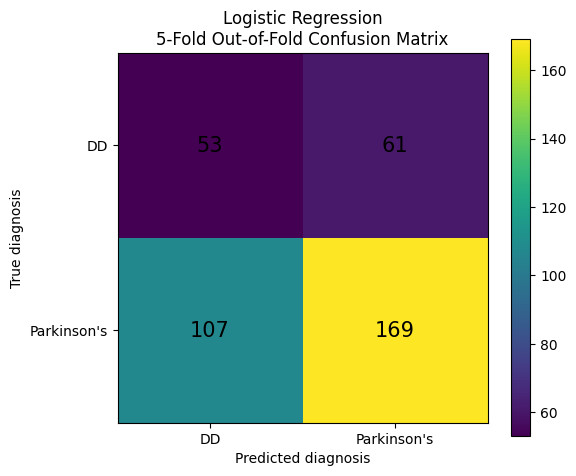

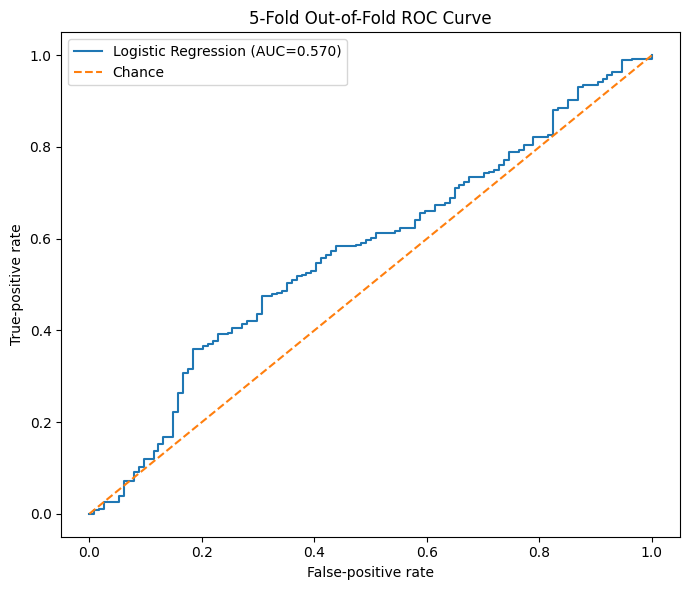

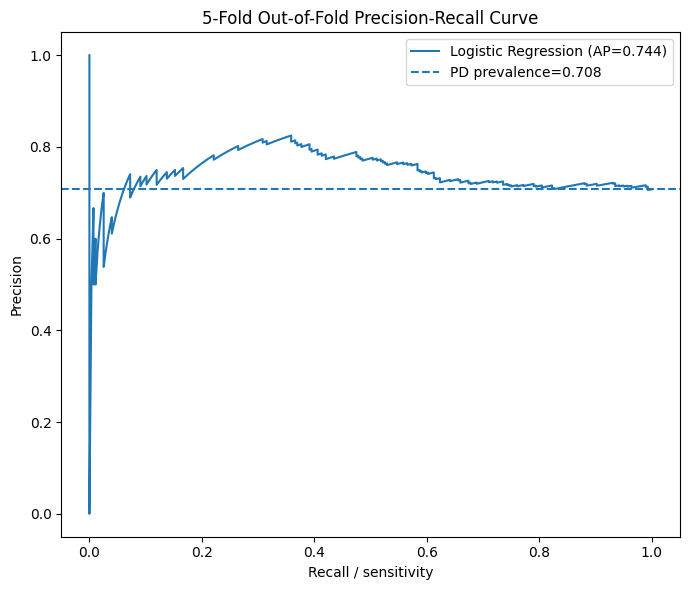

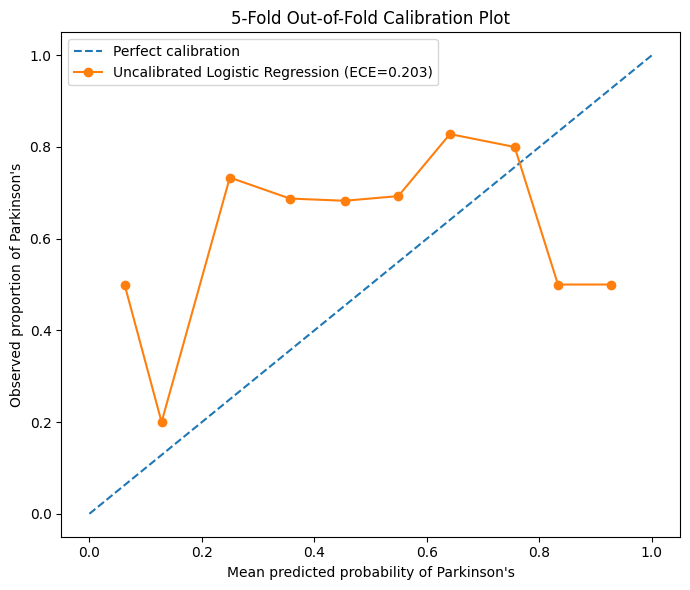

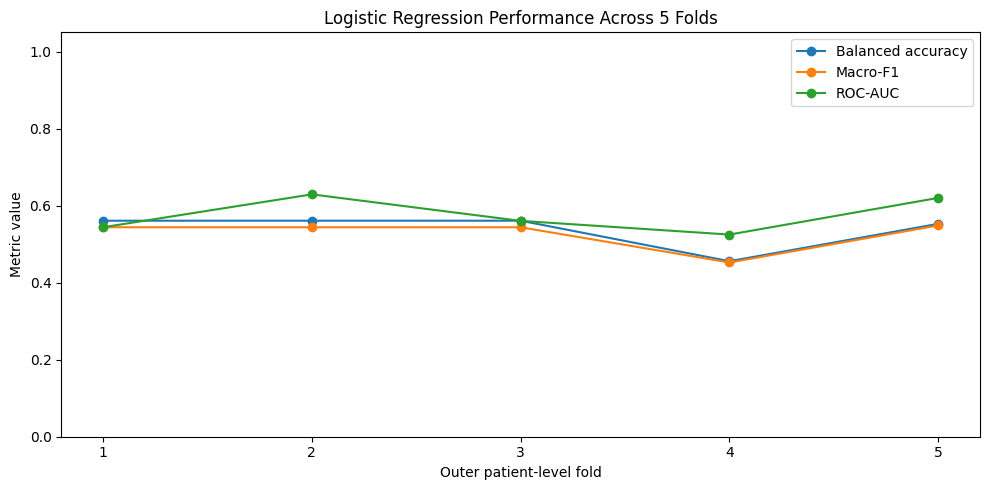

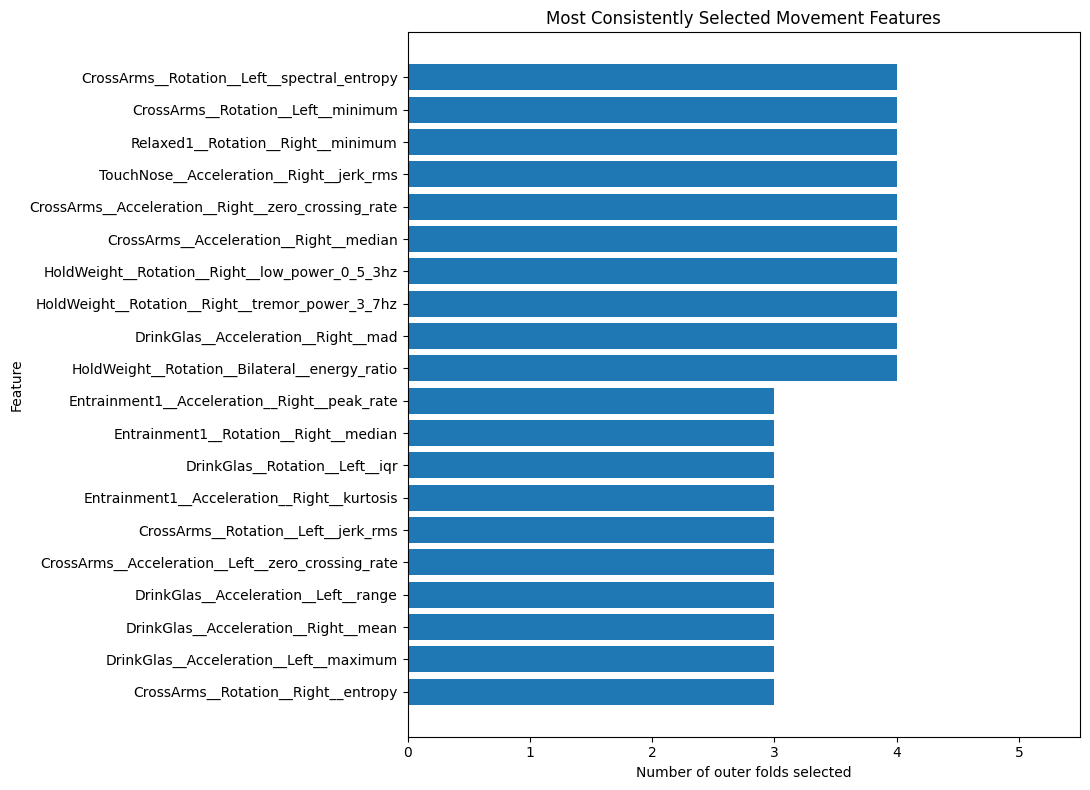


LOGISTIC REGRESSION 5-FOLD BASELINE COMPLETE

Out-of-fold classification report:

                        precision    recall  f1-score   support

Differential Diagnosis     0.3312    0.4649    0.3869       114
           Parkinson's     0.7348    0.6123    0.6680       276

              accuracy                         0.5692       390
             macro avg     0.5330    0.5386    0.5274       390
          weighted avg     0.6168    0.5692    0.5858       390


Overall out-of-fold metrics:

accuracy                 : 0.5692
balanced_accuracy        : 0.5386
macro_f1                 : 0.5274
pd_f1                    : 0.6680
dd_f1                    : 0.3869
precision_pd             : 0.7348
sensitivity_pd           : 0.6123
specificity_dd           : 0.4649
ppv_pd                   : 0.7348
npv_dd                   : 0.3312
roc_auc                  : 0.5701
pr_auc                   : 0.7438
brier_score              : 0.2504
ece_10_bins              : 0.2028
true_negative          

In [ ]:
# =====================================================================
# PADS FIRST BASELINE — LOGISTIC REGRESSION
# NESTED 5-FOLD PATIENT-LEVEL CROSS-VALIDATION
# =====================================================================
#
# PRIMARY TASK:
# Parkinson's disease (1) vs Differential Diagnosis (0)
#
# VALIDATION:
# Outer CV = 5 folds for final unbiased patient-level evaluation
# Inner CV = 3 folds for hyperparameter and feature-selection tuning
#
# CLASS BALANCE:
# 1. StratifiedKFold preserves the PD/DD proportion in every fold.
# 2. class_weight="balanced" gives more weight to the minority DD class.
# 3. No SMOTE, oversampling, undersampling or patient duplication.
#
# PRIMARY FEATURE SET:
# - Time-domain movement features
# - Frequency-domain movement features
# - Bilateral-asymmetry features
#
# EXCLUDED FROM THIS FIRST BASELINE:
# - Technical quality / spike features
# - Age, gender, height, weight and BMI
# - Questionnaire variables
#
# NOTE:
# Logistic Regression does not use epochs.
# max_iter is the optimization limit, not training epochs.
# =====================================================================

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    roc_curve,
    precision_recall_curve,
)

warnings.filterwarnings("ignore")

# =====================================================================
# 1. PATHS
# =====================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

FEATURE_FILE = (
    BASE_DIR
    / "project_ready_data"
    / "feature_engineering"
    / "pads_engineered_features.csv"
)

OUTPUT_DIR = (
    BASE_DIR
    / "project_ready_data"
    / "baseline_results"
    / "logistic_regression_5fold"
)

FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not FEATURE_FILE.exists():
    raise FileNotFoundError(
        f"Feature file not found:\n{FEATURE_FILE}\n\n"
        "Run the feature-engineering cell first."
    )

print("=" * 100)
print("LOGISTIC REGRESSION BASELINE")
print("NESTED 5-FOLD PATIENT-LEVEL CROSS-VALIDATION")
print("=" * 100)
print("Input :", FEATURE_FILE)
print("Output:", OUTPUT_DIR)

# =====================================================================
# 2. LOAD FEATURE DATA
# =====================================================================

df = pd.read_csv(
    FEATURE_FILE,
    dtype={"patient_id": str}
)

df["patient_id"] = (
    df["patient_id"]
    .astype(str)
    .str.zfill(3)
)

if "y" not in df.columns:
    raise ValueError("Target column 'y' is missing.")

if df["patient_id"].duplicated().any():
    duplicated = df.loc[
        df["patient_id"].duplicated(),
        "patient_id"
    ].tolist()

    raise ValueError(
        f"Duplicate patient IDs detected: {duplicated[:10]}"
    )

print("\nComplete feature table:", df.shape)
print("Unique patients:", df["patient_id"].nunique())
print("\nClass distribution:")
print(
    df["y"]
    .value_counts()
    .rename(index={0: "Differential Diagnosis", 1: "Parkinson's"})
)

# =====================================================================
# 3. SELECT MOVEMENT-ONLY FEATURES
# =====================================================================

# Labels, IDs and descriptive text
identifier_columns = {
    "patient_id",
    "y",
    "diagnosis_group",
    "original_condition",
    "gender",
    "handedness",
}

# Demographics excluded from the first movement-only baseline
demographic_columns = {
    "age",
    "height",
    "weight",
    "bmi",
    "gender_encoded",
    "handedness_encoded",
}

# Technical-quality features excluded from primary baseline
quality_patterns = [
    "__missing_ratio",
    "__flat_difference_ratio",
    "__spike_ratio",
    "__repeated_value_ratio",
    "__technical_quality_score",
    "mean_technical_quality",
]

def is_quality_feature(column_name):
    return any(
        pattern in column_name
        for pattern in quality_patterns
    )

feature_columns = []

for column in df.columns:

    if column in identifier_columns:
        continue

    if column in demographic_columns:
        continue

    if is_quality_feature(column):
        continue

    if not pd.api.types.is_numeric_dtype(df[column]):
        continue

    feature_columns.append(column)

X = df[feature_columns].copy()

# Any accidental infinite values become NaN.
# The fold-specific imputer will handle them.
X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

y = df["y"].astype(int).to_numpy()
patient_ids = df["patient_id"].to_numpy()

print("\nPrimary movement-only dataset:")
print("Patients:", X.shape[0])
print("Features:", X.shape[1])
print("Missing cells:", int(X.isna().sum().sum()))

if len(np.unique(patient_ids)) != len(patient_ids):
    raise RuntimeError(
        "Each feature-table row must represent one unique patient."
    )

# =====================================================================
# 4. EXPECTED CALIBRATION ERROR
# =====================================================================

def expected_calibration_error(
    y_true,
    probabilities,
    n_bins=10
):
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for bin_index in range(n_bins):

        lower = bin_edges[bin_index]
        upper = bin_edges[bin_index + 1]

        if bin_index == n_bins - 1:
            mask = (
                (probabilities >= lower)
                & (probabilities <= upper)
            )
        else:
            mask = (
                (probabilities >= lower)
                & (probabilities < upper)
            )

        if not np.any(mask):
            continue

        observed_rate = np.mean(y_true[mask])
        predicted_rate = np.mean(probabilities[mask])
        bin_weight = np.mean(mask)

        ece += (
            bin_weight
            * abs(observed_rate - predicted_rate)
        )

    return float(ece)

# =====================================================================
# 5. METRIC FUNCTION
# =====================================================================

def calculate_metrics(
    y_true,
    y_pred,
    probability_pd
):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    sensitivity_pd = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity_dd = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    ppv_pd = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    npv_dd = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "pd_f1": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),
        "dd_f1": f1_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),
        "precision_pd": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),
        "sensitivity_pd": sensitivity_pd,
        "specificity_dd": specificity_dd,
        "ppv_pd": ppv_pd,
        "npv_dd": npv_dd,
        "roc_auc": roc_auc_score(
            y_true,
            probability_pd
        ),
        "pr_auc": average_precision_score(
            y_true,
            probability_pd
        ),
        "brier_score": brier_score_loss(
            y_true,
            probability_pd
        ),
        "ece_10_bins": expected_calibration_error(
            y_true,
            probability_pd,
            n_bins=10
        ),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }

# =====================================================================
# 6. MODEL PIPELINE
# =====================================================================

# Every data-dependent preprocessing step is inside the pipeline.
# GridSearchCV therefore fits these operations on training folds only.

pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "variance_filter",
            VarianceThreshold(
                threshold=0.0
            )
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "feature_selector",
            SelectKBest(
                score_func=mutual_info_classif,
                k=50
            )
        ),
        (
            "classifier",
            LogisticRegression(
                solver="liblinear",

                # Automatically gives larger weight
                # to the minority DD class.
                class_weight="balanced",

                max_iter=5000,
                random_state=42
            )
        ),
    ]
)

candidate_k_values = [
    value
    for value in [25, 50, 100, 200]
    if value < X.shape[1]
]

candidate_k_values.append("all")

parameter_grid = {
    "feature_selector__k": candidate_k_values,
    "classifier__C": [
        0.001,
        0.01,
        0.1,
        1.0,
        10.0,
    ],
    "classifier__penalty": [
        "l1",
        "l2",
    ],
}

# =====================================================================
# 7. OUTER 5-FOLD AND INNER 3-FOLD CV
# =====================================================================

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=142
)

# Save the exact outer folds so all later models can use
# the same patient-level test assignments.
outer_split_rows = []

out_of_fold_probability = np.full(
    len(y),
    np.nan,
    dtype=float
)

out_of_fold_prediction = np.full(
    len(y),
    -1,
    dtype=int
)

fold_assignments = np.full(
    len(y),
    -1,
    dtype=int
)

fold_result_rows = []
best_parameter_rows = []
selected_feature_rows = []

print("\n" + "=" * 100)
print("STARTING NESTED 5-FOLD CROSS-VALIDATION")
print("=" * 100)

for fold_number, (
    train_indices,
    test_indices
) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    X_train = X.iloc[train_indices].copy()
    X_test = X.iloc[test_indices].copy()

    y_train = y[train_indices]
    y_test = y[test_indices]

    train_patient_ids = patient_ids[train_indices]
    test_patient_ids = patient_ids[test_indices]

    # -------------------------------------------------------------
    # Patient leakage verification
    # -------------------------------------------------------------

    overlap = set(train_patient_ids).intersection(
        set(test_patient_ids)
    )

    if overlap:
        raise RuntimeError(
            f"Patient leakage detected in fold {fold_number}: "
            f"{list(overlap)[:5]}"
        )

    # Save fold assignments for reuse
    for index in train_indices:
        outer_split_rows.append({
            "patient_id": patient_ids[index],
            "fold": fold_number,
            "role": "train",
            "true_label": int(y[index]),
        })

    for index in test_indices:
        outer_split_rows.append({
            "patient_id": patient_ids[index],
            "fold": fold_number,
            "role": "test",
            "true_label": int(y[index]),
        })

    # -------------------------------------------------------------
    # Inner hyperparameter tuning
    # -------------------------------------------------------------

    grid_search = GridSearchCV(
        estimator=clone(pipeline),
        param_grid=parameter_grid,

        # Main tuning metric because classes are imbalanced
        scoring="balanced_accuracy",

        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
        error_score="raise",
    )

    grid_search.fit(
        X_train,
        y_train
    )

    best_model = grid_search.best_estimator_

    # -------------------------------------------------------------
    # Untouched outer-fold test predictions
    # -------------------------------------------------------------

    test_probability = best_model.predict_proba(
        X_test
    )[:, 1]

    test_prediction = (
        test_probability >= 0.50
    ).astype(int)

    out_of_fold_probability[
        test_indices
    ] = test_probability

    out_of_fold_prediction[
        test_indices
    ] = test_prediction

    fold_assignments[
        test_indices
    ] = fold_number

    fold_metrics = calculate_metrics(
        y_test,
        test_prediction,
        test_probability
    )

    fold_metrics.update({
        "fold": fold_number,
        "train_patients": len(train_indices),
        "test_patients": len(test_indices),
        "train_pd": int(np.sum(y_train == 1)),
        "train_dd": int(np.sum(y_train == 0)),
        "test_pd": int(np.sum(y_test == 1)),
        "test_dd": int(np.sum(y_test == 0)),
        "best_inner_balanced_accuracy": float(
            grid_search.best_score_
        ),
    })

    fold_result_rows.append(
        fold_metrics
    )

    parameter_row = {
        "fold": fold_number,
        "best_inner_balanced_accuracy": float(
            grid_search.best_score_
        ),
    }

    parameter_row.update(
        grid_search.best_params_
    )

    best_parameter_rows.append(
        parameter_row
    )

    # -------------------------------------------------------------
    # Recover features selected in this outer fold
    # -------------------------------------------------------------

    variance_step = best_model.named_steps[
        "variance_filter"
    ]

    selector_step = best_model.named_steps[
        "feature_selector"
    ]

    names_after_variance = np.array(
        feature_columns
    )[
        variance_step.get_support()
    ]

    selected_names = names_after_variance[
        selector_step.get_support()
    ]

    for selected_name in selected_names:
        selected_feature_rows.append({
            "fold": fold_number,
            "feature_name": selected_name,
        })

    print("\n" + "-" * 70)
    print(f"OUTER FOLD {fold_number}/5")
    print("-" * 70)

    print(
        f"Training: {len(train_indices)} patients "
        f"(PD={np.sum(y_train == 1)}, DD={np.sum(y_train == 0)})"
    )

    print(
        f"Testing : {len(test_indices)} patients "
        f"(PD={np.sum(y_test == 1)}, DD={np.sum(y_test == 0)})"
    )

    print("Best parameters:")
    print(grid_search.best_params_)

    print(
        f"Balanced accuracy: "
        f"{fold_metrics['balanced_accuracy']:.4f}"
    )

    print(
        f"Macro-F1: "
        f"{fold_metrics['macro_f1']:.4f}"
    )

    print(
        f"Sensitivity PD: "
        f"{fold_metrics['sensitivity_pd']:.4f}"
    )

    print(
        f"Specificity DD: "
        f"{fold_metrics['specificity_dd']:.4f}"
    )

    print(
        f"ROC-AUC: "
        f"{fold_metrics['roc_auc']:.4f}"
    )

    print(
        f"PR-AUC: "
        f"{fold_metrics['pr_auc']:.4f}"
    )

# =====================================================================
# 8. VERIFY OUT-OF-FOLD RESULTS
# =====================================================================

if np.isnan(out_of_fold_probability).any():
    raise RuntimeError(
        "Some patients did not receive an out-of-fold probability."
    )

if np.any(out_of_fold_prediction < 0):
    raise RuntimeError(
        "Some patients did not receive an out-of-fold prediction."
    )

if np.any(fold_assignments < 1):
    raise RuntimeError(
        "Some patients were not assigned to an outer fold."
    )

# Every patient should appear once in outer testing.
test_counts = pd.Series(
    patient_ids
).value_counts()

if not (test_counts == 1).all():
    raise RuntimeError(
        "Patient-ID structure is invalid."
    )

overall_metrics = calculate_metrics(
    y,
    out_of_fold_prediction,
    out_of_fold_probability
)

# =====================================================================
# 9. PATIENT-LEVEL BOOTSTRAP 95% CONFIDENCE INTERVALS
# =====================================================================

rng = np.random.default_rng(42)

bootstrap_result_rows = []

N_BOOTSTRAPS = 2000
n_patients = len(y)

for bootstrap_number in range(N_BOOTSTRAPS):

    sampled_indices = rng.integers(
        low=0,
        high=n_patients,
        size=n_patients
    )

    sampled_y = y[sampled_indices]

    # Both classes are required for ROC-AUC.
    if len(np.unique(sampled_y)) < 2:
        continue

    sampled_predictions = out_of_fold_prediction[
        sampled_indices
    ]

    sampled_probabilities = out_of_fold_probability[
        sampled_indices
    ]

    bootstrap_result_rows.append(
        calculate_metrics(
            sampled_y,
            sampled_predictions,
            sampled_probabilities
        )
    )

bootstrap_df = pd.DataFrame(
    bootstrap_result_rows
)

metrics_for_confidence_intervals = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

confidence_interval_rows = []

for metric_name in metrics_for_confidence_intervals:

    metric_values = (
        bootstrap_df[metric_name]
        .dropna()
        .to_numpy()
    )

    confidence_interval_rows.append({
        "metric": metric_name,
        "value": overall_metrics[metric_name],
        "ci_95_lower": float(
            np.percentile(metric_values, 2.5)
        ),
        "ci_95_upper": float(
            np.percentile(metric_values, 97.5)
        ),
    })

confidence_intervals_df = pd.DataFrame(
    confidence_interval_rows
)

# =====================================================================
# 10. CREATE AND SAVE RESULT TABLES
# =====================================================================

fold_results_df = pd.DataFrame(
    fold_result_rows
)

best_parameters_df = pd.DataFrame(
    best_parameter_rows
)

selected_features_df = pd.DataFrame(
    selected_feature_rows
)

outer_splits_df = pd.DataFrame(
    outer_split_rows
)

if not selected_features_df.empty:

    feature_frequency_df = (
        selected_features_df
        .groupby("feature_name")
        .size()
        .reset_index(
            name="selected_in_folds"
        )
        .sort_values(
            [
                "selected_in_folds",
                "feature_name"
            ],
            ascending=[
                False,
                True
            ]
        )
    )

else:

    feature_frequency_df = pd.DataFrame(
        columns=[
            "feature_name",
            "selected_in_folds",
        ]
    )

patient_predictions_df = pd.DataFrame({
    "patient_id": patient_ids,
    "true_label": y,
    "true_group": np.where(
        y == 1,
        "Parkinson's",
        "Differential Diagnosis"
    ),
    "outer_fold": fold_assignments,
    "predicted_probability_pd": out_of_fold_probability,
    "predicted_label": out_of_fold_prediction,
    "predicted_group": np.where(
        out_of_fold_prediction == 1,
        "Parkinson's",
        "Differential Diagnosis"
    ),
    "correct_prediction": (
        out_of_fold_prediction == y
    ).astype(int),
})

summary_df = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "feature_set": (
            "Movement time-domain + frequency-domain "
            "+ bilateral-asymmetry"
        ),
        "quality_features_included": False,
        "demographics_included": False,
        "class_balance_method": (
            "Stratified folds + class_weight balanced"
        ),
        "oversampling_used": False,
        "patients": len(y),
        "pd_patients": int(np.sum(y == 1)),
        "dd_patients": int(np.sum(y == 0)),
        "outer_folds": 5,
        "inner_folds": 3,
        **overall_metrics,
    }
])

patient_predictions_df.to_csv(
    OUTPUT_DIR / "patient_predictions.csv",
    index=False
)

fold_results_df.to_csv(
    OUTPUT_DIR / "fold_results.csv",
    index=False
)

summary_df.to_csv(
    OUTPUT_DIR / "overall_summary.csv",
    index=False
)

confidence_intervals_df.to_csv(
    OUTPUT_DIR / "confidence_intervals_95.csv",
    index=False
)

best_parameters_df.to_csv(
    OUTPUT_DIR / "best_parameters_by_fold.csv",
    index=False
)

selected_features_df.to_csv(
    OUTPUT_DIR / "selected_features_by_fold.csv",
    index=False
)

feature_frequency_df.to_csv(
    OUTPUT_DIR / "feature_selection_frequency.csv",
    index=False
)

outer_splits_df.to_csv(
    OUTPUT_DIR / "fixed_outer_5fold_splits.csv",
    index=False
)

bootstrap_df.to_csv(
    OUTPUT_DIR / "bootstrap_metrics.csv",
    index=False
)

# =====================================================================
# 11. CONFUSION MATRIX
# =====================================================================

confusion = confusion_matrix(
    y,
    out_of_fold_prediction,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

plt.imshow(confusion)

plt.colorbar()

plt.xticks(
    [0, 1],
    ["DD", "Parkinson's"]
)

plt.yticks(
    [0, 1],
    ["DD", "Parkinson's"]
)

plt.xlabel("Predicted diagnosis")
plt.ylabel("True diagnosis")

plt.title(
    "Logistic Regression\n"
    "5-Fold Out-of-Fold Confusion Matrix"
)

for row in range(2):
    for column in range(2):

        plt.text(
            column,
            row,
            str(confusion[row, column]),
            ha="center",
            va="center",
            fontsize=15
        )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "01_confusion_matrix.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 12. ROC CURVE
# =====================================================================

fpr, tpr, _ = roc_curve(
    y,
    out_of_fold_probability
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=(
        f"Logistic Regression "
        f"(AUC={overall_metrics['roc_auc']:.3f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance"
)

plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")

plt.title(
    "5-Fold Out-of-Fold ROC Curve"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "02_roc_curve.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 13. PRECISION-RECALL CURVE
# =====================================================================

precision_values, recall_values, _ = (
    precision_recall_curve(
        y,
        out_of_fold_probability
    )
)

pd_prevalence = float(np.mean(y))

plt.figure(figsize=(7, 6))

plt.plot(
    recall_values,
    precision_values,
    label=(
        f"Logistic Regression "
        f"(AP={overall_metrics['pr_auc']:.3f})"
    )
)

plt.axhline(
    pd_prevalence,
    linestyle="--",
    label=f"PD prevalence={pd_prevalence:.3f}"
)

plt.xlabel("Recall / sensitivity")
plt.ylabel("Precision")

plt.title(
    "5-Fold Out-of-Fold Precision-Recall Curve"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "03_precision_recall_curve.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 14. CALIBRATION PLOT
# =====================================================================

N_BINS = 10
bin_edges = np.linspace(0, 1, N_BINS + 1)

mean_predicted_probabilities = []
observed_pd_rates = []
calibration_bin_counts = []

for bin_index in range(N_BINS):

    lower = bin_edges[bin_index]
    upper = bin_edges[bin_index + 1]

    if bin_index == N_BINS - 1:
        mask = (
            (out_of_fold_probability >= lower)
            & (out_of_fold_probability <= upper)
        )
    else:
        mask = (
            (out_of_fold_probability >= lower)
            & (out_of_fold_probability < upper)
        )

    if not np.any(mask):
        continue

    mean_predicted_probabilities.append(
        float(
            np.mean(
                out_of_fold_probability[mask]
            )
        )
    )

    observed_pd_rates.append(
        float(
            np.mean(y[mask])
        )
    )

    calibration_bin_counts.append(
        int(np.sum(mask))
    )

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    mean_predicted_probabilities,
    observed_pd_rates,
    marker="o",
    label=(
        f"Uncalibrated Logistic Regression "
        f"(ECE={overall_metrics['ece_10_bins']:.3f})"
    )
)

plt.xlabel(
    "Mean predicted probability of Parkinson's"
)

plt.ylabel(
    "Observed proportion of Parkinson's"
)

plt.title(
    "5-Fold Out-of-Fold Calibration Plot"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "04_calibration_plot.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 15. FOLD PERFORMANCE
# =====================================================================

plt.figure(figsize=(10, 5))

plt.plot(
    fold_results_df["fold"],
    fold_results_df["balanced_accuracy"],
    marker="o",
    label="Balanced accuracy"
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df["macro_f1"],
    marker="o",
    label="Macro-F1"
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df["roc_auc"],
    marker="o",
    label="ROC-AUC"
)

plt.xlabel("Outer patient-level fold")
plt.ylabel("Metric value")

plt.title(
    "Logistic Regression Performance Across 5 Folds"
)

plt.xticks([1, 2, 3, 4, 5])
plt.ylim(0, 1.05)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "05_fold_performance.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 16. MOST CONSISTENTLY SELECTED FEATURES
# =====================================================================

if not feature_frequency_df.empty:

    top_features = (
        feature_frequency_df
        .head(20)
        .sort_values(
            "selected_in_folds"
        )
    )

    plt.figure(figsize=(11, 8))

    plt.barh(
        top_features["feature_name"],
        top_features["selected_in_folds"]
    )

    plt.xlabel(
        "Number of outer folds selected"
    )

    plt.ylabel("Feature")

    plt.title(
        "Most Consistently Selected Movement Features"
    )

    plt.xlim(0, 5.5)

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR
        / "06_feature_selection_frequency.png",
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# =====================================================================
# 17. PRINT FINAL RESULTS
# =====================================================================

print("\n" + "=" * 100)
print("LOGISTIC REGRESSION 5-FOLD BASELINE COMPLETE")
print("=" * 100)

print("\nOut-of-fold classification report:\n")

print(
    classification_report(
        y,
        out_of_fold_prediction,
        target_names=[
            "Differential Diagnosis",
            "Parkinson's",
        ],
        digits=4,
        zero_division=0
    )
)

print("\nOverall out-of-fold metrics:\n")

for metric_name, metric_value in overall_metrics.items():

    if isinstance(metric_value, float):
        print(
            f"{metric_name:25s}: "
            f"{metric_value:.4f}"
        )
    else:
        print(
            f"{metric_name:25s}: "
            f"{metric_value}"
        )

print("\nBootstrap 95% confidence intervals:\n")

print(
    confidence_intervals_df
    .round(4)
    .to_string(index=False)
)

print("\nFold-level results:\n")

fold_display_columns = [
    "fold",
    "train_patients",
    "test_patients",
    "train_pd",
    "train_dd",
    "test_pd",
    "test_dd",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

print(
    fold_results_df[
        fold_display_columns
    ]
    .round(4)
    .to_string(index=False)
)

print("\nHow class imbalance was handled:")
print(
    "1. Stratified folds preserved the original PD/DD ratio."
)
print(
    '2. LogisticRegression(class_weight="balanced") '
    "gave greater loss weight to DD patients."
)
print(
    "3. No SMOTE, oversampling, undersampling or duplication was used."
)

print("\nFiles saved:")

for path in sorted(OUTPUT_DIR.rglob("*")):

    if path.is_file():
        print(
            " -",
            path.relative_to(OUTPUT_DIR)
        )

print("\nImportant:")
print(
    "- Every patient received exactly one out-of-fold prediction."
)
print(
    "- No patient appeared in training and testing within the same fold."
)
print(
    "- Imputation, constant-feature removal, scaling, "
    "feature selection and tuning were performed inside training folds."
)
print(
    "- The saved fixed_outer_5fold_splits.csv must be reused "
    "for all later baseline and proposed models."
)
print(
    "- This baseline is not probability-calibrated yet; "
    "the calibration plot only evaluates its original probabilities."
)

print("\n✅ FIRST 5-FOLD PATIENT-LEVEL BASELINE FINISHED.")

## RBF SVM

CORRECTED RBF SVM BASELINE
SAME FIXED 5-FOLD PATIENT-LEVEL VALIDATION
Feature file : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_engineered_features.csv
Fixed folds  : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv
Output folder: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/svm_rbf_corrected_5fold

Feature-table shape: (390, 1486)
Unique patients: 390

Class distribution:
y
Parkinson's               276
Differential Diagnosis    114
Name: count, dtype: int64

Fixed folds successfully verified.
Every patient appears as outer-test exactly once.

Primary movement-only input:
Patients: 390
Features: 1254
Missing cells: 0

Inner-CV parameter combinations:
36

STARTING CORRECTED FIXED 5-FOLD SVM TRAINING

-------------------------------------------

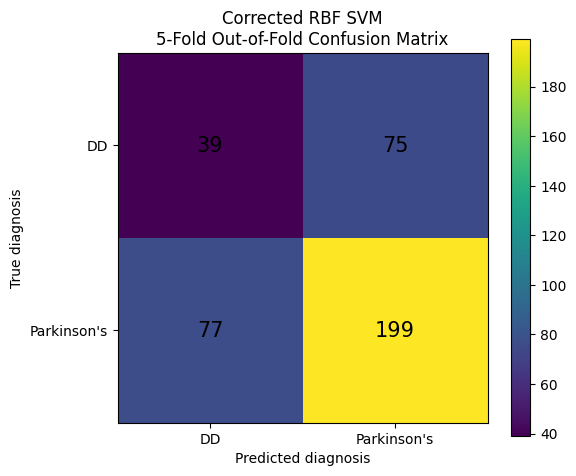

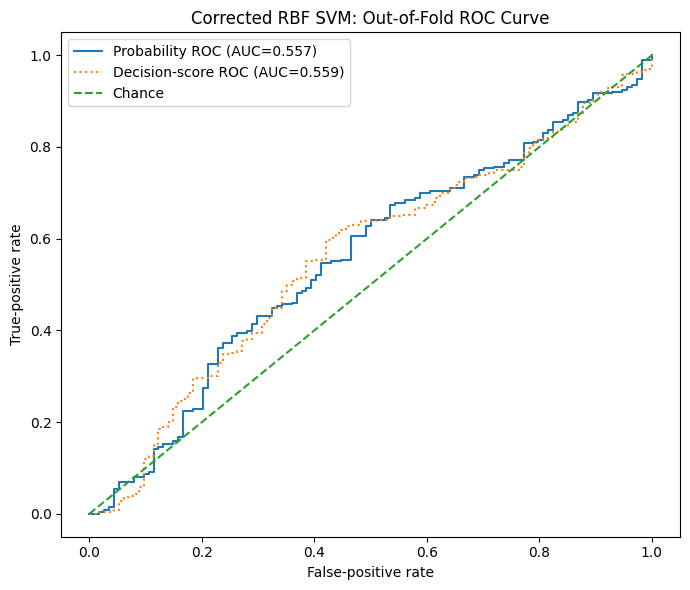

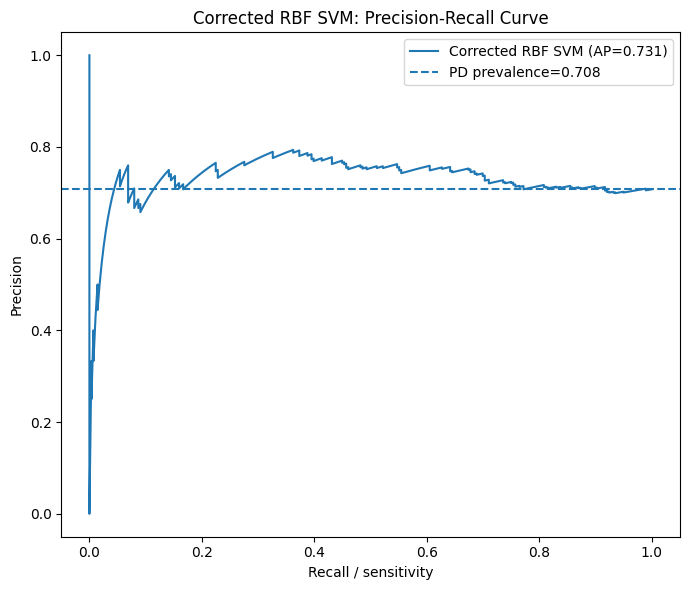

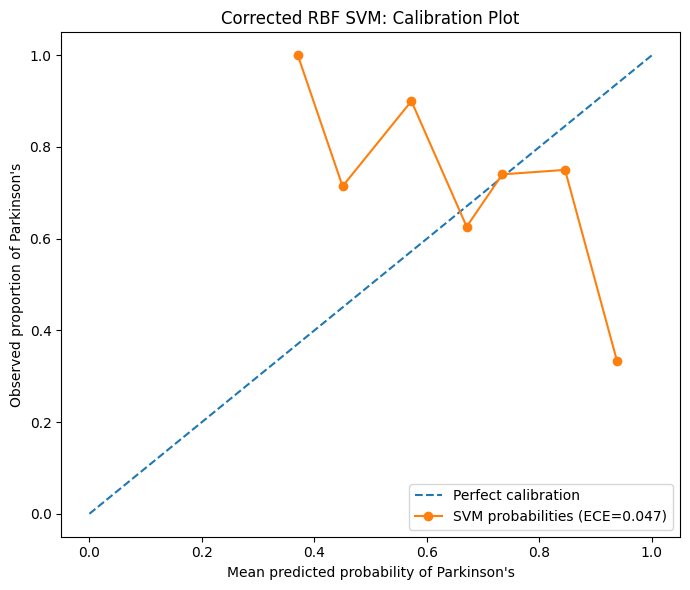

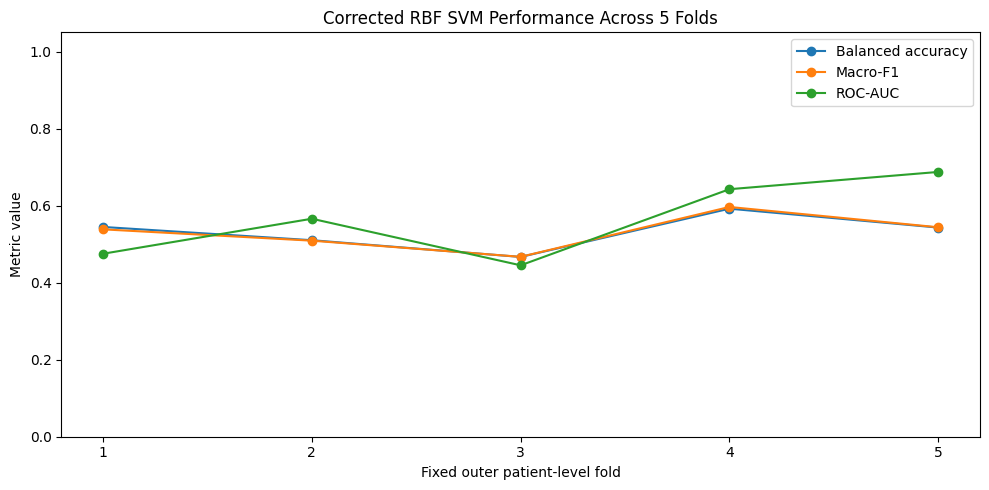

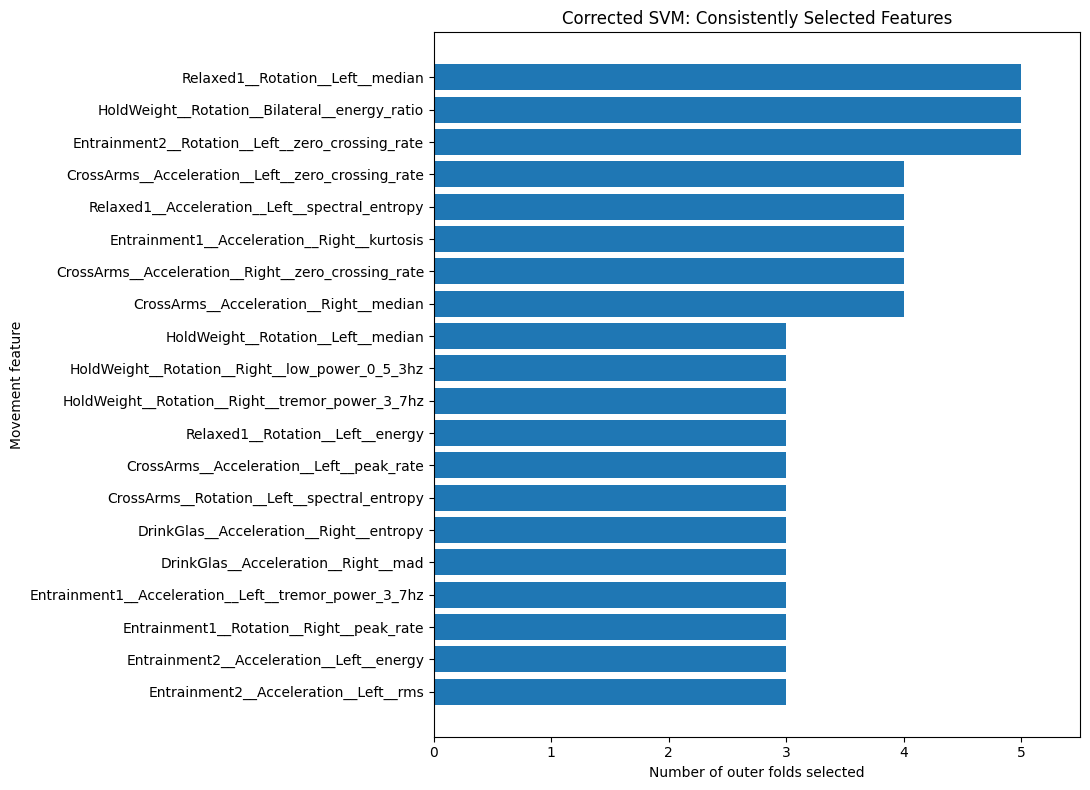


CORRECTED RBF SVM BASELINE COMPLETE

Out-of-fold classification report:

                        precision    recall  f1-score   support

Differential Diagnosis     0.3362    0.3421    0.3391       114
           Parkinson's     0.7263    0.7210    0.7236       276

              accuracy                         0.6103       390
             macro avg     0.5312    0.5316    0.5314       390
          weighted avg     0.6123    0.6103    0.6112       390


Overall out-of-fold metrics:

accuracy                 : 0.6103
balanced_accuracy        : 0.5316
macro_f1                 : 0.5314
pd_f1                    : 0.7236
dd_f1                    : 0.3391
precision_pd             : 0.7263
sensitivity_pd           : 0.7210
specificity_dd           : 0.3421
ppv_pd                   : 0.7263
npv_dd                   : 0.3362
roc_auc                  : 0.5569
pr_auc                   : 0.7314
brier_score              : 0.2112
ece_10_bins              : 0.0468
true_negative            : 39
fa

In [ ]:
# =====================================================================
# CORRECTED RBF SVM BASELINE
# SAME FIXED 5-FOLD PATIENT-LEVEL CROSS-VALIDATION
# =====================================================================
#
# CORRECTION:
#   Predicted labels = best_model.predict(X_test)
#   Probabilities    = best_model.predict_proba(X_test)[:, class_1_index]
#
# FAIR COMPARISON:
# - Same 390 patients
# - Same fixed outer 5 folds as Logistic Regression
# - Same inner 3-fold tuning
# - Same movement-only feature set
# - Same class-weight balancing
# - Same evaluation metrics
# - Same patient-level bootstrap confidence intervals
#
# IMPORTANT:
# SVM does not use epochs.
# =====================================================================

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    roc_curve,
    precision_recall_curve,
)

warnings.filterwarnings("ignore")

# =====================================================================
# 1. PATHS
# =====================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

FEATURE_FILE = (
    BASE_DIR
    / "project_ready_data"
    / "feature_engineering"
    / "pads_engineered_features.csv"
)

LOGISTIC_DIR = (
    BASE_DIR
    / "project_ready_data"
    / "baseline_results"
    / "logistic_regression_5fold"
)

FIXED_SPLIT_FILE = (
    LOGISTIC_DIR
    / "fixed_outer_5fold_splits.csv"
)

LOGISTIC_SUMMARY_FILE = (
    LOGISTIC_DIR
    / "overall_summary.csv"
)

OUTPUT_DIR = (
    BASE_DIR
    / "project_ready_data"
    / "baseline_results"
    / "svm_rbf_corrected_5fold"
)

FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not FEATURE_FILE.exists():
    raise FileNotFoundError(
        f"Feature file not found:\n{FEATURE_FILE}"
    )

if not FIXED_SPLIT_FILE.exists():
    raise FileNotFoundError(
        f"Fixed fold file not found:\n{FIXED_SPLIT_FILE}\n\n"
        "Run the Logistic Regression 5-fold baseline first."
    )

print("=" * 100)
print("CORRECTED RBF SVM BASELINE")
print("SAME FIXED 5-FOLD PATIENT-LEVEL VALIDATION")
print("=" * 100)

print("Feature file :", FEATURE_FILE)
print("Fixed folds  :", FIXED_SPLIT_FILE)
print("Output folder:", OUTPUT_DIR)

# =====================================================================
# 2. LOAD FEATURE TABLE AND FIXED FOLDS
# =====================================================================

df = pd.read_csv(
    FEATURE_FILE,
    dtype={"patient_id": str}
)

df["patient_id"] = (
    df["patient_id"]
    .astype(str)
    .str.zfill(3)
)

fixed_splits = pd.read_csv(
    FIXED_SPLIT_FILE,
    dtype={"patient_id": str}
)

fixed_splits["patient_id"] = (
    fixed_splits["patient_id"]
    .astype(str)
    .str.zfill(3)
)

fixed_splits["role"] = (
    fixed_splits["role"]
    .astype(str)
    .str.lower()
    .str.strip()
)

if "y" not in df.columns:
    raise ValueError("Target column 'y' is missing.")

if df["patient_id"].duplicated().any():
    duplicate_ids = df.loc[
        df["patient_id"].duplicated(),
        "patient_id"
    ].tolist()

    raise ValueError(
        f"Duplicate patient IDs detected: {duplicate_ids[:10]}"
    )

required_split_columns = {
    "patient_id",
    "fold",
    "role",
}

if not required_split_columns.issubset(
    fixed_splits.columns
):
    raise ValueError(
        "Fixed split file must contain patient_id, fold and role."
    )

print("\nFeature-table shape:", df.shape)
print("Unique patients:", df["patient_id"].nunique())

print("\nClass distribution:")

print(
    df["y"]
    .value_counts()
    .rename({
        0: "Differential Diagnosis",
        1: "Parkinson's",
    })
)

# =====================================================================
# 3. VERIFY FIXED FOLDS
# =====================================================================

data_patient_ids = set(df["patient_id"])
split_patient_ids = set(fixed_splits["patient_id"])

if data_patient_ids != split_patient_ids:

    missing_from_splits = (
        data_patient_ids - split_patient_ids
    )

    extra_in_splits = (
        split_patient_ids - data_patient_ids
    )

    raise ValueError(
        "Patient mismatch between feature table and fixed folds.\n"
        f"Missing from splits: {list(missing_from_splits)[:10]}\n"
        f"Extra in splits: {list(extra_in_splits)[:10]}"
    )

available_folds = sorted(
    fixed_splits["fold"].unique()
)

if available_folds != [1, 2, 3, 4, 5]:
    raise ValueError(
        f"Expected folds [1,2,3,4,5], found {available_folds}"
    )

test_rows = fixed_splits[
    fixed_splits["role"] == "test"
]

test_frequency = (
    test_rows
    .groupby("patient_id")
    .size()
)

if len(test_frequency) != len(df):
    raise ValueError(
        "Not all patients appear in the outer test folds."
    )

if not (test_frequency == 1).all():
    raise ValueError(
        "Every patient must appear as test exactly once."
    )

print("\nFixed folds successfully verified.")
print("Every patient appears as outer-test exactly once.")

# =====================================================================
# 4. SELECT EXACT SAME MOVEMENT-ONLY FEATURE SET
# =====================================================================

identifier_columns = {
    "patient_id",
    "y",
    "diagnosis_group",
    "original_condition",
    "gender",
    "handedness",
}

demographic_columns = {
    "age",
    "height",
    "weight",
    "bmi",
    "gender_encoded",
    "handedness_encoded",
}

quality_patterns = [
    "__missing_ratio",
    "__flat_difference_ratio",
    "__spike_ratio",
    "__repeated_value_ratio",
    "__technical_quality_score",
    "mean_technical_quality",
]

def is_quality_feature(column_name):
    return any(
        pattern in column_name
        for pattern in quality_patterns
    )

feature_columns = []

for column in df.columns:

    if column in identifier_columns:
        continue

    if column in demographic_columns:
        continue

    if is_quality_feature(column):
        continue

    if not pd.api.types.is_numeric_dtype(
        df[column]
    ):
        continue

    feature_columns.append(column)

X = df[feature_columns].copy()

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

y = df["y"].astype(int).to_numpy()

patient_ids = (
    df["patient_id"]
    .astype(str)
    .to_numpy()
)

patient_to_index = {
    patient_id: index
    for index, patient_id in enumerate(patient_ids)
}

print("\nPrimary movement-only input:")
print("Patients:", X.shape[0])
print("Features:", X.shape[1])
print("Missing cells:", int(X.isna().sum().sum()))

if X.shape[0] != 390:
    print(
        f"Warning: expected 390 patients, found {X.shape[0]}."
    )

# =====================================================================
# 5. EXPECTED CALIBRATION ERROR
# =====================================================================

def expected_calibration_error(
    y_true,
    probability_pd,
    n_bins=10
):
    y_true = np.asarray(y_true)
    probability_pd = np.asarray(probability_pd)

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for bin_index in range(n_bins):

        lower = bin_edges[bin_index]
        upper = bin_edges[bin_index + 1]

        if bin_index == n_bins - 1:

            bin_mask = (
                (probability_pd >= lower)
                & (probability_pd <= upper)
            )

        else:

            bin_mask = (
                (probability_pd >= lower)
                & (probability_pd < upper)
            )

        if not np.any(bin_mask):
            continue

        mean_predicted_probability = np.mean(
            probability_pd[bin_mask]
        )

        observed_pd_rate = np.mean(
            y_true[bin_mask]
        )

        bin_weight = np.mean(bin_mask)

        ece += (
            bin_weight
            * abs(
                observed_pd_rate
                - mean_predicted_probability
            )
        )

    return float(ece)

# =====================================================================
# 6. SHARED EVALUATION FUNCTION
# =====================================================================

def calculate_metrics(
    y_true,
    y_pred,
    probability_pd
):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    sensitivity_pd = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity_dd = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    ppv_pd = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    npv_dd = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "pd_f1": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "dd_f1": f1_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "precision_pd": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "sensitivity_pd": sensitivity_pd,
        "specificity_dd": specificity_dd,
        "ppv_pd": ppv_pd,
        "npv_dd": npv_dd,

        "roc_auc": roc_auc_score(
            y_true,
            probability_pd
        ),

        "pr_auc": average_precision_score(
            y_true,
            probability_pd
        ),

        "brier_score": brier_score_loss(
            y_true,
            probability_pd
        ),

        "ece_10_bins": expected_calibration_error(
            y_true,
            probability_pd,
            n_bins=10
        ),

        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }

# =====================================================================
# 7. CORRECTED SVM PIPELINE
# =====================================================================

pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "variance_filter",
            VarianceThreshold(
                threshold=0.0
            )
        ),

        (
            "scaler",
            StandardScaler()
        ),

        (
            "feature_selector",
            SelectKBest(
                score_func=mutual_info_classif,
                k=50
            )
        ),

        (
            "classifier",
            SVC(
                kernel="rbf",

                # Minority DD class receives greater weight.
                class_weight="balanced",

                # Required for probability-based metrics.
                probability=True,

                cache_size=2000,
                random_state=42
            )
        ),
    ]
)

candidate_k_values = [
    value
    for value in [
        25,
        50,
        100,
        200,
    ]
    if value < X.shape[1]
]

parameter_grid = {
    "feature_selector__k": candidate_k_values,

    "classifier__C": [
        0.1,
        1.0,
        10.0,
    ],

    "classifier__gamma": [
        "scale",
        0.001,
        0.01,
    ],
}

inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=142
)

number_of_parameter_combinations = (
    len(parameter_grid["feature_selector__k"])
    * len(parameter_grid["classifier__C"])
    * len(parameter_grid["classifier__gamma"])
)

print("\nInner-CV parameter combinations:")
print(number_of_parameter_combinations)

# =====================================================================
# 8. FIXED OUTER 5-FOLD TRAINING
# =====================================================================

out_of_fold_probability = np.full(
    len(y),
    np.nan,
    dtype=float
)

out_of_fold_prediction = np.full(
    len(y),
    -1,
    dtype=int
)

out_of_fold_decision_score = np.full(
    len(y),
    np.nan,
    dtype=float
)

fold_assignments = np.full(
    len(y),
    -1,
    dtype=int
)

fold_result_rows = []
best_parameter_rows = []
selected_feature_rows = []

print("\n" + "=" * 100)
print("STARTING CORRECTED FIXED 5-FOLD SVM TRAINING")
print("=" * 100)

for fold_number in available_folds:

    current_fold = fixed_splits[
        fixed_splits["fold"] == fold_number
    ]

    train_ids = current_fold.loc[
        current_fold["role"] == "train",
        "patient_id"
    ].tolist()

    test_ids = current_fold.loc[
        current_fold["role"] == "test",
        "patient_id"
    ].tolist()

    train_id_set = set(train_ids)
    test_id_set = set(test_ids)

    overlap = train_id_set.intersection(
        test_id_set
    )

    if overlap:
        raise RuntimeError(
            f"Patient leakage in fold {fold_number}: "
            f"{list(overlap)[:5]}"
        )

    train_indices = np.array([
        patient_to_index[patient_id]
        for patient_id in train_ids
    ])

    test_indices = np.array([
        patient_to_index[patient_id]
        for patient_id in test_ids
    ])

    X_train = X.iloc[
        train_indices
    ].copy()

    X_test = X.iloc[
        test_indices
    ].copy()

    y_train = y[train_indices]
    y_test = y[test_indices]

    grid_search = GridSearchCV(
        estimator=clone(pipeline),
        param_grid=parameter_grid,

        # Same tuning metric used in Logistic Regression.
        scoring="balanced_accuracy",

        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
        error_score="raise",
        verbose=0
    )

    grid_search.fit(
        X_train,
        y_train
    )

    best_model = grid_search.best_estimator_

    # ================================================================
    # CORRECTED PREDICTION LOGIC
    # ================================================================

    # Classification uses the actual SVM decision boundary.
    test_prediction = best_model.predict(
        X_test
    ).astype(int)

    # Probabilities are used only for probability-based evaluation.
    probability_matrix = best_model.predict_proba(
        X_test
    )

    classifier_classes = (
        best_model
        .named_steps["classifier"]
        .classes_
    )

    pd_probability_column = int(
        np.where(
            classifier_classes == 1
        )[0][0]
    )

    test_probability = probability_matrix[
        :,
        pd_probability_column
    ]

    test_decision_score = best_model.decision_function(
        X_test
    )

    out_of_fold_prediction[
        test_indices
    ] = test_prediction

    out_of_fold_probability[
        test_indices
    ] = test_probability

    out_of_fold_decision_score[
        test_indices
    ] = test_decision_score

    fold_assignments[
        test_indices
    ] = int(fold_number)

    fold_metrics = calculate_metrics(
        y_test,
        test_prediction,
        test_probability
    )

    fold_metrics.update({
        "fold": int(fold_number),

        "train_patients": len(train_indices),
        "test_patients": len(test_indices),

        "train_pd": int(
            np.sum(y_train == 1)
        ),

        "train_dd": int(
            np.sum(y_train == 0)
        ),

        "test_pd": int(
            np.sum(y_test == 1)
        ),

        "test_dd": int(
            np.sum(y_test == 0)
        ),

        "best_inner_balanced_accuracy": float(
            grid_search.best_score_
        ),
    })

    fold_result_rows.append(
        fold_metrics
    )

    parameter_row = {
        "fold": int(fold_number),

        "best_inner_balanced_accuracy": float(
            grid_search.best_score_
        ),
    }

    parameter_row.update(
        grid_search.best_params_
    )

    best_parameter_rows.append(
        parameter_row
    )

    # ================================================================
    # SAVE SELECTED FEATURES
    # ================================================================

    variance_step = (
        best_model
        .named_steps["variance_filter"]
    )

    selector_step = (
        best_model
        .named_steps["feature_selector"]
    )

    names_after_variance = np.array(
        feature_columns
    )[
        variance_step.get_support()
    ]

    selected_names = names_after_variance[
        selector_step.get_support()
    ]

    for feature_name in selected_names:

        selected_feature_rows.append({
            "fold": int(fold_number),
            "feature_name": feature_name,
        })

    print("\n" + "-" * 74)
    print(f"OUTER FOLD {fold_number}/5")
    print("-" * 74)

    print(
        f"Training: {len(train_indices)} "
        f"(PD={np.sum(y_train == 1)}, "
        f"DD={np.sum(y_train == 0)})"
    )

    print(
        f"Testing : {len(test_indices)} "
        f"(PD={np.sum(y_test == 1)}, "
        f"DD={np.sum(y_test == 0)})"
    )

    print("\nBest parameters:")
    print(grid_search.best_params_)

    print(
        f"\nBalanced accuracy: "
        f"{fold_metrics['balanced_accuracy']:.4f}"
    )

    print(
        f"Macro-F1: "
        f"{fold_metrics['macro_f1']:.4f}"
    )

    print(
        f"Sensitivity PD: "
        f"{fold_metrics['sensitivity_pd']:.4f}"
    )

    print(
        f"Specificity DD: "
        f"{fold_metrics['specificity_dd']:.4f}"
    )

    print(
        f"ROC-AUC: "
        f"{fold_metrics['roc_auc']:.4f}"
    )

    print(
        f"PR-AUC: "
        f"{fold_metrics['pr_auc']:.4f}"
    )

    print(
        f"Confusion: TN={fold_metrics['true_negative']}, "
        f"FP={fold_metrics['false_positive']}, "
        f"FN={fold_metrics['false_negative']}, "
        f"TP={fold_metrics['true_positive']}"
    )

# =====================================================================
# 9. VERIFY COMPLETE OUT-OF-FOLD EVALUATION
# =====================================================================

if np.isnan(
    out_of_fold_probability
).any():

    raise RuntimeError(
        "Some patients did not receive probability predictions."
    )

if np.isnan(
    out_of_fold_decision_score
).any():

    raise RuntimeError(
        "Some patients did not receive decision scores."
    )

if np.any(
    out_of_fold_prediction < 0
):

    raise RuntimeError(
        "Some patients did not receive class predictions."
    )

if np.any(
    fold_assignments < 1
):

    raise RuntimeError(
        "Some patients were not assigned to an outer fold."
    )

overall_metrics = calculate_metrics(
    y,
    out_of_fold_prediction,
    out_of_fold_probability
)

# Additional AUC from the raw SVM decision score
decision_score_roc_auc = roc_auc_score(
    y,
    out_of_fold_decision_score
)

decision_score_pr_auc = average_precision_score(
    y,
    out_of_fold_decision_score
)

# =====================================================================
# 10. PATIENT-LEVEL BOOTSTRAP 95% CONFIDENCE INTERVALS
# =====================================================================

rng = np.random.default_rng(42)

N_BOOTSTRAPS = 2000

bootstrap_rows = []

for bootstrap_index in range(
    N_BOOTSTRAPS
):

    sampled_indices = rng.integers(
        low=0,
        high=len(y),
        size=len(y)
    )

    sampled_y = y[
        sampled_indices
    ]

    if len(
        np.unique(sampled_y)
    ) < 2:
        continue

    sampled_prediction = (
        out_of_fold_prediction[
            sampled_indices
        ]
    )

    sampled_probability = (
        out_of_fold_probability[
            sampled_indices
        ]
    )

    bootstrap_metrics = calculate_metrics(
        sampled_y,
        sampled_prediction,
        sampled_probability
    )

    bootstrap_rows.append(
        bootstrap_metrics
    )

bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

metrics_for_ci = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

confidence_interval_rows = []

for metric_name in metrics_for_ci:

    values = (
        bootstrap_df[metric_name]
        .dropna()
        .to_numpy()
    )

    confidence_interval_rows.append({
        "metric": metric_name,

        "value": overall_metrics[
            metric_name
        ],

        "ci_95_lower": float(
            np.percentile(
                values,
                2.5
            )
        ),

        "ci_95_upper": float(
            np.percentile(
                values,
                97.5
            )
        ),
    })

confidence_intervals_df = pd.DataFrame(
    confidence_interval_rows
)

# =====================================================================
# 11. CREATE RESULT TABLES
# =====================================================================

fold_results_df = pd.DataFrame(
    fold_result_rows
)

best_parameters_df = pd.DataFrame(
    best_parameter_rows
)

selected_features_df = pd.DataFrame(
    selected_feature_rows
)

if not selected_features_df.empty:

    feature_frequency_df = (
        selected_features_df
        .groupby("feature_name")
        .size()
        .reset_index(
            name="selected_in_folds"
        )
        .sort_values(
            [
                "selected_in_folds",
                "feature_name"
            ],
            ascending=[
                False,
                True
            ]
        )
    )

else:

    feature_frequency_df = pd.DataFrame(
        columns=[
            "feature_name",
            "selected_in_folds",
        ]
    )

patient_predictions_df = pd.DataFrame({
    "patient_id": patient_ids,

    "true_label": y,

    "true_group": np.where(
        y == 1,
        "Parkinson's",
        "Differential Diagnosis"
    ),

    "outer_fold": fold_assignments,

    "svm_decision_score": (
        out_of_fold_decision_score
    ),

    "predicted_probability_pd": (
        out_of_fold_probability
    ),

    "predicted_label": (
        out_of_fold_prediction
    ),

    "predicted_group": np.where(
        out_of_fold_prediction == 1,
        "Parkinson's",
        "Differential Diagnosis"
    ),

    "correct_prediction": (
        out_of_fold_prediction == y
    ).astype(int),
})

summary_df = pd.DataFrame([
    {
        "model": "Corrected RBF SVM",

        "prediction_rule": (
            "SVC.predict for labels; "
            "predict_proba for probability metrics"
        ),

        "feature_set": (
            "Movement time-domain + frequency-domain "
            "+ bilateral-asymmetry"
        ),

        "quality_features_included": False,
        "demographics_included": False,

        "class_balance_method": (
            "Same fixed stratified folds "
            "+ class_weight balanced"
        ),

        "oversampling_used": False,

        "patients": len(y),
        "pd_patients": int(np.sum(y == 1)),
        "dd_patients": int(np.sum(y == 0)),

        "outer_folds": 5,
        "inner_folds": 3,

        "decision_score_roc_auc": (
            decision_score_roc_auc
        ),

        "decision_score_pr_auc": (
            decision_score_pr_auc
        ),

        **overall_metrics,
    }
])

# =====================================================================
# 12. SAVE RESULT FILES
# =====================================================================

patient_predictions_df.to_csv(
    OUTPUT_DIR
    / "patient_predictions.csv",
    index=False
)

fold_results_df.to_csv(
    OUTPUT_DIR
    / "fold_results.csv",
    index=False
)

summary_df.to_csv(
    OUTPUT_DIR
    / "overall_summary.csv",
    index=False
)

confidence_intervals_df.to_csv(
    OUTPUT_DIR
    / "confidence_intervals_95.csv",
    index=False
)

best_parameters_df.to_csv(
    OUTPUT_DIR
    / "best_parameters_by_fold.csv",
    index=False
)

selected_features_df.to_csv(
    OUTPUT_DIR
    / "selected_features_by_fold.csv",
    index=False
)

feature_frequency_df.to_csv(
    OUTPUT_DIR
    / "feature_selection_frequency.csv",
    index=False
)

bootstrap_df.to_csv(
    OUTPUT_DIR
    / "bootstrap_metrics.csv",
    index=False
)

# =====================================================================
# 13. CONFUSION MATRIX
# =====================================================================

cm = confusion_matrix(
    y,
    out_of_fold_prediction,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

plt.imshow(cm)
plt.colorbar()

plt.xticks(
    [0, 1],
    ["DD", "Parkinson's"]
)

plt.yticks(
    [0, 1],
    ["DD", "Parkinson's"]
)

plt.xlabel("Predicted diagnosis")
plt.ylabel("True diagnosis")

plt.title(
    "Corrected RBF SVM\n"
    "5-Fold Out-of-Fold Confusion Matrix"
)

for row in range(2):

    for column in range(2):

        plt.text(
            column,
            row,
            str(cm[row, column]),
            ha="center",
            va="center",
            fontsize=15
        )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "01_confusion_matrix.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 14. ROC CURVE
# =====================================================================

fpr_probability, tpr_probability, _ = roc_curve(
    y,
    out_of_fold_probability
)

fpr_decision, tpr_decision, _ = roc_curve(
    y,
    out_of_fold_decision_score
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_probability,
    tpr_probability,
    label=(
        f"Probability ROC "
        f"(AUC={overall_metrics['roc_auc']:.3f})"
    )
)

plt.plot(
    fpr_decision,
    tpr_decision,
    linestyle=":",
    label=(
        f"Decision-score ROC "
        f"(AUC={decision_score_roc_auc:.3f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance"
)

plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")

plt.title(
    "Corrected RBF SVM: Out-of-Fold ROC Curve"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "02_roc_curve.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 15. PRECISION-RECALL CURVE
# =====================================================================

precision_values, recall_values, _ = (
    precision_recall_curve(
        y,
        out_of_fold_probability
    )
)

pd_prevalence = float(
    np.mean(y)
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall_values,
    precision_values,
    label=(
        f"Corrected RBF SVM "
        f"(AP={overall_metrics['pr_auc']:.3f})"
    )
)

plt.axhline(
    pd_prevalence,
    linestyle="--",
    label=(
        f"PD prevalence={pd_prevalence:.3f}"
    )
)

plt.xlabel("Recall / sensitivity")
plt.ylabel("Precision")

plt.title(
    "Corrected RBF SVM: Precision-Recall Curve"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "03_precision_recall_curve.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 16. CALIBRATION PLOT
# =====================================================================

N_BINS = 10

bin_edges = np.linspace(
    0,
    1,
    N_BINS + 1
)

mean_probabilities = []
observed_pd_rates = []
bin_counts = []

for bin_index in range(N_BINS):

    lower = bin_edges[bin_index]
    upper = bin_edges[bin_index + 1]

    if bin_index == N_BINS - 1:

        bin_mask = (
            (out_of_fold_probability >= lower)
            & (out_of_fold_probability <= upper)
        )

    else:

        bin_mask = (
            (out_of_fold_probability >= lower)
            & (out_of_fold_probability < upper)
        )

    if not np.any(bin_mask):
        continue

    mean_probabilities.append(
        float(
            np.mean(
                out_of_fold_probability[
                    bin_mask
                ]
            )
        )
    )

    observed_pd_rates.append(
        float(
            np.mean(
                y[bin_mask]
            )
        )
    )

    bin_counts.append(
        int(np.sum(bin_mask))
    )

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    mean_probabilities,
    observed_pd_rates,
    marker="o",
    label=(
        f"SVM probabilities "
        f"(ECE={overall_metrics['ece_10_bins']:.3f})"
    )
)

plt.xlabel(
    "Mean predicted probability of Parkinson's"
)

plt.ylabel(
    "Observed proportion of Parkinson's"
)

plt.title(
    "Corrected RBF SVM: Calibration Plot"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "04_calibration_plot.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 17. FOLD PERFORMANCE
# =====================================================================

plt.figure(figsize=(10, 5))

plt.plot(
    fold_results_df["fold"],
    fold_results_df["balanced_accuracy"],
    marker="o",
    label="Balanced accuracy"
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df["macro_f1"],
    marker="o",
    label="Macro-F1"
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df["roc_auc"],
    marker="o",
    label="ROC-AUC"
)

plt.xlabel("Fixed outer patient-level fold")
plt.ylabel("Metric value")

plt.title(
    "Corrected RBF SVM Performance Across 5 Folds"
)

plt.xticks([1, 2, 3, 4, 5])
plt.ylim(0, 1.05)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "05_fold_performance.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 18. SELECTED FEATURE FREQUENCY
# =====================================================================

if not feature_frequency_df.empty:

    top_features = (
        feature_frequency_df
        .head(20)
        .sort_values(
            "selected_in_folds"
        )
    )

    plt.figure(figsize=(11, 8))

    plt.barh(
        top_features["feature_name"],
        top_features["selected_in_folds"]
    )

    plt.xlabel(
        "Number of outer folds selected"
    )

    plt.ylabel("Movement feature")

    plt.title(
        "Corrected SVM: Consistently Selected Features"
    )

    plt.xlim(0, 5.5)

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR
        / "06_feature_selection_frequency.png",
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# =====================================================================
# 19. FAIR COMPARISON WITH LOGISTIC REGRESSION
# =====================================================================

comparison_rows = []

if LOGISTIC_SUMMARY_FILE.exists():

    logistic_summary = pd.read_csv(
        LOGISTIC_SUMMARY_FILE
    )

    logistic_row = (
        logistic_summary
        .iloc[0]
        .to_dict()
    )

    comparison_rows.append(
        logistic_row
    )

comparison_rows.append(
    summary_df.iloc[0].to_dict()
)

comparison_df = pd.DataFrame(
    comparison_rows
)

comparison_columns = [
    "model",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

available_comparison_columns = [
    column
    for column in comparison_columns
    if column in comparison_df.columns
]

comparison_df.to_csv(
    OUTPUT_DIR
    / "comparison_with_logistic_regression.csv",
    index=False
)

# =====================================================================
# 20. FINAL PRINTED RESULTS
# =====================================================================

print("\n" + "=" * 100)
print("CORRECTED RBF SVM BASELINE COMPLETE")
print("=" * 100)

print("\nOut-of-fold classification report:\n")

print(
    classification_report(
        y,
        out_of_fold_prediction,
        target_names=[
            "Differential Diagnosis",
            "Parkinson's",
        ],
        digits=4,
        zero_division=0
    )
)

print("\nOverall out-of-fold metrics:\n")

for metric_name, metric_value in overall_metrics.items():

    if isinstance(
        metric_value,
        (float, np.floating)
    ):

        print(
            f"{metric_name:25s}: "
            f"{metric_value:.4f}"
        )

    else:

        print(
            f"{metric_name:25s}: "
            f"{metric_value}"
        )

print(
    f"\ndecision_score_roc_auc   : "
    f"{decision_score_roc_auc:.4f}"
)

print(
    f"decision_score_pr_auc    : "
    f"{decision_score_pr_auc:.4f}"
)

print("\nBootstrap 95% confidence intervals:\n")

print(
    confidence_intervals_df
    .round(4)
    .to_string(index=False)
)

print("\nFold-level results:\n")

display_columns = [
    "fold",
    "train_patients",
    "test_patients",
    "train_pd",
    "train_dd",
    "test_pd",
    "test_dd",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

print(
    fold_results_df[
        display_columns
    ]
    .round(4)
    .to_string(index=False)
)

if len(comparison_df) > 1:

    print(
        "\nFair comparison with Logistic Regression:\n"
    )

    print(
        comparison_df[
            available_comparison_columns
        ]
        .round(4)
        .to_string(index=False)
    )

print("\nCorrection used:")
print(
    "- Classification labels came from SVC.predict()."
)
print(
    "- Probabilities came from SVC.predict_proba() "
    "only for probability metrics."
)

print("\nFair-comparison controls:")
print(
    "- Same patients and same fixed outer 5 folds."
)
print(
    "- Same inner 3-fold tuning procedure."
)
print(
    "- Same movement-only feature family."
)
print(
    "- Same class-weight balancing."
)
print(
    "- Same primary metrics and bootstrap procedure."
)
print(
    "- No SMOTE, oversampling or patient duplication."
)

print("\nSaved files:")

for path in sorted(
    OUTPUT_DIR.rglob("*")
):

    if path.is_file():

        print(
            " -",
            path.relative_to(
                OUTPUT_DIR
            )
        )

print("\nImportant scientific note:")
print(
    "- SVC probability=True performs internal probability fitting."
)
print(
    "- Therefore Brier score and ECE are reported, but final "
    "clinical calibration will later be performed consistently "
    "for the selected best model."
)
print(
    "- Balanced accuracy, macro-F1, sensitivity and specificity "
    "are the main comparison metrics at this stage."
)

print("\n✅ CORRECTED SVM EVALUATION FINISHED.")s

## Random forest

RANDOM FOREST BASELINE
SAME FIXED 5-FOLD PATIENT-LEVEL VALIDATION
Feature file : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_engineered_features.csv
Fixed folds  : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv
Output folder: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/random_forest_5fold

Feature-table shape: (390, 1486)
Unique patients: 390

Class distribution:
y
Parkinson's               276
Differential Diagnosis    114
Name: count, dtype: int64

Fixed folds successfully verified.
Every patient appears as outer-test exactly once.

Primary movement-only input:
Patients: 390
Features: 1254
Missing cells: 0

Inner-CV parameter combinations:
64

Random Forest can take several minutes because each fold performs inner hyperparameter tuning.

S

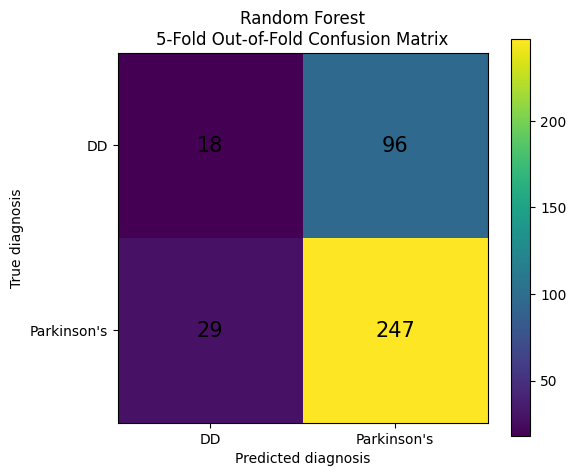

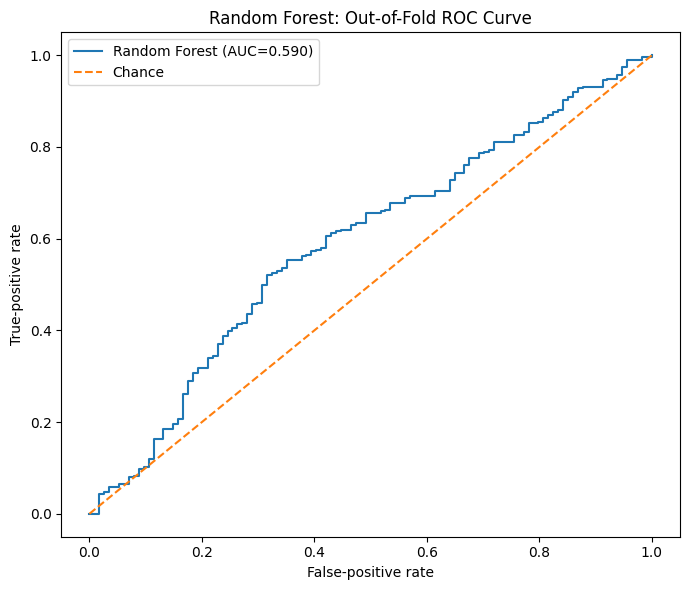

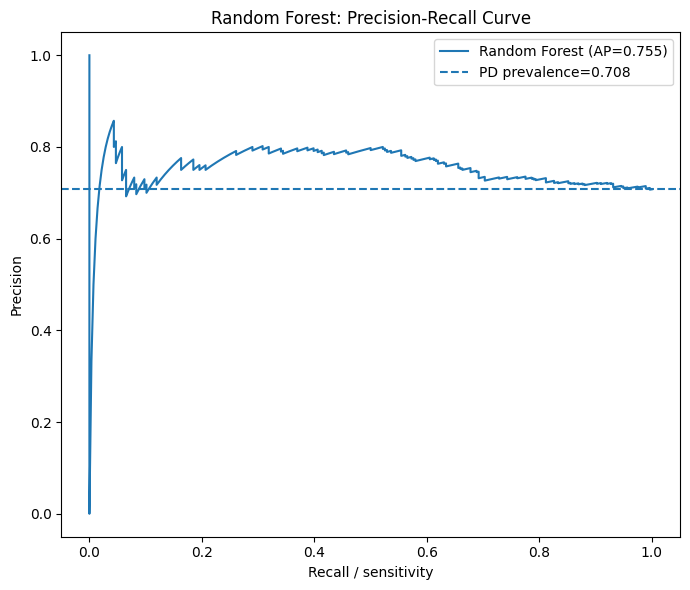

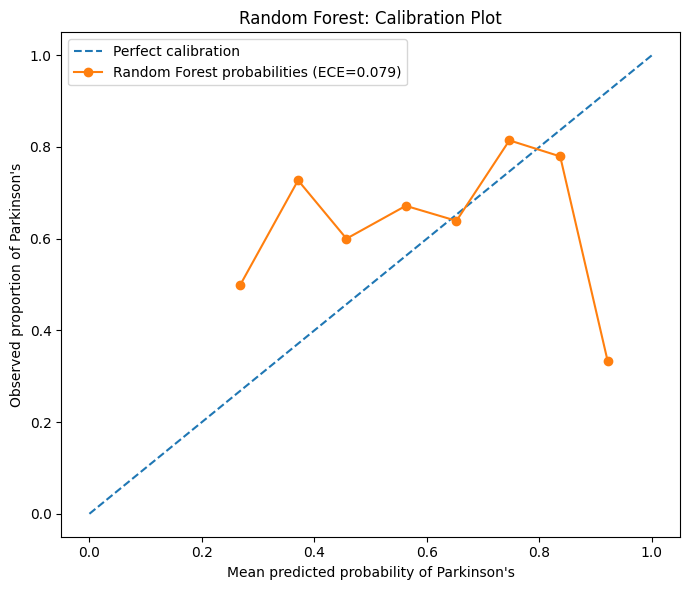

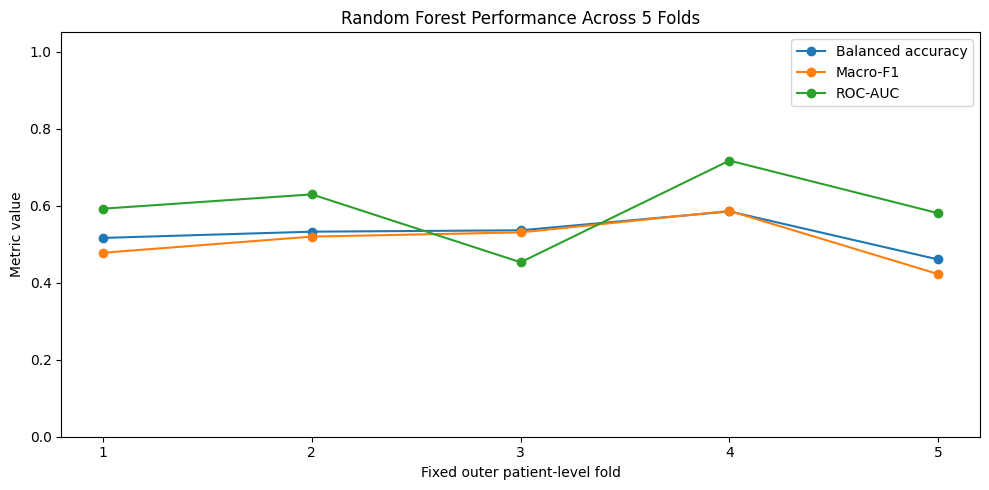

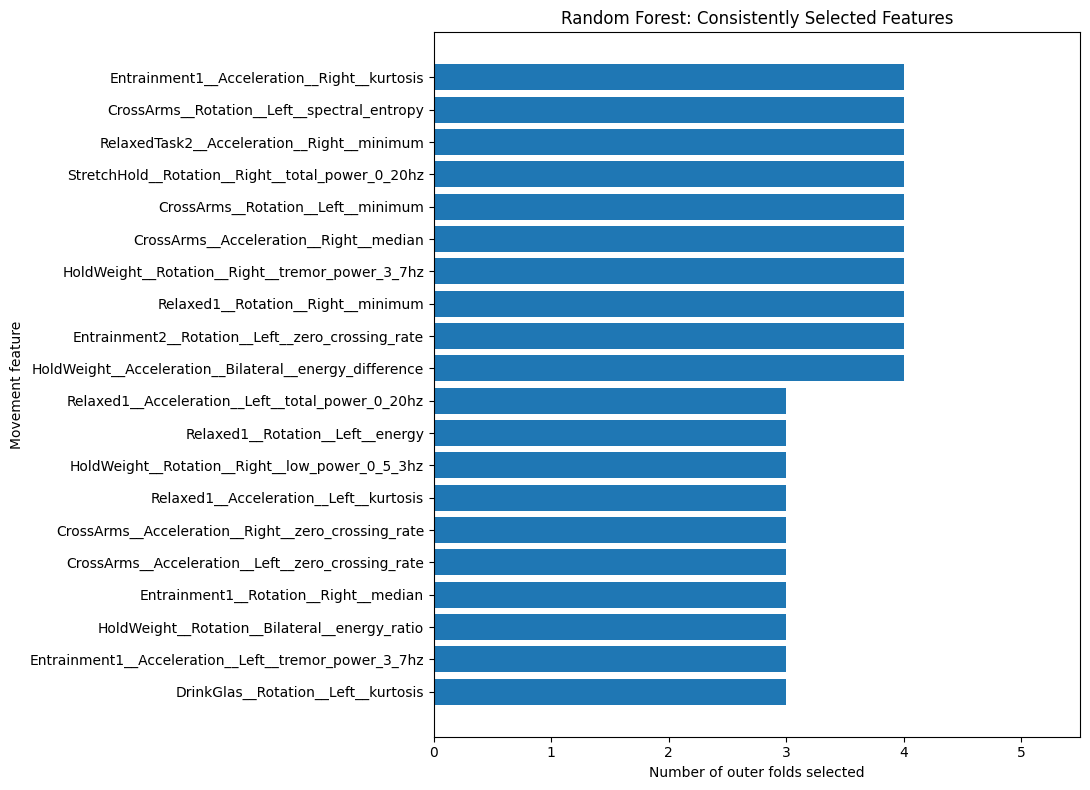

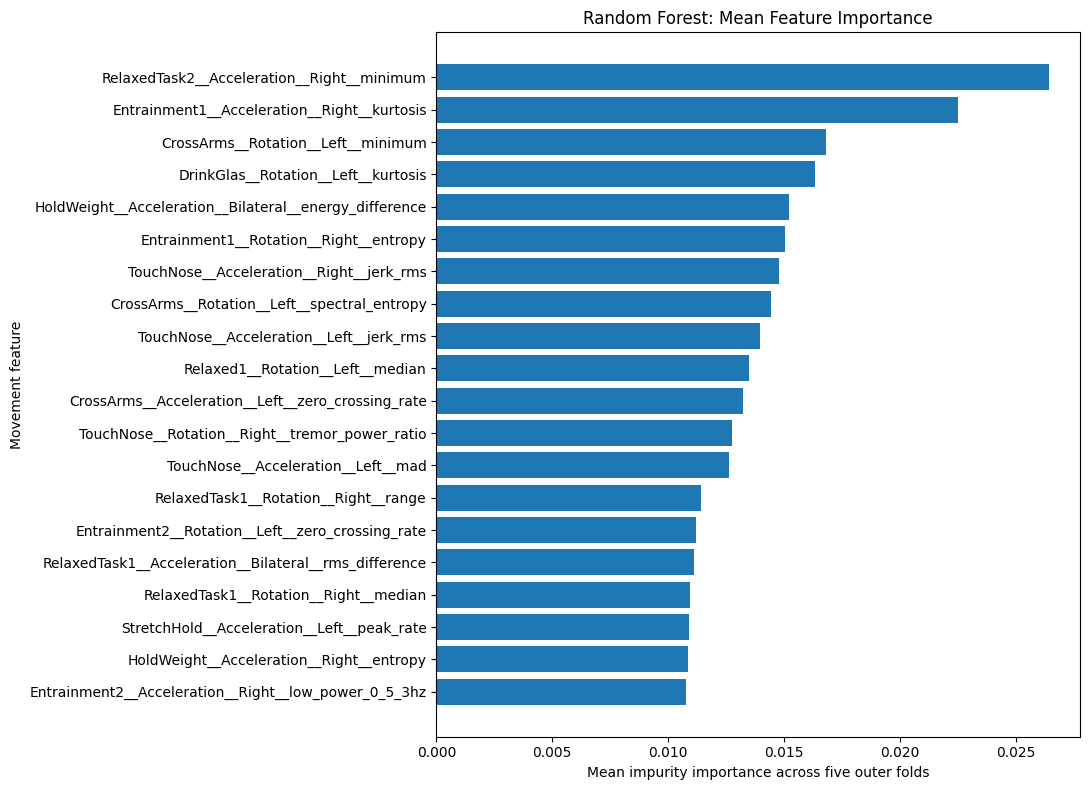


RANDOM FOREST BASELINE COMPLETE

Out-of-fold classification report:

                        precision    recall  f1-score   support

Differential Diagnosis     0.3830    0.1579    0.2236       114
           Parkinson's     0.7201    0.8949    0.7981       276

              accuracy                         0.6795       390
             macro avg     0.5515    0.5264    0.5108       390
          weighted avg     0.6216    0.6795    0.6301       390


Overall out-of-fold metrics:

accuracy                 : 0.6795
balanced_accuracy        : 0.5264
macro_f1                 : 0.5108
pd_f1                    : 0.7981
dd_f1                    : 0.2236
precision_pd             : 0.7201
sensitivity_pd           : 0.8949
specificity_dd           : 0.1579
ppv_pd                   : 0.7201
npv_dd                   : 0.3830
roc_auc                  : 0.5905
pr_auc                   : 0.7554
brier_score              : 0.2105
ece_10_bins              : 0.0786
true_negative            : 18
false_

In [ ]:
# =====================================================================
# PADS THIRD CLASSICAL BASELINE — RANDOM FOREST
# SAME FIXED 5-FOLD PATIENT-LEVEL CROSS-VALIDATION
# =====================================================================
#
# PRIMARY TASK:
# Parkinson's disease (1) vs Differential Diagnosis (0)
#
# FAIR COMPARISON:
# - Same 390 patients
# - Same fixed outer 5 folds
# - Same inner 3-fold tuning
# - Same movement-only feature family
# - Same feature-selection approach
# - Same class-imbalance strategy principle
# - Same evaluation metrics
# - Same patient-level bootstrap confidence intervals
#
# MODEL-SPECIFIC PREPROCESSING:
# - Median imputation
# - Constant-feature removal
# - Mutual-information feature selection
# - No StandardScaler because Random Forest is tree-based
#
# CLASS BALANCE:
# - class_weight="balanced_subsample"
# - No SMOTE, oversampling, undersampling or patient duplication
# =====================================================================

import warnings
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest,
    mutual_info_classif,
)
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    roc_curve,
    precision_recall_curve,
)

warnings.filterwarnings("ignore")

# =====================================================================
# 1. PATHS
# =====================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

FEATURE_FILE = (
    BASE_DIR
    / "project_ready_data"
    / "feature_engineering"
    / "pads_engineered_features.csv"
)

LOGISTIC_DIR = (
    BASE_DIR
    / "project_ready_data"
    / "baseline_results"
    / "logistic_regression_5fold"
)

SVM_DIR = (
    BASE_DIR
    / "project_ready_data"
    / "baseline_results"
    / "svm_rbf_corrected_5fold"
)

FIXED_SPLIT_FILE = (
    LOGISTIC_DIR
    / "fixed_outer_5fold_splits.csv"
)

LOGISTIC_SUMMARY_FILE = (
    LOGISTIC_DIR
    / "overall_summary.csv"
)

SVM_SUMMARY_FILE = (
    SVM_DIR
    / "overall_summary.csv"
)

OUTPUT_DIR = (
    BASE_DIR
    / "project_ready_data"
    / "baseline_results"
    / "random_forest_5fold"
)

FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not FEATURE_FILE.exists():
    raise FileNotFoundError(
        f"Engineered-feature file not found:\n{FEATURE_FILE}"
    )

if not FIXED_SPLIT_FILE.exists():
    raise FileNotFoundError(
        f"Fixed outer-fold file not found:\n{FIXED_SPLIT_FILE}\n\n"
        "Run the Logistic Regression 5-fold baseline first."
    )

print("=" * 100)
print("RANDOM FOREST BASELINE")
print("SAME FIXED 5-FOLD PATIENT-LEVEL VALIDATION")
print("=" * 100)

print("Feature file :", FEATURE_FILE)
print("Fixed folds  :", FIXED_SPLIT_FILE)
print("Output folder:", OUTPUT_DIR)

# =====================================================================
# 2. LOAD DATA AND FIXED FOLDS
# =====================================================================

df = pd.read_csv(
    FEATURE_FILE,
    dtype={"patient_id": str}
)

df["patient_id"] = (
    df["patient_id"]
    .astype(str)
    .str.zfill(3)
)

fixed_splits = pd.read_csv(
    FIXED_SPLIT_FILE,
    dtype={"patient_id": str}
)

fixed_splits["patient_id"] = (
    fixed_splits["patient_id"]
    .astype(str)
    .str.zfill(3)
)

fixed_splits["role"] = (
    fixed_splits["role"]
    .astype(str)
    .str.lower()
    .str.strip()
)

if "y" not in df.columns:
    raise ValueError(
        "Target column 'y' is missing."
    )

if df["patient_id"].duplicated().any():
    duplicate_ids = df.loc[
        df["patient_id"].duplicated(),
        "patient_id"
    ].tolist()

    raise ValueError(
        f"Duplicate patient IDs detected: {duplicate_ids[:10]}"
    )

required_split_columns = {
    "patient_id",
    "fold",
    "role",
}

if not required_split_columns.issubset(
    fixed_splits.columns
):
    raise ValueError(
        "Fixed split file must contain patient_id, fold and role."
    )

print("\nFeature-table shape:", df.shape)
print("Unique patients:", df["patient_id"].nunique())

print("\nClass distribution:")

print(
    df["y"]
    .value_counts()
    .rename({
        0: "Differential Diagnosis",
        1: "Parkinson's",
    })
)

# =====================================================================
# 3. VERIFY FIXED PATIENT-LEVEL FOLDS
# =====================================================================

data_patient_ids = set(
    df["patient_id"]
)

split_patient_ids = set(
    fixed_splits["patient_id"]
)

if data_patient_ids != split_patient_ids:

    missing_from_splits = (
        data_patient_ids - split_patient_ids
    )

    extra_in_splits = (
        split_patient_ids - data_patient_ids
    )

    raise ValueError(
        "Patient mismatch between feature table and fixed folds.\n"
        f"Missing from splits: {list(missing_from_splits)[:10]}\n"
        f"Extra in splits: {list(extra_in_splits)[:10]}"
    )

available_folds = sorted(
    fixed_splits["fold"].unique()
)

if available_folds != [1, 2, 3, 4, 5]:
    raise ValueError(
        f"Expected folds [1,2,3,4,5], found {available_folds}"
    )

test_frequency = (
    fixed_splits[
        fixed_splits["role"] == "test"
    ]
    .groupby("patient_id")
    .size()
)

if len(test_frequency) != len(df):
    raise ValueError(
        "Not all patients appear in an outer test fold."
    )

if not (test_frequency == 1).all():
    raise ValueError(
        "Every patient must appear as outer test exactly once."
    )

print("\nFixed folds successfully verified.")
print("Every patient appears as outer-test exactly once.")

# =====================================================================
# 4. SELECT SAME MOVEMENT-ONLY FEATURES
# =====================================================================

identifier_columns = {
    "patient_id",
    "y",
    "diagnosis_group",
    "original_condition",
    "gender",
    "handedness",
}

demographic_columns = {
    "age",
    "height",
    "weight",
    "bmi",
    "gender_encoded",
    "handedness_encoded",
}

quality_patterns = [
    "__missing_ratio",
    "__flat_difference_ratio",
    "__spike_ratio",
    "__repeated_value_ratio",
    "__technical_quality_score",
    "mean_technical_quality",
]

def is_quality_feature(column_name):
    return any(
        pattern in column_name
        for pattern in quality_patterns
    )

feature_columns = []

for column in df.columns:

    if column in identifier_columns:
        continue

    if column in demographic_columns:
        continue

    if is_quality_feature(column):
        continue

    if not pd.api.types.is_numeric_dtype(
        df[column]
    ):
        continue

    feature_columns.append(column)

X = df[feature_columns].copy()

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

y = (
    df["y"]
    .astype(int)
    .to_numpy()
)

patient_ids = (
    df["patient_id"]
    .astype(str)
    .to_numpy()
)

patient_to_index = {
    patient_id: index
    for index, patient_id in enumerate(patient_ids)
}

print("\nPrimary movement-only input:")
print("Patients:", X.shape[0])
print("Features:", X.shape[1])
print("Missing cells:", int(X.isna().sum().sum()))

if X.shape[0] != 390:
    print(
        f"Warning: expected 390 patients, found {X.shape[0]}."
    )

# =====================================================================
# 5. EXPECTED CALIBRATION ERROR
# =====================================================================

def expected_calibration_error(
    y_true,
    probability_pd,
    n_bins=10
):
    y_true = np.asarray(y_true)
    probability_pd = np.asarray(probability_pd)

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for bin_index in range(n_bins):

        lower = bin_edges[bin_index]
        upper = bin_edges[bin_index + 1]

        if bin_index == n_bins - 1:

            bin_mask = (
                (probability_pd >= lower)
                & (probability_pd <= upper)
            )

        else:

            bin_mask = (
                (probability_pd >= lower)
                & (probability_pd < upper)
            )

        if not np.any(bin_mask):
            continue

        mean_probability = np.mean(
            probability_pd[bin_mask]
        )

        observed_pd_rate = np.mean(
            y_true[bin_mask]
        )

        bin_weight = np.mean(
            bin_mask
        )

        ece += (
            bin_weight
            * abs(
                observed_pd_rate
                - mean_probability
            )
        )

    return float(ece)

# =====================================================================
# 6. SHARED EVALUATION FUNCTION
# =====================================================================

def calculate_metrics(
    y_true,
    y_pred,
    probability_pd
):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    sensitivity_pd = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity_dd = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    ppv_pd = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    npv_dd = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "pd_f1": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "dd_f1": f1_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "precision_pd": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "sensitivity_pd": sensitivity_pd,
        "specificity_dd": specificity_dd,
        "ppv_pd": ppv_pd,
        "npv_dd": npv_dd,

        "roc_auc": roc_auc_score(
            y_true,
            probability_pd
        ),

        "pr_auc": average_precision_score(
            y_true,
            probability_pd
        ),

        "brier_score": brier_score_loss(
            y_true,
            probability_pd
        ),

        "ece_10_bins": expected_calibration_error(
            y_true,
            probability_pd,
            n_bins=10
        ),

        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }

# =====================================================================
# 7. RANDOM FOREST PIPELINE
# =====================================================================

# Fixed random state makes mutual-information feature selection reproducible.
mutual_information_score = partial(
    mutual_info_classif,
    random_state=42
)

pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "variance_filter",
            VarianceThreshold(
                threshold=0.0
            )
        ),

        (
            "feature_selector",
            SelectKBest(
                score_func=mutual_information_score,
                k=50
            )
        ),

        (
            "classifier",
            RandomForestClassifier(
                class_weight="balanced_subsample",
                random_state=42,

                # GridSearchCV uses all CPU cores.
                # Keep each forest on one job to avoid nested overload.
                n_jobs=1,

                bootstrap=True,
                criterion="gini"
            )
        ),
    ]
)

candidate_k_values = [
    value
    for value in [
        25,
        50,
        100,
        200,
    ]
    if value < X.shape[1]
]

# Compact but meaningful grid to keep runtime manageable.
parameter_grid = {
    "feature_selector__k": candidate_k_values,

    "classifier__n_estimators": [
        300,
        600,
    ],

    "classifier__max_depth": [
        None,
        10,
    ],

    "classifier__min_samples_leaf": [
        1,
        3,
    ],

    "classifier__max_features": [
        "sqrt",
        0.5,
    ],
}

inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=142
)

number_of_parameter_combinations = (
    len(parameter_grid["feature_selector__k"])
    * len(parameter_grid["classifier__n_estimators"])
    * len(parameter_grid["classifier__max_depth"])
    * len(parameter_grid["classifier__min_samples_leaf"])
    * len(parameter_grid["classifier__max_features"])
)

print("\nInner-CV parameter combinations:")
print(number_of_parameter_combinations)

print(
    "\nRandom Forest can take several minutes because "
    "each fold performs inner hyperparameter tuning."
)

# =====================================================================
# 8. FIXED OUTER 5-FOLD TRAINING
# =====================================================================

out_of_fold_probability = np.full(
    len(y),
    np.nan,
    dtype=float
)

out_of_fold_prediction = np.full(
    len(y),
    -1,
    dtype=int
)

fold_assignments = np.full(
    len(y),
    -1,
    dtype=int
)

fold_result_rows = []
best_parameter_rows = []
selected_feature_rows = []
feature_importance_rows = []

print("\n" + "=" * 100)
print("STARTING FIXED 5-FOLD RANDOM FOREST TRAINING")
print("=" * 100)

for fold_number in available_folds:

    current_fold = fixed_splits[
        fixed_splits["fold"] == fold_number
    ]

    train_ids = current_fold.loc[
        current_fold["role"] == "train",
        "patient_id"
    ].tolist()

    test_ids = current_fold.loc[
        current_fold["role"] == "test",
        "patient_id"
    ].tolist()

    train_id_set = set(train_ids)
    test_id_set = set(test_ids)

    overlap = train_id_set.intersection(
        test_id_set
    )

    if overlap:
        raise RuntimeError(
            f"Patient leakage in fold {fold_number}: "
            f"{list(overlap)[:5]}"
        )

    train_indices = np.array([
        patient_to_index[patient_id]
        for patient_id in train_ids
    ])

    test_indices = np.array([
        patient_to_index[patient_id]
        for patient_id in test_ids
    ])

    X_train = X.iloc[
        train_indices
    ].copy()

    X_test = X.iloc[
        test_indices
    ].copy()

    y_train = y[
        train_indices
    ]

    y_test = y[
        test_indices
    ]

    grid_search = GridSearchCV(
        estimator=clone(pipeline),
        param_grid=parameter_grid,

        # Same main tuning metric as earlier baselines.
        scoring="balanced_accuracy",

        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
        error_score="raise",
        verbose=0
    )

    grid_search.fit(
        X_train,
        y_train
    )

    best_model = (
        grid_search.best_estimator_
    )

    # Class labels use the model's decision rule.
    test_prediction = (
        best_model
        .predict(X_test)
        .astype(int)
    )

    probability_matrix = (
        best_model
        .predict_proba(X_test)
    )

    classifier_classes = (
        best_model
        .named_steps["classifier"]
        .classes_
    )

    pd_probability_column = int(
        np.where(
            classifier_classes == 1
        )[0][0]
    )

    test_probability = (
        probability_matrix[
            :,
            pd_probability_column
        ]
    )

    out_of_fold_prediction[
        test_indices
    ] = test_prediction

    out_of_fold_probability[
        test_indices
    ] = test_probability

    fold_assignments[
        test_indices
    ] = int(fold_number)

    fold_metrics = calculate_metrics(
        y_test,
        test_prediction,
        test_probability
    )

    fold_metrics.update({
        "fold": int(fold_number),

        "train_patients": len(train_indices),
        "test_patients": len(test_indices),

        "train_pd": int(
            np.sum(y_train == 1)
        ),

        "train_dd": int(
            np.sum(y_train == 0)
        ),

        "test_pd": int(
            np.sum(y_test == 1)
        ),

        "test_dd": int(
            np.sum(y_test == 0)
        ),

        "best_inner_balanced_accuracy": float(
            grid_search.best_score_
        ),
    })

    fold_result_rows.append(
        fold_metrics
    )

    parameter_row = {
        "fold": int(fold_number),

        "best_inner_balanced_accuracy": float(
            grid_search.best_score_
        ),
    }

    parameter_row.update(
        grid_search.best_params_
    )

    best_parameter_rows.append(
        parameter_row
    )

    # ================================================================
    # RECOVER SELECTED FEATURE NAMES
    # ================================================================

    variance_step = (
        best_model
        .named_steps["variance_filter"]
    )

    selector_step = (
        best_model
        .named_steps["feature_selector"]
    )

    classifier_step = (
        best_model
        .named_steps["classifier"]
    )

    names_after_variance = np.array(
        feature_columns
    )[
        variance_step.get_support()
    ]

    selected_names = names_after_variance[
        selector_step.get_support()
    ]

    selected_importances = (
        classifier_step
        .feature_importances_
    )

    if len(selected_names) != len(
        selected_importances
    ):
        raise RuntimeError(
            "Selected feature names and importance lengths do not match."
        )

    for feature_name, importance in zip(
        selected_names,
        selected_importances
    ):

        selected_feature_rows.append({
            "fold": int(fold_number),
            "feature_name": feature_name,
        })

        feature_importance_rows.append({
            "fold": int(fold_number),
            "feature_name": feature_name,
            "importance": float(importance),
        })

    print("\n" + "-" * 74)
    print(f"OUTER FOLD {fold_number}/5")
    print("-" * 74)

    print(
        f"Training: {len(train_indices)} "
        f"(PD={np.sum(y_train == 1)}, "
        f"DD={np.sum(y_train == 0)})"
    )

    print(
        f"Testing : {len(test_indices)} "
        f"(PD={np.sum(y_test == 1)}, "
        f"DD={np.sum(y_test == 0)})"
    )

    print("\nBest parameters:")
    print(
        grid_search.best_params_
    )

    print(
        f"\nBalanced accuracy: "
        f"{fold_metrics['balanced_accuracy']:.4f}"
    )

    print(
        f"Macro-F1: "
        f"{fold_metrics['macro_f1']:.4f}"
    )

    print(
        f"Sensitivity PD: "
        f"{fold_metrics['sensitivity_pd']:.4f}"
    )

    print(
        f"Specificity DD: "
        f"{fold_metrics['specificity_dd']:.4f}"
    )

    print(
        f"ROC-AUC: "
        f"{fold_metrics['roc_auc']:.4f}"
    )

    print(
        f"PR-AUC: "
        f"{fold_metrics['pr_auc']:.4f}"
    )

    print(
        f"Confusion: "
        f"TN={fold_metrics['true_negative']}, "
        f"FP={fold_metrics['false_positive']}, "
        f"FN={fold_metrics['false_negative']}, "
        f"TP={fold_metrics['true_positive']}"
    )

# =====================================================================
# 9. VERIFY OUT-OF-FOLD EVALUATION
# =====================================================================

if np.isnan(
    out_of_fold_probability
).any():
    raise RuntimeError(
        "Some patients did not receive Random Forest probabilities."
    )

if np.any(
    out_of_fold_prediction < 0
):
    raise RuntimeError(
        "Some patients did not receive Random Forest labels."
    )

if np.any(
    fold_assignments < 1
):
    raise RuntimeError(
        "Some patients were not assigned to an outer fold."
    )

overall_metrics = calculate_metrics(
    y,
    out_of_fold_prediction,
    out_of_fold_probability
)

# =====================================================================
# 10. PATIENT-LEVEL BOOTSTRAP 95% CONFIDENCE INTERVALS
# =====================================================================

rng = np.random.default_rng(42)

N_BOOTSTRAPS = 2000

bootstrap_rows = []

for bootstrap_index in range(
    N_BOOTSTRAPS
):

    sampled_indices = rng.integers(
        low=0,
        high=len(y),
        size=len(y)
    )

    sampled_y = y[
        sampled_indices
    ]

    if len(
        np.unique(sampled_y)
    ) < 2:
        continue

    sampled_prediction = (
        out_of_fold_prediction[
            sampled_indices
        ]
    )

    sampled_probability = (
        out_of_fold_probability[
            sampled_indices
        ]
    )

    bootstrap_rows.append(
        calculate_metrics(
            sampled_y,
            sampled_prediction,
            sampled_probability
        )
    )

bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

metrics_for_ci = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

confidence_interval_rows = []

for metric_name in metrics_for_ci:

    values = (
        bootstrap_df[metric_name]
        .dropna()
        .to_numpy()
    )

    confidence_interval_rows.append({
        "metric": metric_name,

        "value": overall_metrics[
            metric_name
        ],

        "ci_95_lower": float(
            np.percentile(
                values,
                2.5
            )
        ),

        "ci_95_upper": float(
            np.percentile(
                values,
                97.5
            )
        ),
    })

confidence_intervals_df = pd.DataFrame(
    confidence_interval_rows
)

# =====================================================================
# 11. RESULT TABLES
# =====================================================================

fold_results_df = pd.DataFrame(
    fold_result_rows
)

best_parameters_df = pd.DataFrame(
    best_parameter_rows
)

selected_features_df = pd.DataFrame(
    selected_feature_rows
)

feature_importances_df = pd.DataFrame(
    feature_importance_rows
)

feature_frequency_df = (
    selected_features_df
    .groupby("feature_name")
    .size()
    .reset_index(
        name="selected_in_folds"
    )
    .sort_values(
        [
            "selected_in_folds",
            "feature_name"
        ],
        ascending=[
            False,
            True
        ]
    )
)

# Average importance across folds.
# Features absent in a fold effectively contribute zero in that fold.
all_importance_features = sorted(
    feature_importances_df[
        "feature_name"
    ].unique()
)

importance_summary_rows = []

for feature_name in all_importance_features:

    feature_fold_values = (
        feature_importances_df.loc[
            feature_importances_df[
                "feature_name"
            ] == feature_name,
            [
                "fold",
                "importance"
            ]
        ]
    )

    fold_importance_map = dict(
        zip(
            feature_fold_values["fold"],
            feature_fold_values["importance"]
        )
    )

    five_fold_importances = [
        float(
            fold_importance_map.get(
                fold_number,
                0.0
            )
        )
        for fold_number in available_folds
    ]

    importance_summary_rows.append({
        "feature_name": feature_name,

        "selected_in_folds": int(
            np.sum(
                np.array(
                    five_fold_importances
                ) > 0
            )
        ),

        "mean_importance_across_all_folds": float(
            np.mean(
                five_fold_importances
            )
        ),

        "mean_importance_when_selected": float(
            feature_fold_values[
                "importance"
            ].mean()
        ),

        "maximum_fold_importance": float(
            np.max(
                five_fold_importances
            )
        ),
    })

importance_summary_df = (
    pd.DataFrame(
        importance_summary_rows
    )
    .sort_values(
        "mean_importance_across_all_folds",
        ascending=False
    )
)

patient_predictions_df = pd.DataFrame({
    "patient_id": patient_ids,

    "true_label": y,

    "true_group": np.where(
        y == 1,
        "Parkinson's",
        "Differential Diagnosis"
    ),

    "outer_fold": fold_assignments,

    "predicted_probability_pd": (
        out_of_fold_probability
    ),

    "predicted_label": (
        out_of_fold_prediction
    ),

    "predicted_group": np.where(
        out_of_fold_prediction == 1,
        "Parkinson's",
        "Differential Diagnosis"
    ),

    "correct_prediction": (
        out_of_fold_prediction == y
    ).astype(int),
})

summary_df = pd.DataFrame([
    {
        "model": "Random Forest",

        "prediction_rule": (
            "RandomForest.predict for labels; "
            "predict_proba for probability metrics"
        ),

        "feature_set": (
            "Movement time-domain + frequency-domain "
            "+ bilateral-asymmetry"
        ),

        "quality_features_included": False,
        "demographics_included": False,

        "scaling_used": False,

        "class_balance_method": (
            "Same fixed stratified folds "
            "+ balanced_subsample class weights"
        ),

        "oversampling_used": False,

        "patients": len(y),
        "pd_patients": int(
            np.sum(y == 1)
        ),
        "dd_patients": int(
            np.sum(y == 0)
        ),

        "outer_folds": 5,
        "inner_folds": 3,

        **overall_metrics,
    }
])

# =====================================================================
# 12. SAVE RESULTS
# =====================================================================

patient_predictions_df.to_csv(
    OUTPUT_DIR
    / "patient_predictions.csv",
    index=False
)

fold_results_df.to_csv(
    OUTPUT_DIR
    / "fold_results.csv",
    index=False
)

summary_df.to_csv(
    OUTPUT_DIR
    / "overall_summary.csv",
    index=False
)

confidence_intervals_df.to_csv(
    OUTPUT_DIR
    / "confidence_intervals_95.csv",
    index=False
)

best_parameters_df.to_csv(
    OUTPUT_DIR
    / "best_parameters_by_fold.csv",
    index=False
)

selected_features_df.to_csv(
    OUTPUT_DIR
    / "selected_features_by_fold.csv",
    index=False
)

feature_frequency_df.to_csv(
    OUTPUT_DIR
    / "feature_selection_frequency.csv",
    index=False
)

feature_importances_df.to_csv(
    OUTPUT_DIR
    / "feature_importances_by_fold.csv",
    index=False
)

importance_summary_df.to_csv(
    OUTPUT_DIR
    / "feature_importance_summary.csv",
    index=False
)

bootstrap_df.to_csv(
    OUTPUT_DIR
    / "bootstrap_metrics.csv",
    index=False
)

# =====================================================================
# 13. CONFUSION MATRIX
# =====================================================================

cm = confusion_matrix(
    y,
    out_of_fold_prediction,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

plt.imshow(cm)
plt.colorbar()

plt.xticks(
    [0, 1],
    ["DD", "Parkinson's"]
)

plt.yticks(
    [0, 1],
    ["DD", "Parkinson's"]
)

plt.xlabel("Predicted diagnosis")
plt.ylabel("True diagnosis")

plt.title(
    "Random Forest\n"
    "5-Fold Out-of-Fold Confusion Matrix"
)

for row in range(2):

    for column in range(2):

        plt.text(
            column,
            row,
            str(cm[row, column]),
            ha="center",
            va="center",
            fontsize=15
        )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "01_confusion_matrix.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 14. ROC CURVE
# =====================================================================

fpr, tpr, _ = roc_curve(
    y,
    out_of_fold_probability
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=(
        f"Random Forest "
        f"(AUC={overall_metrics['roc_auc']:.3f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance"
)

plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")

plt.title(
    "Random Forest: Out-of-Fold ROC Curve"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "02_roc_curve.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 15. PRECISION-RECALL CURVE
# =====================================================================

precision_values, recall_values, _ = (
    precision_recall_curve(
        y,
        out_of_fold_probability
    )
)

pd_prevalence = float(
    np.mean(y)
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall_values,
    precision_values,
    label=(
        f"Random Forest "
        f"(AP={overall_metrics['pr_auc']:.3f})"
    )
)

plt.axhline(
    pd_prevalence,
    linestyle="--",
    label=(
        f"PD prevalence={pd_prevalence:.3f}"
    )
)

plt.xlabel("Recall / sensitivity")
plt.ylabel("Precision")

plt.title(
    "Random Forest: Precision-Recall Curve"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "03_precision_recall_curve.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 16. CALIBRATION PLOT
# =====================================================================

N_BINS = 10

bin_edges = np.linspace(
    0,
    1,
    N_BINS + 1
)

mean_probabilities = []
observed_pd_rates = []
bin_counts = []

for bin_index in range(N_BINS):

    lower = bin_edges[
        bin_index
    ]

    upper = bin_edges[
        bin_index + 1
    ]

    if bin_index == N_BINS - 1:

        bin_mask = (
            (out_of_fold_probability >= lower)
            & (out_of_fold_probability <= upper)
        )

    else:

        bin_mask = (
            (out_of_fold_probability >= lower)
            & (out_of_fold_probability < upper)
        )

    if not np.any(
        bin_mask
    ):
        continue

    mean_probabilities.append(
        float(
            np.mean(
                out_of_fold_probability[
                    bin_mask
                ]
            )
        )
    )

    observed_pd_rates.append(
        float(
            np.mean(
                y[bin_mask]
            )
        )
    )

    bin_counts.append(
        int(
            np.sum(
                bin_mask
            )
        )
    )

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    mean_probabilities,
    observed_pd_rates,
    marker="o",
    label=(
        f"Random Forest probabilities "
        f"(ECE={overall_metrics['ece_10_bins']:.3f})"
    )
)

plt.xlabel(
    "Mean predicted probability of Parkinson's"
)

plt.ylabel(
    "Observed proportion of Parkinson's"
)

plt.title(
    "Random Forest: Calibration Plot"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "04_calibration_plot.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 17. FOLD PERFORMANCE
# =====================================================================

plt.figure(figsize=(10, 5))

plt.plot(
    fold_results_df["fold"],
    fold_results_df["balanced_accuracy"],
    marker="o",
    label="Balanced accuracy"
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df["macro_f1"],
    marker="o",
    label="Macro-F1"
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df["roc_auc"],
    marker="o",
    label="ROC-AUC"
)

plt.xlabel(
    "Fixed outer patient-level fold"
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "Random Forest Performance Across 5 Folds"
)

plt.xticks(
    [1, 2, 3, 4, 5]
)

plt.ylim(
    0,
    1.05
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "05_fold_performance.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 18. FEATURE-SELECTION FREQUENCY
# =====================================================================

if not feature_frequency_df.empty:

    top_selected_features = (
        feature_frequency_df
        .head(20)
        .sort_values(
            "selected_in_folds"
        )
    )

    plt.figure(
        figsize=(11, 8)
    )

    plt.barh(
        top_selected_features[
            "feature_name"
        ],
        top_selected_features[
            "selected_in_folds"
        ]
    )

    plt.xlabel(
        "Number of outer folds selected"
    )

    plt.ylabel(
        "Movement feature"
    )

    plt.title(
        "Random Forest: Consistently Selected Features"
    )

    plt.xlim(
        0,
        5.5
    )

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR
        / "06_feature_selection_frequency.png",
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# =====================================================================
# 19. RANDOM FOREST FEATURE IMPORTANCE
# =====================================================================

if not importance_summary_df.empty:

    top_importances = (
        importance_summary_df
        .head(20)
        .sort_values(
            "mean_importance_across_all_folds"
        )
    )

    plt.figure(
        figsize=(11, 8)
    )

    plt.barh(
        top_importances[
            "feature_name"
        ],
        top_importances[
            "mean_importance_across_all_folds"
        ]
    )

    plt.xlabel(
        "Mean impurity importance across five outer folds"
    )

    plt.ylabel(
        "Movement feature"
    )

    plt.title(
        "Random Forest: Mean Feature Importance"
    )

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR
        / "07_feature_importance.png",
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# =====================================================================
# 20. FAIR COMPARISON WITH PREVIOUS BASELINES
# =====================================================================

comparison_rows = []

if LOGISTIC_SUMMARY_FILE.exists():

    logistic_summary = pd.read_csv(
        LOGISTIC_SUMMARY_FILE
    )

    comparison_rows.append(
        logistic_summary
        .iloc[0]
        .to_dict()
    )

if SVM_SUMMARY_FILE.exists():

    svm_summary = pd.read_csv(
        SVM_SUMMARY_FILE
    )

    comparison_rows.append(
        svm_summary
        .iloc[0]
        .to_dict()
    )

comparison_rows.append(
    summary_df
    .iloc[0]
    .to_dict()
)

comparison_df = pd.DataFrame(
    comparison_rows
)

comparison_df.to_csv(
    OUTPUT_DIR
    / "comparison_with_previous_baselines.csv",
    index=False
)

comparison_columns = [
    "model",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

available_comparison_columns = [
    column
    for column in comparison_columns
    if column in comparison_df.columns
]

# =====================================================================
# 21. FINAL PRINTED RESULTS
# =====================================================================

print("\n" + "=" * 100)
print("RANDOM FOREST BASELINE COMPLETE")
print("=" * 100)

print(
    "\nOut-of-fold classification report:\n"
)

print(
    classification_report(
        y,
        out_of_fold_prediction,
        target_names=[
            "Differential Diagnosis",
            "Parkinson's",
        ],
        digits=4,
        zero_division=0
    )
)

print(
    "\nOverall out-of-fold metrics:\n"
)

for metric_name, metric_value in overall_metrics.items():

    if isinstance(
        metric_value,
        (float, np.floating)
    ):

        print(
            f"{metric_name:25s}: "
            f"{metric_value:.4f}"
        )

    else:

        print(
            f"{metric_name:25s}: "
            f"{metric_value}"
        )

print(
    "\nBootstrap 95% confidence intervals:\n"
)

print(
    confidence_intervals_df
    .round(4)
    .to_string(
        index=False
    )
)

print(
    "\nFold-level results:\n"
)

display_columns = [
    "fold",
    "train_patients",
    "test_patients",
    "train_pd",
    "train_dd",
    "test_pd",
    "test_dd",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

print(
    fold_results_df[
        display_columns
    ]
    .round(4)
    .to_string(
        index=False
    )
)

if len(
    comparison_df
) > 1:

    print(
        "\nFair comparison with previous baselines:\n"
    )

    print(
        comparison_df[
            available_comparison_columns
        ]
        .round(4)
        .to_string(
            index=False
        )
    )

print(
    "\nFair-comparison controls:"
)

print(
    "- Same 390 patients and same fixed outer five folds."
)

print(
    "- Same inner three-fold tuning structure."
)

print(
    "- Same movement-only feature family."
)

print(
    "- Same mutual-information feature-selection options."
)

print(
    "- Same patient-level metrics and bootstrap procedure."
)

print(
    "- No quality features or demographics included."
)

print(
    "- No SMOTE, oversampling, undersampling or duplication."
)

print(
    "\nRandom Forest-specific differences:"
)

print(
    "- Standard scaling was not used because tree models "
    "are insensitive to feature scale."
)

print(
    "- balanced_subsample recalculated class weights "
    "within each bootstrap tree sample."
)

print(
    "- Feature importance is impurity-based and will later "
    "be supplemented with permutation or SHAP analysis."
)

print(
    "\nSaved files:"
)

for path in sorted(
    OUTPUT_DIR.rglob("*")
):

    if path.is_file():

        print(
            " -",
            path.relative_to(
                OUTPUT_DIR
            )
        )

print(
    "\n✅ THIRD CLASSICAL BASELINE FINISHED."
)

## XGBoost

GPU CHECK
Fri Jul 17 18:48:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-------------------------------------

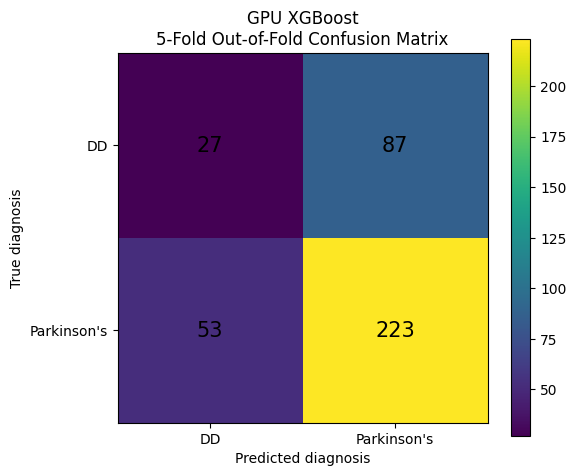

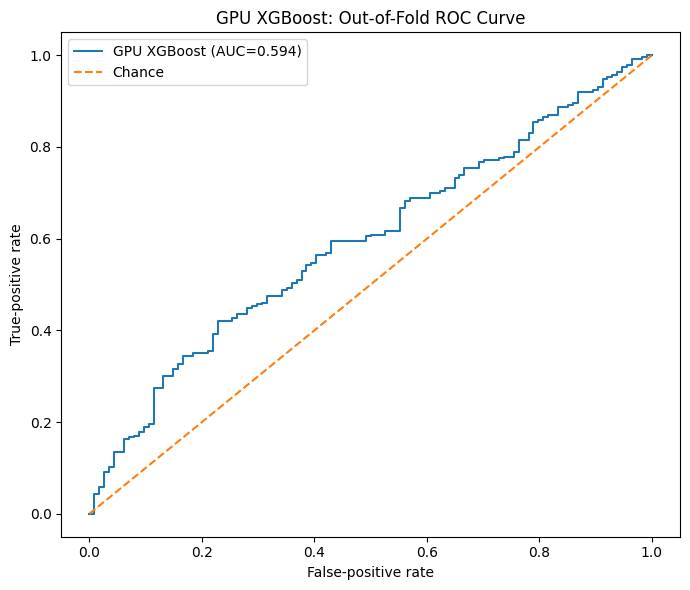

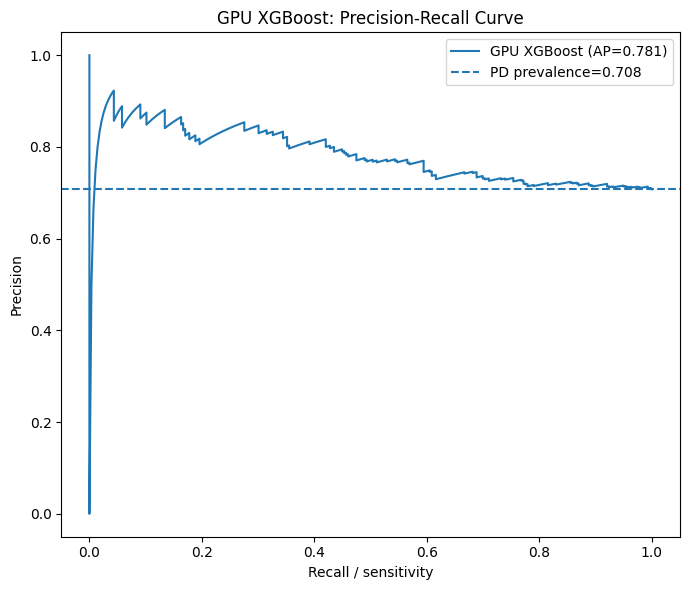

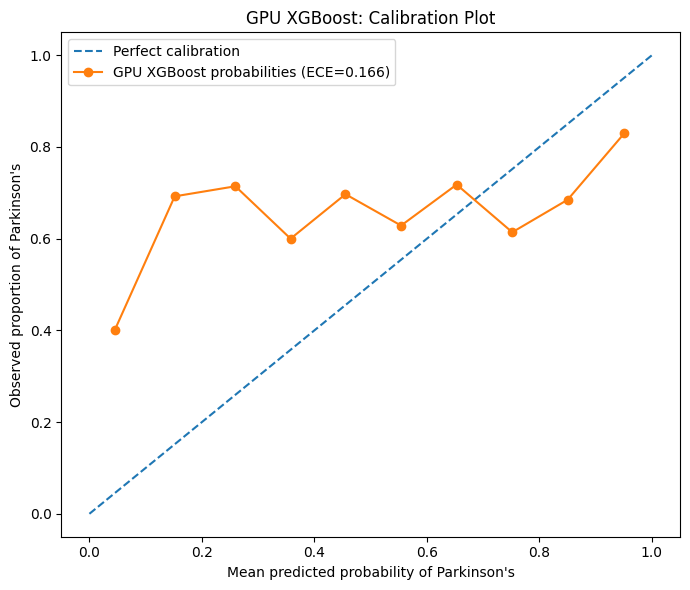

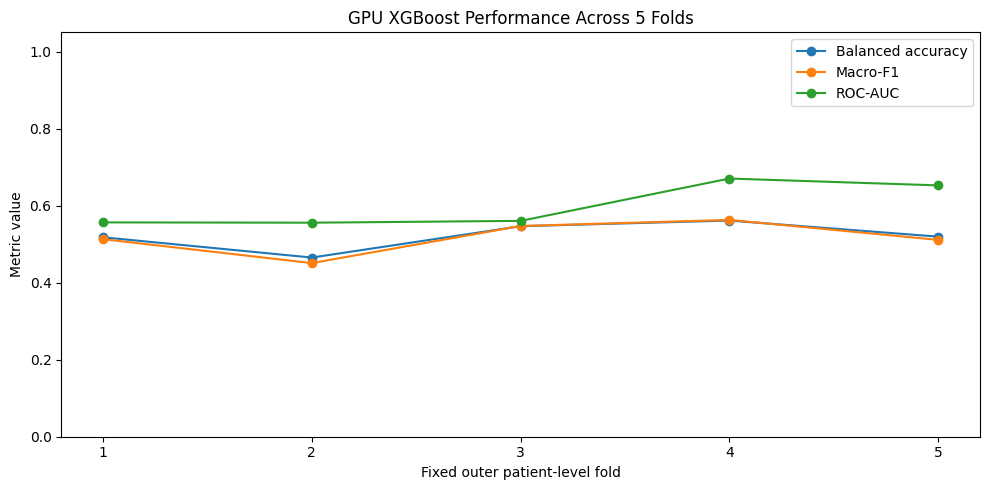

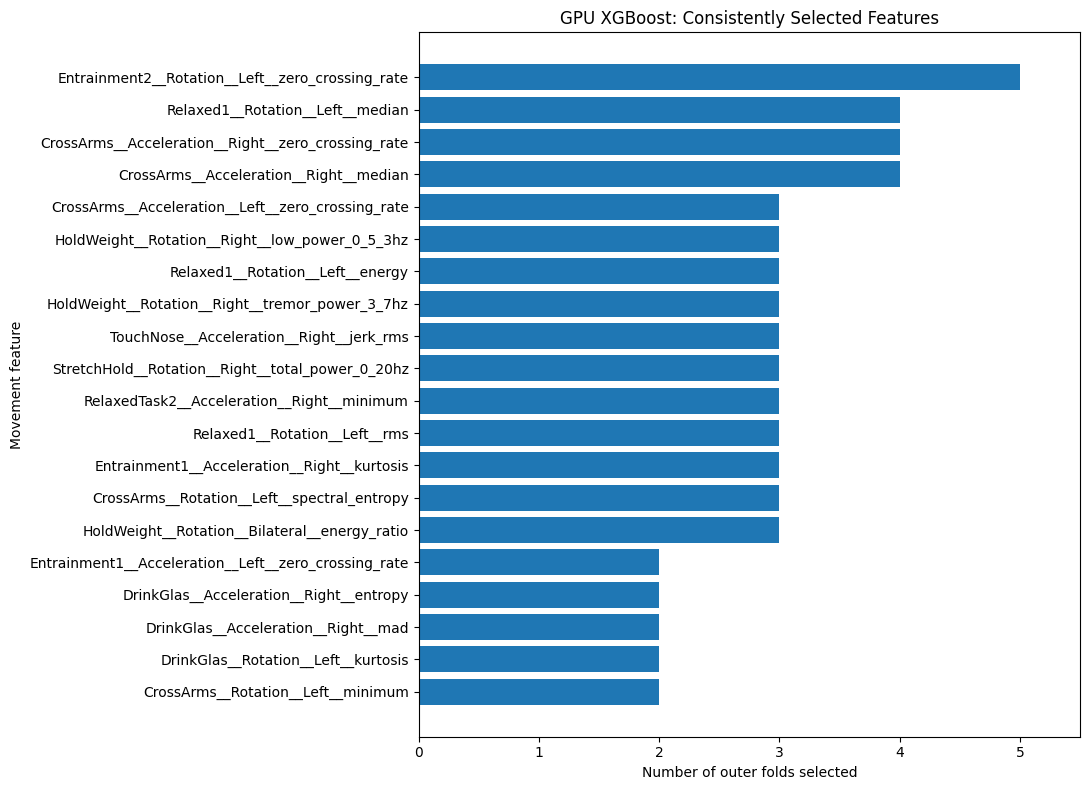

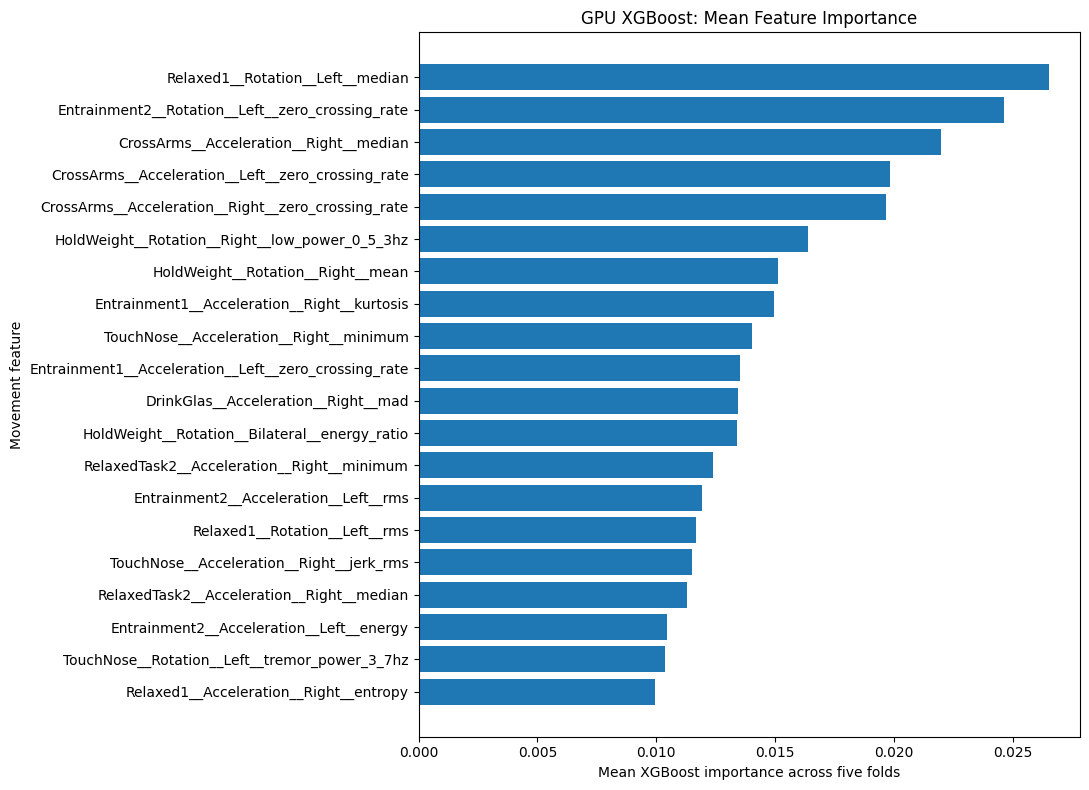


GPU XGBOOST BASELINE COMPLETE

Out-of-fold classification report:

                        precision    recall  f1-score   support

Differential Diagnosis     0.3375    0.2368    0.2784       114
           Parkinson's     0.7194    0.8080    0.7611       276

              accuracy                         0.6410       390
             macro avg     0.5284    0.5224    0.5197       390
          weighted avg     0.6077    0.6410    0.6200       390


Overall out-of-fold metrics:

accuracy                 : 0.6410
balanced_accuracy        : 0.5224
macro_f1                 : 0.5197
pd_f1                    : 0.7611
dd_f1                    : 0.2784
precision_pd             : 0.7194
sensitivity_pd           : 0.8080
specificity_dd           : 0.2368
ppv_pd                   : 0.7194
npv_dd                   : 0.3375
roc_auc                  : 0.5942
pr_auc                   : 0.7812
brier_score              : 0.2359
ece_10_bins              : 0.1658
true_negative            : 27
false_po

In [ ]:
# =====================================================================
# PADS FOURTH CLASSICAL BASELINE — GPU XGBOOST
# SAME FIXED 5-FOLD PATIENT-LEVEL CROSS-VALIDATION
# =====================================================================
#
# GPU CONFIGURATION:
#   tree_method="hist"
#   device="cuda"
#
# FAIR COMPARISON:
# - Same 390 patients
# - Same fixed outer 5 patient-level folds
# - Same inner 3-fold tuning
# - Same movement-only feature set
# - Same feature-selection choices
# - Same evaluation metrics
# - Same 2,000 patient-level bootstrap confidence intervals
#
# CLASS IMBALANCE:
# - Balanced sample weights computed on each outer training fold
# - No SMOTE, oversampling, undersampling or duplication
#
# IMPORTANT:
# In Colab first select:
# Runtime -> Change runtime type -> T4 GPU
# =====================================================================

import os
import sys
import json
import time
import shutil
import warnings
import subprocess
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# =====================================================================
# 1. CHECK GPU
# =====================================================================

print("=" * 100)
print("GPU CHECK")
print("=" * 100)

nvidia_smi = shutil.which("nvidia-smi")

if nvidia_smi is None:
    raise RuntimeError(
        "GPU was not detected.\n\n"
        "In Google Colab select:\n"
        "Runtime -> Change runtime type -> T4 GPU\n"
        "Then restart and run this cell again."
    )

gpu_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)

print(gpu_result.stdout)

if gpu_result.returncode != 0:
    raise RuntimeError(
        "nvidia-smi exists but GPU is not accessible."
    )

# =====================================================================
# 2. INSTALL / IMPORT XGBOOST
# =====================================================================

try:
    import xgboost as xgb
    from xgboost import XGBClassifier

except ImportError:
    print("Installing XGBoost...")

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "--upgrade",
        "xgboost"
    ])

    import xgboost as xgb
    from xgboost import XGBClassifier

print("XGBoost version:", xgb.__version__)

# =====================================================================
# 3. IMPORT SCIKIT-LEARN COMPONENTS
# =====================================================================

from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest,
    mutual_info_classif,
)
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    roc_curve,
    precision_recall_curve,
)

# =====================================================================
# 4. PATHS
# =====================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

FEATURE_FILE = (
    BASE_DIR
    / "project_ready_data"
    / "feature_engineering"
    / "pads_engineered_features.csv"
)

BASELINE_ROOT = (
    BASE_DIR
    / "project_ready_data"
    / "baseline_results"
)

LOGISTIC_DIR = (
    BASELINE_ROOT
    / "logistic_regression_5fold"
)

SVM_DIR = (
    BASELINE_ROOT
    / "svm_rbf_corrected_5fold"
)

RANDOM_FOREST_DIR = (
    BASELINE_ROOT
    / "random_forest_5fold"
)

FIXED_SPLIT_FILE = (
    LOGISTIC_DIR
    / "fixed_outer_5fold_splits.csv"
)

LOGISTIC_SUMMARY_FILE = (
    LOGISTIC_DIR
    / "overall_summary.csv"
)

SVM_SUMMARY_FILE = (
    SVM_DIR
    / "overall_summary.csv"
)

RANDOM_FOREST_SUMMARY_FILE = (
    RANDOM_FOREST_DIR
    / "overall_summary.csv"
)

OUTPUT_DIR = (
    BASELINE_ROOT
    / "xgboost_gpu_5fold"
)

FIGURE_DIR = (
    OUTPUT_DIR
    / "figures"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

if not FEATURE_FILE.exists():
    raise FileNotFoundError(
        f"Feature file not found:\n{FEATURE_FILE}"
    )

if not FIXED_SPLIT_FILE.exists():
    raise FileNotFoundError(
        f"Fixed fold file not found:\n{FIXED_SPLIT_FILE}"
    )

print("\n" + "=" * 100)
print("GPU XGBOOST BASELINE")
print("SAME FIXED 5-FOLD PATIENT-LEVEL VALIDATION")
print("=" * 100)

print("Feature file :", FEATURE_FILE)
print("Fixed folds  :", FIXED_SPLIT_FILE)
print("Output folder:", OUTPUT_DIR)

# =====================================================================
# 5. TEST WHETHER XGBOOST CAN USE CUDA
# =====================================================================

print("\nTesting XGBoost GPU access...")

try:
    test_X = np.random.default_rng(42).normal(
        size=(40, 4)
    ).astype(np.float32)

    test_y = np.array(
        [0, 1] * 20,
        dtype=np.int32
    )

    gpu_test_model = XGBClassifier(
        n_estimators=2,
        max_depth=2,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        device="cuda",
        n_jobs=1,
        random_state=42,
        verbosity=0,
    )

    gpu_test_model.fit(
        test_X,
        test_y
    )

    _ = gpu_test_model.predict_proba(
        test_X
    )

    print("✅ XGBoost CUDA test passed.")

except Exception as gpu_error:
    raise RuntimeError(
        "XGBoost could not use the GPU.\n\n"
        "Confirm that Colab GPU runtime is enabled and rerun.\n\n"
        f"Original error:\n{gpu_error}"
    )

# =====================================================================
# 6. LOAD FEATURE DATA AND FIXED FOLDS
# =====================================================================

df = pd.read_csv(
    FEATURE_FILE,
    dtype={"patient_id": str}
)

df["patient_id"] = (
    df["patient_id"]
    .astype(str)
    .str.zfill(3)
)

fixed_splits = pd.read_csv(
    FIXED_SPLIT_FILE,
    dtype={"patient_id": str}
)

fixed_splits["patient_id"] = (
    fixed_splits["patient_id"]
    .astype(str)
    .str.zfill(3)
)

fixed_splits["role"] = (
    fixed_splits["role"]
    .astype(str)
    .str.lower()
    .str.strip()
)

if "y" not in df.columns:
    raise ValueError(
        "Target column 'y' is missing."
    )

if df["patient_id"].duplicated().any():
    duplicate_ids = df.loc[
        df["patient_id"].duplicated(),
        "patient_id"
    ].tolist()

    raise ValueError(
        f"Duplicate patient IDs found: {duplicate_ids[:10]}"
    )

required_split_columns = {
    "patient_id",
    "fold",
    "role",
}

if not required_split_columns.issubset(
    fixed_splits.columns
):
    raise ValueError(
        "Fixed split file must contain patient_id, fold and role."
    )

print("\nFeature-table shape:", df.shape)
print("Unique patients:", df["patient_id"].nunique())

print("\nClass distribution:")

print(
    df["y"]
    .value_counts()
    .rename({
        0: "Differential Diagnosis",
        1: "Parkinson's",
    })
)

# =====================================================================
# 7. VERIFY FIXED OUTER FOLDS
# =====================================================================

data_patient_ids = set(
    df["patient_id"]
)

split_patient_ids = set(
    fixed_splits["patient_id"]
)

if data_patient_ids != split_patient_ids:
    raise ValueError(
        "Patient IDs in feature table and fixed folds do not match."
    )

available_folds = sorted(
    fixed_splits["fold"].unique()
)

if available_folds != [1, 2, 3, 4, 5]:
    raise ValueError(
        f"Expected folds [1,2,3,4,5], found {available_folds}"
    )

test_frequency = (
    fixed_splits.loc[
        fixed_splits["role"] == "test"
    ]
    .groupby("patient_id")
    .size()
)

if len(test_frequency) != len(df):
    raise ValueError(
        "Not all patients appear in an outer test fold."
    )

if not (test_frequency == 1).all():
    raise ValueError(
        "Every patient must appear as test exactly once."
    )

print("\nFixed patient-level folds verified.")
print("Every patient appears as outer-test exactly once.")

# =====================================================================
# 8. SELECT SAME MOVEMENT-ONLY FEATURE SET
# =====================================================================

identifier_columns = {
    "patient_id",
    "y",
    "diagnosis_group",
    "original_condition",
    "gender",
    "handedness",
}

demographic_columns = {
    "age",
    "height",
    "weight",
    "bmi",
    "gender_encoded",
    "handedness_encoded",
}

quality_patterns = [
    "__missing_ratio",
    "__flat_difference_ratio",
    "__spike_ratio",
    "__repeated_value_ratio",
    "__technical_quality_score",
    "mean_technical_quality",
]

def is_quality_feature(column_name):
    return any(
        pattern in column_name
        for pattern in quality_patterns
    )

feature_columns = []

for column in df.columns:

    if column in identifier_columns:
        continue

    if column in demographic_columns:
        continue

    if is_quality_feature(column):
        continue

    if not pd.api.types.is_numeric_dtype(
        df[column]
    ):
        continue

    feature_columns.append(column)

X = df[
    feature_columns
].copy()

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

y = (
    df["y"]
    .astype(int)
    .to_numpy()
)

patient_ids = (
    df["patient_id"]
    .astype(str)
    .to_numpy()
)

patient_to_index = {
    patient_id: index
    for index, patient_id in enumerate(patient_ids)
}

print("\nPrimary movement-only input:")
print("Patients:", X.shape[0])
print("Features:", X.shape[1])
print("Missing cells:", int(X.isna().sum().sum()))

# =====================================================================
# 9. EXPECTED CALIBRATION ERROR
# =====================================================================

def expected_calibration_error(
    y_true,
    probability_pd,
    n_bins=10
):
    y_true = np.asarray(
        y_true
    )

    probability_pd = np.asarray(
        probability_pd
    )

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for bin_index in range(n_bins):

        lower = bin_edges[
            bin_index
        ]

        upper = bin_edges[
            bin_index + 1
        ]

        if bin_index == n_bins - 1:
            mask = (
                (probability_pd >= lower)
                & (probability_pd <= upper)
            )
        else:
            mask = (
                (probability_pd >= lower)
                & (probability_pd < upper)
            )

        if not np.any(mask):
            continue

        mean_probability = np.mean(
            probability_pd[mask]
        )

        observed_rate = np.mean(
            y_true[mask]
        )

        bin_weight = np.mean(
            mask
        )

        ece += (
            bin_weight
            * abs(
                observed_rate
                - mean_probability
            )
        )

    return float(ece)

# =====================================================================
# 10. SHARED EVALUATION FUNCTION
# =====================================================================

def calculate_metrics(
    y_true,
    y_pred,
    probability_pd
):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    sensitivity_pd = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity_dd = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    ppv_pd = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    npv_dd = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "pd_f1": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "dd_f1": f1_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "precision_pd": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "sensitivity_pd": sensitivity_pd,
        "specificity_dd": specificity_dd,
        "ppv_pd": ppv_pd,
        "npv_dd": npv_dd,

        "roc_auc": roc_auc_score(
            y_true,
            probability_pd
        ),

        "pr_auc": average_precision_score(
            y_true,
            probability_pd
        ),

        "brier_score": brier_score_loss(
            y_true,
            probability_pd
        ),

        "ece_10_bins": expected_calibration_error(
            y_true,
            probability_pd,
            n_bins=10
        ),

        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }

# =====================================================================
# 11. GPU XGBOOST PIPELINE
# =====================================================================

mutual_information_score = partial(
    mutual_info_classif,
    random_state=42
)

pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "variance_filter",
            VarianceThreshold(
                threshold=0.0
            )
        ),

        (
            "feature_selector",
            SelectKBest(
                score_func=mutual_information_score,
                k=50
            )
        ),

        (
            "classifier",
            XGBClassifier(
                objective="binary:logistic",
                eval_metric="logloss",

                # GPU configuration
                tree_method="hist",
                device="cuda",

                random_state=42,
                n_jobs=1,
                verbosity=0,

                min_child_weight=1,
                reg_lambda=1.0,
            )
        ),
    ]
)

# Smaller but fair grid for GPU execution
candidate_k_values = [
    value
    for value in [
        25,
        50,
        100,
        200,
    ]
    if value < X.shape[1]
]

parameter_grid = {
    "feature_selector__k": candidate_k_values,

    "classifier__n_estimators": [
        200,
        400,
    ],

    "classifier__learning_rate": [
        0.03,
        0.10,
    ],

    "classifier__max_depth": [
        2,
        4,
    ],

    "classifier__subsample": [
        0.8,
    ],

    "classifier__colsample_bytree": [
        0.8,
    ],
}

inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=142
)

number_of_combinations = (
    len(
        parameter_grid[
            "feature_selector__k"
        ]
    )
    * len(
        parameter_grid[
            "classifier__n_estimators"
        ]
    )
    * len(
        parameter_grid[
            "classifier__learning_rate"
        ]
    )
    * len(
        parameter_grid[
            "classifier__max_depth"
        ]
    )
)

print("\nInner-CV parameter combinations:")
print(number_of_combinations)

print(
    "Approximate inner model fits:",
    number_of_combinations * 3 * 5
)

# =====================================================================
# 12. FIXED OUTER FIVE-FOLD GPU TRAINING
# =====================================================================

out_of_fold_probability = np.full(
    len(y),
    np.nan,
    dtype=float
)

out_of_fold_prediction = np.full(
    len(y),
    -1,
    dtype=int
)

fold_assignments = np.full(
    len(y),
    -1,
    dtype=int
)

fold_result_rows = []
best_parameter_rows = []
selected_feature_rows = []
feature_importance_rows = []
weight_summary_rows = []

total_start_time = time.time()

print("\n" + "=" * 100)
print("STARTING GPU XGBOOST TRAINING")
print("=" * 100)

for fold_number in available_folds:

    fold_start_time = time.time()

    current_fold = fixed_splits.loc[
        fixed_splits["fold"] == fold_number
    ]

    train_ids = current_fold.loc[
        current_fold["role"] == "train",
        "patient_id"
    ].tolist()

    test_ids = current_fold.loc[
        current_fold["role"] == "test",
        "patient_id"
    ].tolist()

    overlap = set(
        train_ids
    ).intersection(
        set(test_ids)
    )

    if overlap:
        raise RuntimeError(
            f"Patient leakage detected in fold {fold_number}."
        )

    train_indices = np.array([
        patient_to_index[
            patient_id
        ]
        for patient_id in train_ids
    ])

    test_indices = np.array([
        patient_to_index[
            patient_id
        ]
        for patient_id in test_ids
    ])

    X_train = X.iloc[
        train_indices
    ].copy()

    X_test = X.iloc[
        test_indices
    ].copy()

    y_train = y[
        train_indices
    ]

    y_test = y[
        test_indices
    ]

    # Balanced training weights
    train_sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train
    )

    dd_mean_weight = float(
        np.mean(
            train_sample_weights[
                y_train == 0
            ]
        )
    )

    pd_mean_weight = float(
        np.mean(
            train_sample_weights[
                y_train == 1
            ]
        )
    )

    weight_summary_rows.append({
        "fold": int(fold_number),
        "dd_mean_weight": dd_mean_weight,
        "pd_mean_weight": pd_mean_weight,
    })

    grid_search = GridSearchCV(
        estimator=clone(
            pipeline
        ),

        param_grid=parameter_grid,

        scoring="balanced_accuracy",

        cv=inner_cv,

        # One GPU: do not launch parallel GPU jobs
        n_jobs=1,

        refit=True,

        return_train_score=False,

        error_score="raise",

        verbose=0,
    )

    grid_search.fit(
        X_train,
        y_train,

        classifier__sample_weight=(
            train_sample_weights
        )
    )

    best_model = (
        grid_search
        .best_estimator_
    )

    test_prediction = (
        best_model
        .predict(X_test)
        .astype(int)
    )

    probability_matrix = (
        best_model
        .predict_proba(X_test)
    )

    classifier_classes = (
        best_model
        .named_steps["classifier"]
        .classes_
    )

    pd_probability_column = int(
        np.where(
            classifier_classes == 1
        )[0][0]
    )

    test_probability = (
        probability_matrix[
            :,
            pd_probability_column
        ]
    )

    out_of_fold_prediction[
        test_indices
    ] = test_prediction

    out_of_fold_probability[
        test_indices
    ] = test_probability

    fold_assignments[
        test_indices
    ] = int(fold_number)

    fold_metrics = calculate_metrics(
        y_test,
        test_prediction,
        test_probability
    )

    fold_elapsed_seconds = (
        time.time()
        - fold_start_time
    )

    fold_metrics.update({
        "fold": int(fold_number),

        "train_patients": len(
            train_indices
        ),

        "test_patients": len(
            test_indices
        ),

        "train_pd": int(
            np.sum(y_train == 1)
        ),

        "train_dd": int(
            np.sum(y_train == 0)
        ),

        "test_pd": int(
            np.sum(y_test == 1)
        ),

        "test_dd": int(
            np.sum(y_test == 0)
        ),

        "dd_mean_sample_weight": (
            dd_mean_weight
        ),

        "pd_mean_sample_weight": (
            pd_mean_weight
        ),

        "best_inner_balanced_accuracy": float(
            grid_search.best_score_
        ),

        "training_seconds": float(
            fold_elapsed_seconds
        ),
    })

    fold_result_rows.append(
        fold_metrics
    )

    parameter_row = {
        "fold": int(fold_number),

        "best_inner_balanced_accuracy": float(
            grid_search.best_score_
        ),

        "training_seconds": float(
            fold_elapsed_seconds
        ),
    }

    parameter_row.update(
        grid_search.best_params_
    )

    best_parameter_rows.append(
        parameter_row
    )

    # Recover selected feature names
    variance_step = (
        best_model
        .named_steps["variance_filter"]
    )

    selector_step = (
        best_model
        .named_steps["feature_selector"]
    )

    classifier_step = (
        best_model
        .named_steps["classifier"]
    )

    names_after_variance = np.array(
        feature_columns
    )[
        variance_step.get_support()
    ]

    selected_names = (
        names_after_variance[
            selector_step.get_support()
        ]
    )

    selected_importances = (
        classifier_step
        .feature_importances_
    )

    if len(selected_names) != len(
        selected_importances
    ):
        raise RuntimeError(
            "Feature name and importance lengths do not match."
        )

    for feature_name, importance in zip(
        selected_names,
        selected_importances
    ):

        selected_feature_rows.append({
            "fold": int(fold_number),
            "feature_name": feature_name,
        })

        feature_importance_rows.append({
            "fold": int(fold_number),
            "feature_name": feature_name,
            "importance": float(importance),
        })

    print("\n" + "-" * 76)
    print(f"OUTER FOLD {fold_number}/5")
    print("-" * 76)

    print(
        f"Training: {len(train_indices)} "
        f"(PD={np.sum(y_train == 1)}, "
        f"DD={np.sum(y_train == 0)})"
    )

    print(
        f"Testing : {len(test_indices)} "
        f"(PD={np.sum(y_test == 1)}, "
        f"DD={np.sum(y_test == 0)})"
    )

    print(
        f"Balanced weights: "
        f"DD={dd_mean_weight:.4f}, "
        f"PD={pd_mean_weight:.4f}"
    )

    print("\nBest parameters:")
    print(grid_search.best_params_)

    print(
        f"\nBalanced accuracy: "
        f"{fold_metrics['balanced_accuracy']:.4f}"
    )

    print(
        f"Macro-F1: "
        f"{fold_metrics['macro_f1']:.4f}"
    )

    print(
        f"Sensitivity PD: "
        f"{fold_metrics['sensitivity_pd']:.4f}"
    )

    print(
        f"Specificity DD: "
        f"{fold_metrics['specificity_dd']:.4f}"
    )

    print(
        f"ROC-AUC: "
        f"{fold_metrics['roc_auc']:.4f}"
    )

    print(
        f"PR-AUC: "
        f"{fold_metrics['pr_auc']:.4f}"
    )

    print(
        f"Confusion: "
        f"TN={fold_metrics['true_negative']}, "
        f"FP={fold_metrics['false_positive']}, "
        f"FN={fold_metrics['false_negative']}, "
        f"TP={fold_metrics['true_positive']}"
    )

    print(
        f"Fold runtime: "
        f"{fold_elapsed_seconds / 60:.2f} minutes"
    )

total_training_seconds = (
    time.time()
    - total_start_time
)

# =====================================================================
# 13. VERIFY COMPLETE OUT-OF-FOLD PREDICTIONS
# =====================================================================

if np.isnan(
    out_of_fold_probability
).any():
    raise RuntimeError(
        "Some patients did not receive probabilities."
    )

if np.any(
    out_of_fold_prediction < 0
):
    raise RuntimeError(
        "Some patients did not receive predictions."
    )

if np.any(
    fold_assignments < 1
):
    raise RuntimeError(
        "Some patients were not assigned to a fold."
    )

overall_metrics = calculate_metrics(
    y,
    out_of_fold_prediction,
    out_of_fold_probability
)

# =====================================================================
# 14. PATIENT-LEVEL BOOTSTRAP 95% CONFIDENCE INTERVALS
# =====================================================================

rng = np.random.default_rng(
    42
)

N_BOOTSTRAPS = 2000

bootstrap_rows = []

for bootstrap_index in range(
    N_BOOTSTRAPS
):

    sampled_indices = rng.integers(
        low=0,
        high=len(y),
        size=len(y)
    )

    sampled_y = y[
        sampled_indices
    ]

    if len(
        np.unique(sampled_y)
    ) < 2:
        continue

    bootstrap_rows.append(
        calculate_metrics(
            sampled_y,
            out_of_fold_prediction[
                sampled_indices
            ],
            out_of_fold_probability[
                sampled_indices
            ]
        )
    )

bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

metrics_for_ci = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

confidence_interval_rows = []

for metric_name in metrics_for_ci:

    metric_values = (
        bootstrap_df[
            metric_name
        ]
        .dropna()
        .to_numpy()
    )

    confidence_interval_rows.append({
        "metric": metric_name,

        "value": overall_metrics[
            metric_name
        ],

        "ci_95_lower": float(
            np.percentile(
                metric_values,
                2.5
            )
        ),

        "ci_95_upper": float(
            np.percentile(
                metric_values,
                97.5
            )
        ),
    })

confidence_intervals_df = pd.DataFrame(
    confidence_interval_rows
)

# =====================================================================
# 15. RESULT TABLES
# =====================================================================

fold_results_df = pd.DataFrame(
    fold_result_rows
)

best_parameters_df = pd.DataFrame(
    best_parameter_rows
)

selected_features_df = pd.DataFrame(
    selected_feature_rows
)

feature_importances_df = pd.DataFrame(
    feature_importance_rows
)

weight_summary_df = pd.DataFrame(
    weight_summary_rows
)

feature_frequency_df = (
    selected_features_df
    .groupby("feature_name")
    .size()
    .reset_index(
        name="selected_in_folds"
    )
    .sort_values(
        [
            "selected_in_folds",
            "feature_name"
        ],
        ascending=[
            False,
            True
        ]
    )
)

# Average feature importance across all 5 folds
importance_summary_rows = []

all_importance_features = sorted(
    feature_importances_df[
        "feature_name"
    ].unique()
)

for feature_name in all_importance_features:

    feature_data = (
        feature_importances_df.loc[
            feature_importances_df[
                "feature_name"
            ] == feature_name,
            [
                "fold",
                "importance"
            ]
        ]
    )

    fold_map = dict(
        zip(
            feature_data["fold"],
            feature_data["importance"]
        )
    )

    five_fold_importances = [
        float(
            fold_map.get(
                fold_number,
                0.0
            )
        )
        for fold_number in available_folds
    ]

    importance_summary_rows.append({
        "feature_name": feature_name,

        "selected_in_folds": int(
            np.sum(
                np.asarray(
                    five_fold_importances
                ) > 0
            )
        ),

        "mean_importance_across_all_folds": float(
            np.mean(
                five_fold_importances
            )
        ),

        "mean_importance_when_selected": float(
            feature_data[
                "importance"
            ].mean()
        ),

        "maximum_fold_importance": float(
            np.max(
                five_fold_importances
            )
        ),
    })

importance_summary_df = (
    pd.DataFrame(
        importance_summary_rows
    )
    .sort_values(
        "mean_importance_across_all_folds",
        ascending=False
    )
)

patient_predictions_df = pd.DataFrame({
    "patient_id": patient_ids,

    "true_label": y,

    "true_group": np.where(
        y == 1,
        "Parkinson's",
        "Differential Diagnosis"
    ),

    "outer_fold": fold_assignments,

    "predicted_probability_pd": (
        out_of_fold_probability
    ),

    "predicted_label": (
        out_of_fold_prediction
    ),

    "predicted_group": np.where(
        out_of_fold_prediction == 1,
        "Parkinson's",
        "Differential Diagnosis"
    ),

    "correct_prediction": (
        out_of_fold_prediction == y
    ).astype(int),
})

summary_df = pd.DataFrame([
    {
        "model": "GPU XGBoost",

        "feature_set": (
            "Movement time-domain + frequency-domain "
            "+ bilateral-asymmetry"
        ),

        "quality_features_included": False,

        "demographics_included": False,

        "device": "cuda",

        "tree_method": "hist",

        "class_balance_method": (
            "Fixed stratified folds "
            "+ balanced sample weights"
        ),

        "oversampling_used": False,

        "patients": len(y),

        "pd_patients": int(
            np.sum(y == 1)
        ),

        "dd_patients": int(
            np.sum(y == 0)
        ),

        "outer_folds": 5,

        "inner_folds": 3,

        "total_training_minutes": float(
            total_training_seconds / 60
        ),

        **overall_metrics,
    }
])

# =====================================================================
# 16. SAVE RESULTS
# =====================================================================

patient_predictions_df.to_csv(
    OUTPUT_DIR / "patient_predictions.csv",
    index=False
)

fold_results_df.to_csv(
    OUTPUT_DIR / "fold_results.csv",
    index=False
)

summary_df.to_csv(
    OUTPUT_DIR / "overall_summary.csv",
    index=False
)

confidence_intervals_df.to_csv(
    OUTPUT_DIR / "confidence_intervals_95.csv",
    index=False
)

best_parameters_df.to_csv(
    OUTPUT_DIR / "best_parameters_by_fold.csv",
    index=False
)

selected_features_df.to_csv(
    OUTPUT_DIR / "selected_features_by_fold.csv",
    index=False
)

feature_frequency_df.to_csv(
    OUTPUT_DIR / "feature_selection_frequency.csv",
    index=False
)

feature_importances_df.to_csv(
    OUTPUT_DIR / "feature_importances_by_fold.csv",
    index=False
)

importance_summary_df.to_csv(
    OUTPUT_DIR / "feature_importance_summary.csv",
    index=False
)

weight_summary_df.to_csv(
    OUTPUT_DIR / "class_sample_weights_by_fold.csv",
    index=False
)

bootstrap_df.to_csv(
    OUTPUT_DIR / "bootstrap_metrics.csv",
    index=False
)

# =====================================================================
# 17. CONFUSION MATRIX
# =====================================================================

cm = confusion_matrix(
    y,
    out_of_fold_prediction,
    labels=[0, 1]
)

plt.figure(
    figsize=(6, 5)
)

plt.imshow(cm)
plt.colorbar()

plt.xticks(
    [0, 1],
    ["DD", "Parkinson's"]
)

plt.yticks(
    [0, 1],
    ["DD", "Parkinson's"]
)

plt.xlabel(
    "Predicted diagnosis"
)

plt.ylabel(
    "True diagnosis"
)

plt.title(
    "GPU XGBoost\n"
    "5-Fold Out-of-Fold Confusion Matrix"
)

for row in range(2):
    for column in range(2):

        plt.text(
            column,
            row,
            str(
                cm[
                    row,
                    column
                ]
            ),
            ha="center",
            va="center",
            fontsize=15
        )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "01_confusion_matrix.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 18. ROC CURVE
# =====================================================================

fpr, tpr, _ = roc_curve(
    y,
    out_of_fold_probability
)

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    fpr,
    tpr,
    label=(
        f"GPU XGBoost "
        f"(AUC={overall_metrics['roc_auc']:.3f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance"
)

plt.xlabel(
    "False-positive rate"
)

plt.ylabel(
    "True-positive rate"
)

plt.title(
    "GPU XGBoost: Out-of-Fold ROC Curve"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "02_roc_curve.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 19. PRECISION-RECALL CURVE
# =====================================================================

precision_values, recall_values, _ = (
    precision_recall_curve(
        y,
        out_of_fold_probability
    )
)

pd_prevalence = float(
    np.mean(y)
)

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    recall_values,
    precision_values,
    label=(
        f"GPU XGBoost "
        f"(AP={overall_metrics['pr_auc']:.3f})"
    )
)

plt.axhline(
    pd_prevalence,
    linestyle="--",
    label=(
        f"PD prevalence={pd_prevalence:.3f}"
    )
)

plt.xlabel(
    "Recall / sensitivity"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "GPU XGBoost: Precision-Recall Curve"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "03_precision_recall_curve.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 20. CALIBRATION PLOT
# =====================================================================

N_BINS = 10

bin_edges = np.linspace(
    0,
    1,
    N_BINS + 1
)

mean_probabilities = []
observed_rates = []

for bin_index in range(
    N_BINS
):

    lower = bin_edges[
        bin_index
    ]

    upper = bin_edges[
        bin_index + 1
    ]

    if bin_index == N_BINS - 1:

        mask = (
            (out_of_fold_probability >= lower)
            & (out_of_fold_probability <= upper)
        )

    else:

        mask = (
            (out_of_fold_probability >= lower)
            & (out_of_fold_probability < upper)
        )

    if not np.any(mask):
        continue

    mean_probabilities.append(
        float(
            np.mean(
                out_of_fold_probability[
                    mask
                ]
            )
        )
    )

    observed_rates.append(
        float(
            np.mean(
                y[
                    mask
                ]
            )
        )
    )

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    mean_probabilities,
    observed_rates,
    marker="o",
    label=(
        f"GPU XGBoost probabilities "
        f"(ECE={overall_metrics['ece_10_bins']:.3f})"
    )
)

plt.xlabel(
    "Mean predicted probability of Parkinson's"
)

plt.ylabel(
    "Observed proportion of Parkinson's"
)

plt.title(
    "GPU XGBoost: Calibration Plot"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "04_calibration_plot.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 21. FOLD PERFORMANCE
# =====================================================================

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df[
        "balanced_accuracy"
    ],
    marker="o",
    label="Balanced accuracy"
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df[
        "macro_f1"
    ],
    marker="o",
    label="Macro-F1"
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df[
        "roc_auc"
    ],
    marker="o",
    label="ROC-AUC"
)

plt.xlabel(
    "Fixed outer patient-level fold"
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "GPU XGBoost Performance Across 5 Folds"
)

plt.xticks(
    [1, 2, 3, 4, 5]
)

plt.ylim(
    0,
    1.05
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "05_fold_performance.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 22. FEATURE SELECTION FREQUENCY
# =====================================================================

if not feature_frequency_df.empty:

    top_selected = (
        feature_frequency_df
        .head(20)
        .sort_values(
            "selected_in_folds"
        )
    )

    plt.figure(
        figsize=(11, 8)
    )

    plt.barh(
        top_selected[
            "feature_name"
        ],
        top_selected[
            "selected_in_folds"
        ]
    )

    plt.xlabel(
        "Number of outer folds selected"
    )

    plt.ylabel(
        "Movement feature"
    )

    plt.title(
        "GPU XGBoost: Consistently Selected Features"
    )

    plt.xlim(
        0,
        5.5
    )

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR
        / "06_feature_selection_frequency.png",
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# =====================================================================
# 23. XGBOOST FEATURE IMPORTANCE
# =====================================================================

if not importance_summary_df.empty:

    top_importances = (
        importance_summary_df
        .head(20)
        .sort_values(
            "mean_importance_across_all_folds"
        )
    )

    plt.figure(
        figsize=(11, 8)
    )

    plt.barh(
        top_importances[
            "feature_name"
        ],
        top_importances[
            "mean_importance_across_all_folds"
        ]
    )

    plt.xlabel(
        "Mean XGBoost importance across five folds"
    )

    plt.ylabel(
        "Movement feature"
    )

    plt.title(
        "GPU XGBoost: Mean Feature Importance"
    )

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR
        / "07_feature_importance.png",
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# =====================================================================
# 24. FAIR COMPARISON WITH PREVIOUS BASELINES
# =====================================================================

comparison_rows = []

for summary_file in [
    LOGISTIC_SUMMARY_FILE,
    SVM_SUMMARY_FILE,
    RANDOM_FOREST_SUMMARY_FILE,
]:

    if summary_file.exists():

        previous_summary = pd.read_csv(
            summary_file
        )

        comparison_rows.append(
            previous_summary
            .iloc[0]
            .to_dict()
        )

comparison_rows.append(
    summary_df
    .iloc[0]
    .to_dict()
)

comparison_df = pd.DataFrame(
    comparison_rows
)

comparison_df.to_csv(
    OUTPUT_DIR
    / "comparison_with_all_classical_baselines.csv",
    index=False
)

comparison_columns = [
    "model",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

available_comparison_columns = [
    column
    for column in comparison_columns
    if column in comparison_df.columns
]

if len(comparison_df) > 1:

    comparison_plot_df = (
        comparison_df[
            [
                "model",
                "balanced_accuracy",
                "macro_f1",
                "roc_auc",
            ]
        ]
        .set_index("model")
    )

    plt.figure(
        figsize=(11, 6)
    )

    comparison_plot_df.plot(
        kind="bar",
        ax=plt.gca()
    )

    plt.xlabel(
        "Classical baseline model"
    )

    plt.ylabel(
        "Metric value"
    )

    plt.title(
        "Fair Comparison of Classical Baselines"
    )

    plt.xticks(
        rotation=20,
        ha="right"
    )

    plt.ylim(
        0,
        1
    )

    plt.legend()
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR
        / "08_classical_baseline_comparison.png",
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# =====================================================================
# 25. FINAL PRINTED RESULTS
# =====================================================================

print("\n" + "=" * 100)
print("GPU XGBOOST BASELINE COMPLETE")
print("=" * 100)

print("\nOut-of-fold classification report:\n")

print(
    classification_report(
        y,
        out_of_fold_prediction,
        target_names=[
            "Differential Diagnosis",
            "Parkinson's",
        ],
        digits=4,
        zero_division=0
    )
)

print("\nOverall out-of-fold metrics:\n")

for metric_name, metric_value in overall_metrics.items():

    if isinstance(
        metric_value,
        (float, np.floating)
    ):
        print(
            f"{metric_name:25s}: "
            f"{metric_value:.4f}"
        )
    else:
        print(
            f"{metric_name:25s}: "
            f"{metric_value}"
        )

print(
    f"\nTotal GPU training time: "
    f"{total_training_seconds / 60:.2f} minutes"
)

print("\nBootstrap 95% confidence intervals:\n")

print(
    confidence_intervals_df
    .round(4)
    .to_string(
        index=False
    )
)

print("\nFold-level results:\n")

display_columns = [
    "fold",
    "train_patients",
    "test_patients",
    "train_pd",
    "train_dd",
    "test_pd",
    "test_dd",
    "dd_mean_sample_weight",
    "pd_mean_sample_weight",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
    "training_seconds",
]

print(
    fold_results_df[
        display_columns
    ]
    .round(4)
    .to_string(
        index=False
    )
)

if len(comparison_df) > 1:

    print(
        "\nFair comparison with all valid classical baselines:\n"
    )

    print(
        comparison_df[
            available_comparison_columns
        ]
        .round(4)
        .to_string(
            index=False
        )
    )

print("\nGPU configuration:")
print("- tree_method='hist'")
print("- device='cuda'")
print("- GridSearchCV n_jobs=1")

print("\nFair-comparison controls:")
print("- Same 390 patients.")
print("- Same fixed outer five folds.")
print("- Same inner three-fold tuning.")
print("- Same movement-only features.")
print("- Same mutual-information feature selection.")
print("- Same metrics and bootstrap procedure.")
print("- Quality features and demographics excluded.")
print("- No SMOTE or patient duplication.")

print("\nSaved files:")

for path in sorted(
    OUTPUT_DIR.rglob("*")
):

    if path.is_file():

        print(
            " -",
            path.relative_to(
                OUTPUT_DIR
            )
        )

print(
    "\n✅ FOURTH CLASSICAL GPU BASELINE FINISHED."
)

## 1D-CNN

TENSORFLOW GPU CHECK
TensorFlow version: 2.20.0
Detected GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU: Tesla T4
Mixed precision policy: mixed_float16
TensorFlow deterministic operations enabled.

SIMPLE GPU 1D-CNN BASELINE
Task-wise data: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_pd_dd_taskwise.npz
Fixed folds   : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv
Output folder : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/simple_1dcnn_gpu_5fold

Loaded raw task-wise tensor: (390, 11, 976, 12)
Labels shape: (390,)
Unique patients: 390

Class distribution:
Differential Diagnosis: 114
Parkinson's disease    : 276

CNN dimensions:
Patients   : 390
Tasks      : 11
Timepoints : 976
Channels   : 12

Existing fi

Model: "simple_shared_task_1dcnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ patient_tasks (InputLayer)      │ (None, 11, 976, 12)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ shared_encoder_over_tasks       │ (None, 11, 128)        │        38,400 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ equal_average_across_tasks      │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pd_probability (Dense)          │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,721 (182.50 KB)

 Trainable params: 46,273 (180.75 KB)

 Non-trainable params: 448 (1.75 KB)


Total model parameters: 46721

Training configuration:
Maximum epochs        : 100
Early-stopping patience: 15
Batch size            : 16
Validation fraction   : 0.2
Learning rate         : 0.001
Classification threshold: 0.5

STARTING SIMPLE 1D-CNN FIXED 5-FOLD TRAINING

--------------------------------------------------------------------------------
OUTER FOLD 1/5
--------------------------------------------------------------------------------
Subtraining: 249 (PD=176, DD=73)
Validation : 63 (PD=45, DD=18)
Testing    : 78 (PD=55, DD=23)
Class weights: {0: 1.7054794520547945, 1: 0.7073863636363636}
Epoch 1/100
16/16 - 17s - 1s/step - accuracy: 0.4779 - loss: 0.7310 - pr_auc: 0.6812 - roc_auc: 0.4527 - val_accuracy: 0.2857 - val_loss: 0.7276 - val_pr_auc: 0.7715 - val_roc_auc: 0.6216 - learning_rate: 0.0010
Epoch 2/100
16/16 - 4s - 254ms/step - accuracy: 0.4900 - loss: 0.7007 - pr_auc: 0.7425 - roc_auc: 0.5456 - val_accuracy: 0.4603 - val_loss: 0.6978 - val_pr_auc: 0.7982 - val_roc_au


Fold test results:
Balanced accuracy: 0.6356
Macro-F1: 0.6416
Sensitivity PD: 0.8364
Specificity DD: 0.4348
ROC-AUC: 0.6909
PR-AUC: 0.8238
Confusion: TN=10, FP=13, FN=9, TP=46
Epochs completed: 79 | Best epoch: 64
Fold runtime: 1.63 minutes

--------------------------------------------------------------------------------
OUTER FOLD 4/5
--------------------------------------------------------------------------------
Subtraining: 249 (PD=176, DD=73)
Validation : 63 (PD=45, DD=18)
Testing    : 78 (PD=55, DD=23)
Class weights: {0: 1.7054794520547945, 1: 0.7073863636363636}
Epoch 1/100
16/16 - 12s - 750ms/step - accuracy: 0.5542 - loss: 0.7258 - pr_auc: 0.6618 - roc_auc: 0.4449 - val_accuracy: 0.6984 - val_loss: 0.6828 - val_pr_auc: 0.8008 - val_roc_auc: 0.5722 - learning_rate: 0.0010
Epoch 2/100
16/16 - 1s - 68ms/step - accuracy: 0.5020 - loss: 0.6932 - pr_auc: 0.7306 - roc_auc: 0.5870 - val_accuracy: 0.6825 - val_loss: 0.6709 - val_pr_auc: 0.7903 - val_roc_auc: 0.5685 - learning_rate: 0.

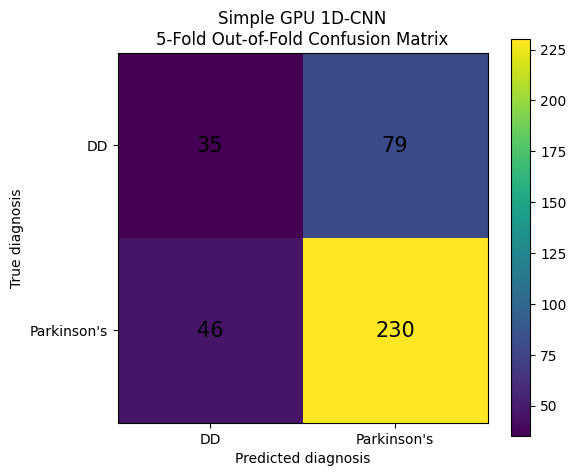

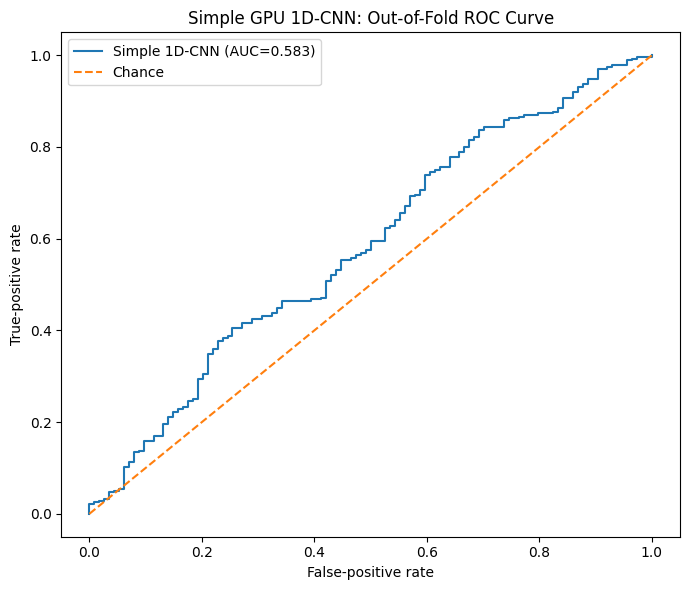

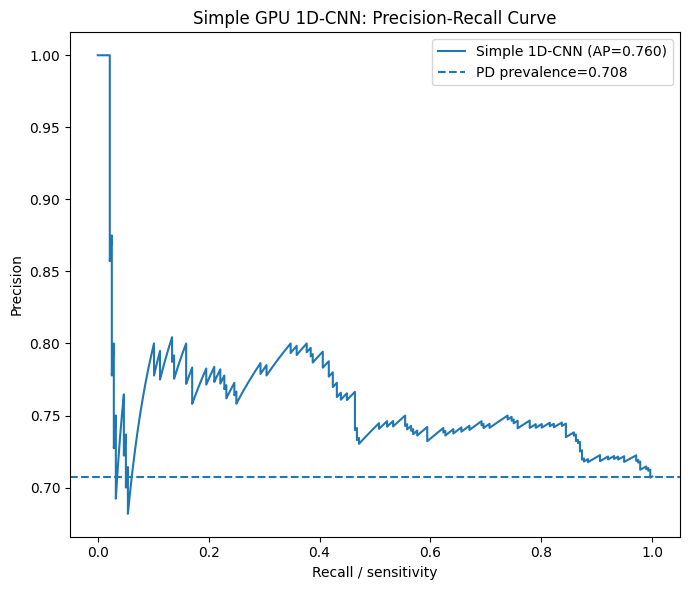

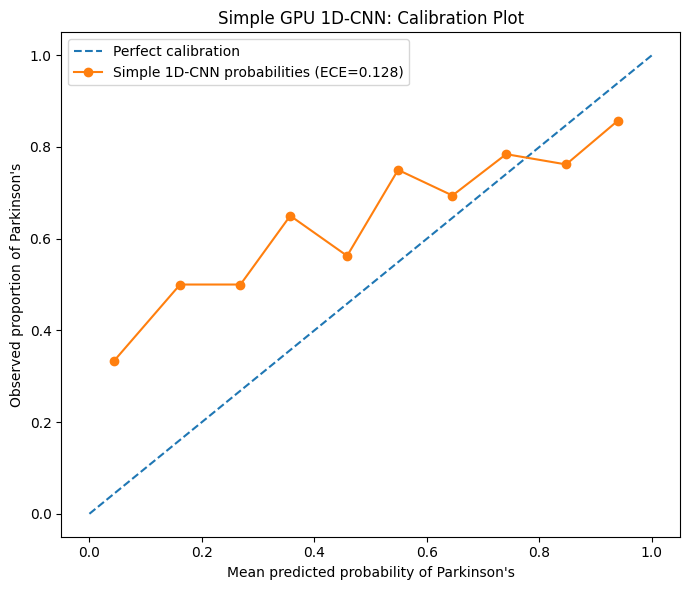

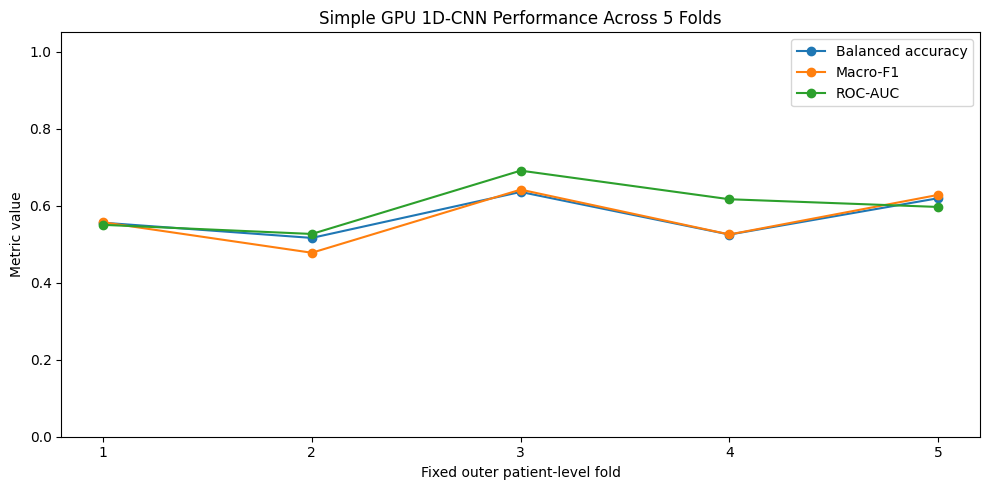

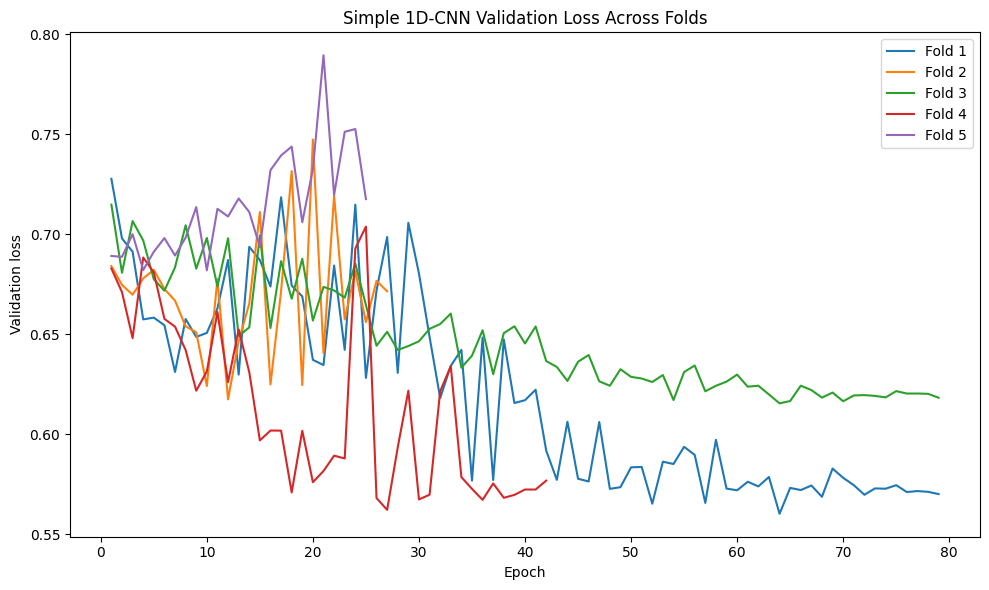

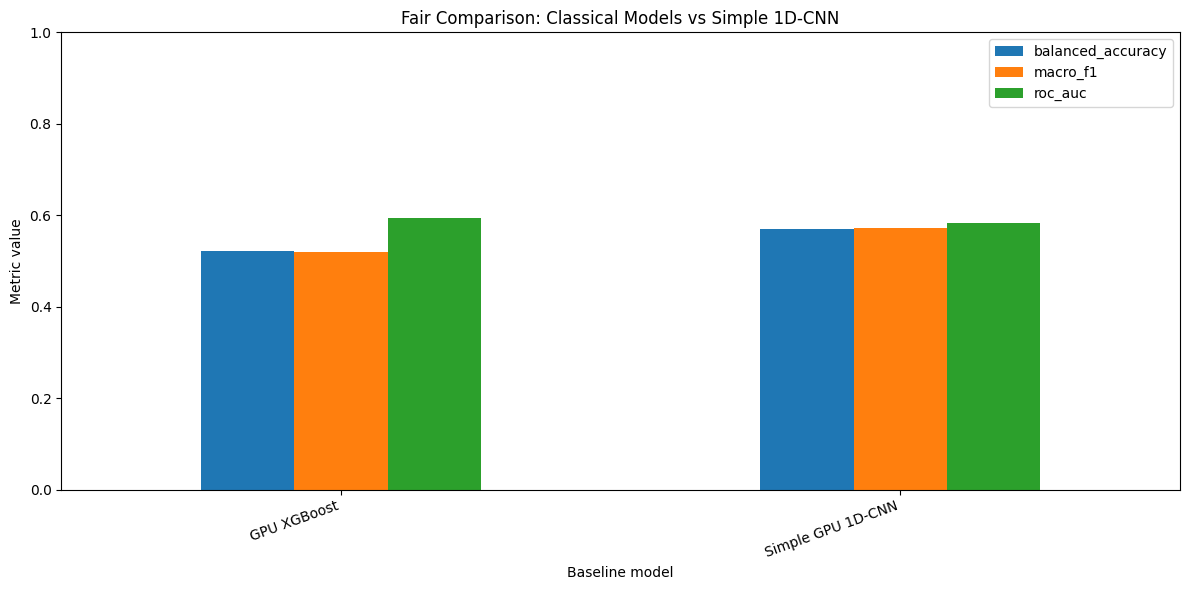


SIMPLE GPU 1D-CNN BASELINE COMPLETE

Out-of-fold classification report:

                        precision    recall  f1-score   support

Differential Diagnosis     0.4321    0.3070    0.3590       114
           Parkinson's     0.7443    0.8333    0.7863       276

              accuracy                         0.6795       390
             macro avg     0.5882    0.5702    0.5726       390
          weighted avg     0.6531    0.6795    0.6614       390


Overall out-of-fold metrics:

accuracy                 : 0.6795
balanced_accuracy        : 0.5702
macro_f1                 : 0.5726
pd_f1                    : 0.7863
dd_f1                    : 0.3590
precision_pd             : 0.7443
sensitivity_pd           : 0.8333
specificity_dd           : 0.3070
ppv_pd                   : 0.7443
npv_dd                   : 0.4321
roc_auc                  : 0.5826
pr_auc                   : 0.7603
brier_score              : 0.2232
ece_10_bins              : 0.1281
true_negative            : 35
fa

In [ ]:
# =====================================================================
# PADS DEEP BASELINE — SIMPLE GPU 1D-CNN
# MAXIMUM 100 EPOCHS | SAME FIXED 5 PATIENT-LEVEL FOLDS
# FULL FAIR OUT-OF-FOLD EVALUATION
# =====================================================================
#
# INPUT SHAPE:
#   patients × tasks × time × channels
#   expected: (390, 11, 976, 12)
#
# ARCHITECTURE:
#   Each of the 11 tasks passes through the SAME shared 1D-CNN encoder:
#
#   Conv1D -> BatchNorm -> MaxPool
#   Conv1D -> BatchNorm -> MaxPool
#   Conv1D -> BatchNorm
#   GlobalAveragePooling1D
#        ↓
#   Average across 11 tasks
#        ↓
#   Dense -> Dropout -> PD probability
#
# FAIR COMPARISON:
# - Same 390 PD-vs-DD patients
# - Same fixed outer five folds
# - Same test patients as classical baselines
# - Training-fold-only normalization
# - Training-fold-only validation split
# - Balanced class weights
# - Fixed classification threshold = 0.50
# - Same evaluation metrics
# - Same 2,000 patient-level bootstrap confidence intervals
#
# TRAINING:
# - Maximum epochs = 100
# - Early stopping patience = 15
# - Batch size = 16
# - Adam optimizer
# - No SMOTE or patient duplication
# =====================================================================

import os
import gc
import sys
import time
import json
import random
import warnings
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# =====================================================================
# 1. IMPORT TENSORFLOW AND CHECK GPU
# =====================================================================

try:
    import tensorflow as tf
except ImportError:
    print("Installing TensorFlow...")
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "tensorflow"
    ])
    import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedShuffleSplit,
)
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    roc_curve,
    precision_recall_curve,
)

print("=" * 100)
print("TENSORFLOW GPU CHECK")
print("=" * 100)

print("TensorFlow version:", tf.__version__)

physical_gpus = tf.config.list_physical_devices("GPU")

if not physical_gpus:
    raise RuntimeError(
        "TensorFlow GPU detect nahi kar raha.\n\n"
        "Google Colab mein select karein:\n"
        "Runtime → Change runtime type → T4 GPU\n\n"
        "Phir runtime restart karke cell dobara run karein."
    )

for gpu in physical_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("Detected GPU devices:", physical_gpus)

try:
    gpu_name = tf.config.experimental.get_device_details(
        physical_gpus[0]
    ).get("device_name", "Unknown GPU")
except Exception:
    gpu_name = "GPU detected"

print("GPU:", gpu_name)

# Mixed precision gives faster Tensor Core training on supported GPUs.
try:
    keras.mixed_precision.set_global_policy("mixed_float16")
    print("Mixed precision policy: mixed_float16")
except Exception:
    keras.mixed_precision.set_global_policy("float32")
    print("Mixed precision unavailable; using float32.")

# Reproducibility
GLOBAL_SEED = 42

random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
tf.keras.utils.set_random_seed(GLOBAL_SEED)

try:
    tf.config.experimental.enable_op_determinism()
    print("TensorFlow deterministic operations enabled.")
except Exception:
    print("Deterministic operations could not be fully enabled.")

# =====================================================================
# 2. PATHS
# =====================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

FEATURE_ENGINEERING_DIR = (
    BASE_DIR
    / "project_ready_data"
    / "feature_engineering"
)

TASKWISE_FILE = (
    FEATURE_ENGINEERING_DIR
    / "pads_pd_dd_taskwise.npz"
)

FEATURE_FILE = (
    FEATURE_ENGINEERING_DIR
    / "pads_engineered_features.csv"
)

BASELINE_ROOT = (
    BASE_DIR
    / "project_ready_data"
    / "baseline_results"
)

LOGISTIC_DIR = (
    BASELINE_ROOT
    / "logistic_regression_5fold"
)

FIXED_SPLIT_FILE = (
    LOGISTIC_DIR
    / "fixed_outer_5fold_splits.csv"
)

OUTPUT_DIR = (
    BASELINE_ROOT
    / "simple_1dcnn_gpu_5fold"
)

FIGURE_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "models"
HISTORY_DIR = OUTPUT_DIR / "training_histories"

for directory in [
    OUTPUT_DIR,
    FIGURE_DIR,
    MODEL_DIR,
    HISTORY_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

if not TASKWISE_FILE.exists():
    possible_files = list(
        BASE_DIR.rglob("pads_pd_dd_taskwise.npz")
    )

    if possible_files:
        TASKWISE_FILE = possible_files[0]
    else:
        raise FileNotFoundError(
            "pads_pd_dd_taskwise.npz nahi mila.\n"
            "Feature-engineering cell dobara run karein."
        )

print("\n" + "=" * 100)
print("SIMPLE GPU 1D-CNN BASELINE")
print("=" * 100)

print("Task-wise data:", TASKWISE_FILE)
print("Fixed folds   :", FIXED_SPLIT_FILE)
print("Output folder :", OUTPUT_DIR)

# =====================================================================
# 3. LOAD TASK-WISE RAW SIGNAL DATA
# =====================================================================

npz_data = np.load(
    TASKWISE_FILE,
    allow_pickle=True
)

required_npz_keys = {
    "X_tasks",
    "y",
    "patient_ids",
}

missing_keys = (
    required_npz_keys
    - set(npz_data.files)
)

if missing_keys:
    raise ValueError(
        f"Task-wise NPZ mein keys missing hain: {missing_keys}"
    )

X_all = npz_data["X_tasks"].astype(np.float32)
y = npz_data["y"].astype(np.int32)

patient_ids = (
    npz_data["patient_ids"]
    .astype(str)
)

patient_ids = np.array([
    str(patient_id).zfill(3)
    for patient_id in patient_ids
])

task_names = (
    npz_data["task_names"].astype(str)
    if "task_names" in npz_data.files
    else np.array([
        f"Task_{index + 1}"
        for index in range(X_all.shape[1])
    ])
)

channel_names = (
    npz_data["channel_names"].astype(str)
    if "channel_names" in npz_data.files
    else np.array([
        f"Channel_{index + 1}"
        for index in range(X_all.shape[-1])
    ])
)

print("\nLoaded raw task-wise tensor:", X_all.shape)
print("Labels shape:", y.shape)
print("Unique patients:", len(np.unique(patient_ids)))

print("\nClass distribution:")
print("Differential Diagnosis:", int(np.sum(y == 0)))
print("Parkinson's disease    :", int(np.sum(y == 1)))

if X_all.ndim != 4:
    raise ValueError(
        f"Expected 4D input, found shape {X_all.shape}"
    )

if X_all.shape[0] != len(y):
    raise ValueError(
        "X and y patient counts do not match."
    )

if len(np.unique(patient_ids)) != len(patient_ids):
    raise ValueError(
        "Duplicate patient IDs detected."
    )

if not np.isfinite(X_all).all():
    print(
        "Warning: NaN/Inf detected. "
        "Non-finite values will be replaced fold-wise."
    )

N_PATIENTS = X_all.shape[0]
N_TASKS = X_all.shape[1]
N_TIMEPOINTS = X_all.shape[2]
N_CHANNELS = X_all.shape[3]

print("\nCNN dimensions:")
print("Patients   :", N_PATIENTS)
print("Tasks      :", N_TASKS)
print("Timepoints :", N_TIMEPOINTS)
print("Channels   :", N_CHANNELS)

# =====================================================================
# 4. LOAD OR RECREATE SAME FIXED 5 FOLDS
# =====================================================================

if FIXED_SPLIT_FILE.exists():

    fixed_splits = pd.read_csv(
        FIXED_SPLIT_FILE,
        dtype={"patient_id": str}
    )

    fixed_splits["patient_id"] = (
        fixed_splits["patient_id"]
        .astype(str)
        .str.zfill(3)
    )

    fixed_splits["role"] = (
        fixed_splits["role"]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    print("\nExisting fixed outer folds loaded.")

else:

    print(
        "\nFixed-fold file missing. "
        "Recreating using the original setting:"
    )

    print(
        "StratifiedKFold("
        "n_splits=5, shuffle=True, random_state=42)"
    )

    LOGISTIC_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    outer_cv_recreate = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    split_rows = []

    dummy_X = np.zeros(
        (len(y), 1),
        dtype=np.float32
    )

    for fold_number, (
        train_indices,
        test_indices
    ) in enumerate(
        outer_cv_recreate.split(
            dummy_X,
            y
        ),
        start=1
    ):

        for index in train_indices:
            split_rows.append({
                "patient_id": patient_ids[index],
                "fold": fold_number,
                "role": "train",
                "true_label": int(y[index]),
            })

        for index in test_indices:
            split_rows.append({
                "patient_id": patient_ids[index],
                "fold": fold_number,
                "role": "test",
                "true_label": int(y[index]),
            })

    fixed_splits = pd.DataFrame(
        split_rows
    )

    fixed_splits.to_csv(
        FIXED_SPLIT_FILE,
        index=False
    )

    print("Fixed folds recreated:", FIXED_SPLIT_FILE)

# Validate fixed-fold structure
required_split_columns = {
    "patient_id",
    "fold",
    "role",
}

if not required_split_columns.issubset(
    fixed_splits.columns
):
    raise ValueError(
        "Fixed split file requires patient_id, fold and role."
    )

available_folds = sorted(
    fixed_splits["fold"].unique()
)

if available_folds != [1, 2, 3, 4, 5]:
    raise ValueError(
        f"Expected folds 1–5; found {available_folds}"
    )

data_ids = set(patient_ids)
split_ids = set(fixed_splits["patient_id"])

if data_ids != split_ids:
    raise ValueError(
        "Task-wise NPZ patient IDs and fixed-fold IDs do not match."
    )

test_frequency = (
    fixed_splits.loc[
        fixed_splits["role"] == "test"
    ]
    .groupby("patient_id")
    .size()
)

if (
    len(test_frequency) != N_PATIENTS
    or not (test_frequency == 1).all()
):
    raise ValueError(
        "Every patient must appear as test exactly once."
    )

patient_to_index = {
    patient_id: index
    for index, patient_id in enumerate(patient_ids)
}

print("Fixed five patient-level folds verified.")

# =====================================================================
# 5. EVALUATION FUNCTIONS — SAME AS CLASSICAL BASELINES
# =====================================================================

def expected_calibration_error(
    y_true,
    probability_pd,
    n_bins=10
):
    y_true = np.asarray(y_true)
    probability_pd = np.asarray(probability_pd)

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for bin_index in range(n_bins):

        lower = bin_edges[bin_index]
        upper = bin_edges[bin_index + 1]

        if bin_index == n_bins - 1:
            mask = (
                (probability_pd >= lower)
                & (probability_pd <= upper)
            )
        else:
            mask = (
                (probability_pd >= lower)
                & (probability_pd < upper)
            )

        if not np.any(mask):
            continue

        mean_probability = np.mean(
            probability_pd[mask]
        )

        observed_rate = np.mean(
            y_true[mask]
        )

        bin_weight = np.mean(mask)

        ece += (
            bin_weight
            * abs(
                observed_rate
                - mean_probability
            )
        )

    return float(ece)


def calculate_metrics(
    y_true,
    y_pred,
    probability_pd
):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    sensitivity_pd = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity_dd = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    ppv_pd = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    npv_dd = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "pd_f1": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "dd_f1": f1_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "precision_pd": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "sensitivity_pd": sensitivity_pd,
        "specificity_dd": specificity_dd,
        "ppv_pd": ppv_pd,
        "npv_dd": npv_dd,

        "roc_auc": roc_auc_score(
            y_true,
            probability_pd
        ),

        "pr_auc": average_precision_score(
            y_true,
            probability_pd
        ),

        "brier_score": brier_score_loss(
            y_true,
            probability_pd
        ),

        "ece_10_bins": expected_calibration_error(
            y_true,
            probability_pd,
            n_bins=10
        ),

        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }

# =====================================================================
# 6. TRAINING-FOLD NORMALIZATION
# =====================================================================

def calculate_training_normalization(
    X_train
):
    """
    Calculate one mean and standard deviation per input channel,
    using outer-training patients only.

    Axes averaged:
    patients, tasks and time.

    Shape returned:
    (1, 1, 1, channels)
    """

    finite_train = np.where(
        np.isfinite(X_train),
        X_train,
        np.nan
    )

    channel_mean = np.nanmean(
        finite_train,
        axis=(0, 1, 2),
        keepdims=True
    )

    channel_std = np.nanstd(
        finite_train,
        axis=(0, 1, 2),
        keepdims=True
    )

    channel_mean = np.where(
        np.isfinite(channel_mean),
        channel_mean,
        0.0
    ).astype(np.float32)

    channel_std = np.where(
        np.isfinite(channel_std)
        & (channel_std > 1e-6),
        channel_std,
        1.0
    ).astype(np.float32)

    return channel_mean, channel_std


def normalize_signals(
    X_data,
    channel_mean,
    channel_std
):
    X_clean = np.where(
        np.isfinite(X_data),
        X_data,
        channel_mean
    )

    X_normalized = (
        X_clean - channel_mean
    ) / channel_std

    X_normalized = np.clip(
        X_normalized,
        -10.0,
        10.0
    )

    return X_normalized.astype(
        np.float32
    )

# =====================================================================
# 7. SIMPLE SHARED TASK-WISE 1D-CNN MODEL
# =====================================================================

def build_simple_1dcnn(
    number_of_tasks,
    number_of_timepoints,
    number_of_channels,
    learning_rate=1e-3
):
    """
    Baseline only:
    - Shared encoder across all tasks
    - No attention
    - No quality-aware weighting
    - No adaptive task selection
    - No explicit bilateral-asymmetry branch
    """

    # Shared encoder receives one task:
    # timepoints × 12 channels
    task_input = keras.Input(
        shape=(
            number_of_timepoints,
            number_of_channels
        ),
        name="single_task_input"
    )

    x = layers.Conv1D(
        filters=32,
        kernel_size=7,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        name="conv1"
    )(task_input)

    x = layers.BatchNormalization(
        name="bn1"
    )(x)

    x = layers.Activation(
        "relu",
        name="relu1"
    )(x)

    x = layers.MaxPooling1D(
        pool_size=2,
        name="pool1"
    )(x)

    x = layers.Conv1D(
        filters=64,
        kernel_size=5,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        name="conv2"
    )(x)

    x = layers.BatchNormalization(
        name="bn2"
    )(x)

    x = layers.Activation(
        "relu",
        name="relu2"
    )(x)

    x = layers.MaxPooling1D(
        pool_size=2,
        name="pool2"
    )(x)

    x = layers.Conv1D(
        filters=128,
        kernel_size=3,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        name="conv3"
    )(x)

    x = layers.BatchNormalization(
        name="bn3"
    )(x)

    x = layers.Activation(
        "relu",
        name="relu3"
    )(x)

    task_embedding = layers.GlobalAveragePooling1D(
        name="task_global_average_pool"
    )(x)

    shared_task_encoder = keras.Model(
        inputs=task_input,
        outputs=task_embedding,
        name="shared_task_encoder"
    )

    # Full patient input:
    # 11 tasks × 976 time × 12 channels
    patient_input = keras.Input(
        shape=(
            number_of_tasks,
            number_of_timepoints,
            number_of_channels
        ),
        name="patient_tasks"
    )

    # Same CNN weights applied to all 11 tasks.
    encoded_tasks = layers.TimeDistributed(
        shared_task_encoder,
        name="shared_encoder_over_tasks"
    )(patient_input)

    # Simple non-adaptive average across tasks.
    patient_embedding = layers.GlobalAveragePooling1D(
        name="equal_average_across_tasks"
    )(encoded_tasks)

    z = layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(
            1e-4
        ),
        name="dense_64"
    )(patient_embedding)

    z = layers.Dropout(
        0.40,
        name="dropout"
    )(z)

    # Force float32 output when mixed precision is active.
    output = layers.Dense(
        1,
        activation="sigmoid",
        dtype="float32",
        name="pd_probability"
    )(z)

    model = keras.Model(
        inputs=patient_input,
        outputs=output,
        name="simple_shared_task_1dcnn"
    )

    optimizer = keras.optimizers.Adam(
        learning_rate=learning_rate,
        clipnorm=1.0
    )

    model.compile(
        optimizer=optimizer,
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[
            keras.metrics.BinaryAccuracy(
                name="accuracy"
            ),
            keras.metrics.AUC(
                name="roc_auc",
                curve="ROC"
            ),
            keras.metrics.AUC(
                name="pr_auc",
                curve="PR"
            ),
        ]
    )

    return model

# Create one temporary model to display architecture.
temporary_model = build_simple_1dcnn(
    N_TASKS,
    N_TIMEPOINTS,
    N_CHANNELS
)

print("\nModel architecture:")
temporary_model.summary()

parameter_count = temporary_model.count_params()

print("\nTotal model parameters:", parameter_count)

del temporary_model
tf.keras.backend.clear_session()

# =====================================================================
# 8. TRAINING CONFIGURATION
# =====================================================================

MAX_EPOCHS = 100
EARLY_STOPPING_PATIENCE = 15
BATCH_SIZE = 16
VALIDATION_FRACTION = 0.20
LEARNING_RATE = 1e-3
PREDICTION_THRESHOLD = 0.50

print("\nTraining configuration:")
print("Maximum epochs        :", MAX_EPOCHS)
print("Early-stopping patience:", EARLY_STOPPING_PATIENCE)
print("Batch size            :", BATCH_SIZE)
print("Validation fraction   :", VALIDATION_FRACTION)
print("Learning rate         :", LEARNING_RATE)
print("Classification threshold:", PREDICTION_THRESHOLD)

# =====================================================================
# 9. OUT-OF-FOLD ARRAYS
# =====================================================================

out_of_fold_probability = np.full(
    N_PATIENTS,
    np.nan,
    dtype=np.float32
)

out_of_fold_prediction = np.full(
    N_PATIENTS,
    -1,
    dtype=np.int32
)

fold_assignments = np.full(
    N_PATIENTS,
    -1,
    dtype=np.int32
)

fold_result_rows = []
training_summary_rows = []
normalization_rows = []

total_start_time = time.time()

print("\n" + "=" * 100)
print("STARTING SIMPLE 1D-CNN FIXED 5-FOLD TRAINING")
print("=" * 100)

# =====================================================================
# 10. FIXED OUTER 5-FOLD TRAINING
# =====================================================================

for fold_number in available_folds:

    fold_start_time = time.time()

    # Clear previous model from GPU memory.
    tf.keras.backend.clear_session()
    gc.collect()

    # Fold-specific deterministic seed.
    fold_seed = GLOBAL_SEED + int(
        fold_number
    )

    random.seed(fold_seed)
    np.random.seed(fold_seed)
    tf.keras.utils.set_random_seed(
        fold_seed
    )

    current_fold = fixed_splits.loc[
        fixed_splits["fold"] == fold_number
    ]

    outer_train_ids = current_fold.loc[
        current_fold["role"] == "train",
        "patient_id"
    ].tolist()

    outer_test_ids = current_fold.loc[
        current_fold["role"] == "test",
        "patient_id"
    ].tolist()

    overlap = set(
        outer_train_ids
    ).intersection(
        set(outer_test_ids)
    )

    if overlap:
        raise RuntimeError(
            f"Patient leakage detected in fold {fold_number}."
        )

    outer_train_indices = np.array([
        patient_to_index[patient_id]
        for patient_id in outer_train_ids
    ])

    outer_test_indices = np.array([
        patient_to_index[patient_id]
        for patient_id in outer_test_ids
    ])

    y_outer_train = y[
        outer_train_indices
    ]

    y_test = y[
        outer_test_indices
    ]

    # ---------------------------------------------------------------
    # Inner validation split created from outer-training patients only.
    # ---------------------------------------------------------------

    validation_splitter = StratifiedShuffleSplit(
        n_splits=1,
        test_size=VALIDATION_FRACTION,
        random_state=fold_seed
    )

    relative_train_indices, relative_val_indices = next(
        validation_splitter.split(
            np.zeros(
                len(outer_train_indices)
            ),
            y_outer_train
        )
    )

    subtrain_indices = outer_train_indices[
        relative_train_indices
    ]

    validation_indices = outer_train_indices[
        relative_val_indices
    ]

    # Verify all three sets are patient-disjoint.
    subtrain_ids = set(
        patient_ids[subtrain_indices]
    )

    validation_ids = set(
        patient_ids[validation_indices]
    )

    test_ids = set(
        patient_ids[outer_test_indices]
    )

    if (
        subtrain_ids.intersection(validation_ids)
        or subtrain_ids.intersection(test_ids)
        or validation_ids.intersection(test_ids)
    ):
        raise RuntimeError(
            f"Train/validation/test leakage in fold {fold_number}."
        )

    X_subtrain_raw = X_all[
        subtrain_indices
    ]

    X_validation_raw = X_all[
        validation_indices
    ]

    X_test_raw = X_all[
        outer_test_indices
    ]

    y_subtrain = y[
        subtrain_indices
    ]

    y_validation = y[
        validation_indices
    ]

    # ---------------------------------------------------------------
    # Normalization statistics from SUBTRAINING patients only.
    # Validation and test patients do not influence normalization.
    # ---------------------------------------------------------------

    channel_mean, channel_std = (
        calculate_training_normalization(
            X_subtrain_raw
        )
    )

    X_subtrain = normalize_signals(
        X_subtrain_raw,
        channel_mean,
        channel_std
    )

    X_validation = normalize_signals(
        X_validation_raw,
        channel_mean,
        channel_std
    )

    X_test = normalize_signals(
        X_test_raw,
        channel_mean,
        channel_std
    )

    # Save normalization statistics.
    for channel_index in range(N_CHANNELS):
        normalization_rows.append({
            "fold": int(fold_number),
            "channel_index": channel_index,
            "channel_mean": float(
                channel_mean[
                    0, 0, 0, channel_index
                ]
            ),
            "channel_std": float(
                channel_std[
                    0, 0, 0, channel_index
                ]
            ),
        })

    # ---------------------------------------------------------------
    # Balanced class weights fitted on SUBTRAINING patients only.
    # ---------------------------------------------------------------

    class_labels = np.array(
        [0, 1],
        dtype=np.int32
    )

    calculated_weights = compute_class_weight(
        class_weight="balanced",
        classes=class_labels,
        y=y_subtrain
    )

    class_weight_dictionary = {
        0: float(calculated_weights[0]),
        1: float(calculated_weights[1]),
    }

    # ---------------------------------------------------------------
    # Build a fresh model for this outer fold.
    # ---------------------------------------------------------------

    model = build_simple_1dcnn(
        number_of_tasks=N_TASKS,
        number_of_timepoints=N_TIMEPOINTS,
        number_of_channels=N_CHANNELS,
        learning_rate=LEARNING_RATE
    )

    fold_model_path = (
        MODEL_DIR
        / f"simple_1dcnn_fold_{fold_number}.keras"
    )

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=EARLY_STOPPING_PATIENCE,
            mode="min",
            restore_best_weights=True,
            verbose=1
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=6,
            min_lr=1e-6,
            mode="min",
            verbose=1
        ),

        keras.callbacks.ModelCheckpoint(
            filepath=str(
                fold_model_path
            ),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            save_weights_only=False,
            verbose=0
        ),

        keras.callbacks.TerminateOnNaN(),
    ]

    print("\n" + "-" * 80)
    print(f"OUTER FOLD {fold_number}/5")
    print("-" * 80)

    print(
        f"Subtraining: {len(subtrain_indices)} "
        f"(PD={np.sum(y_subtrain == 1)}, "
        f"DD={np.sum(y_subtrain == 0)})"
    )

    print(
        f"Validation : {len(validation_indices)} "
        f"(PD={np.sum(y_validation == 1)}, "
        f"DD={np.sum(y_validation == 0)})"
    )

    print(
        f"Testing    : {len(outer_test_indices)} "
        f"(PD={np.sum(y_test == 1)}, "
        f"DD={np.sum(y_test == 0)})"
    )

    print(
        "Class weights:",
        class_weight_dictionary
    )

    history = model.fit(
        X_subtrain,
        y_subtrain,

        validation_data=(
            X_validation,
            y_validation
        ),

        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,

        class_weight=class_weight_dictionary,

        callbacks=callbacks,

        shuffle=True,
        verbose=2
    )

    # Restore model saved at the best validation-loss epoch.
    if fold_model_path.exists():
        model = keras.models.load_model(
            fold_model_path
        )

    history_df = pd.DataFrame(
        history.history
    )

    history_df.insert(
        0,
        "epoch",
        np.arange(
            1,
            len(history_df) + 1
        )
    )

    history_df.to_csv(
        HISTORY_DIR
        / f"fold_{fold_number}_history.csv",
        index=False
    )

    best_epoch = int(
        history_df["val_loss"].idxmin()
        + 1
    )

    best_validation_loss = float(
        history_df["val_loss"].min()
    )

    # ---------------------------------------------------------------
    # Untouched outer-test predictions.
    # ---------------------------------------------------------------

    test_probability = (
        model.predict(
            X_test,
            batch_size=BATCH_SIZE,
            verbose=0
        )
        .reshape(-1)
        .astype(np.float32)
    )

    test_prediction = (
        test_probability
        >= PREDICTION_THRESHOLD
    ).astype(np.int32)

    out_of_fold_probability[
        outer_test_indices
    ] = test_probability

    out_of_fold_prediction[
        outer_test_indices
    ] = test_prediction

    fold_assignments[
        outer_test_indices
    ] = int(fold_number)

    fold_metrics = calculate_metrics(
        y_test,
        test_prediction,
        test_probability
    )

    fold_training_seconds = (
        time.time()
        - fold_start_time
    )

    fold_metrics.update({
        "fold": int(fold_number),

        "subtrain_patients": int(
            len(subtrain_indices)
        ),

        "validation_patients": int(
            len(validation_indices)
        ),

        "test_patients": int(
            len(outer_test_indices)
        ),

        "subtrain_pd": int(
            np.sum(y_subtrain == 1)
        ),

        "subtrain_dd": int(
            np.sum(y_subtrain == 0)
        ),

        "validation_pd": int(
            np.sum(y_validation == 1)
        ),

        "validation_dd": int(
            np.sum(y_validation == 0)
        ),

        "test_pd": int(
            np.sum(y_test == 1)
        ),

        "test_dd": int(
            np.sum(y_test == 0)
        ),

        "dd_class_weight": float(
            class_weight_dictionary[0]
        ),

        "pd_class_weight": float(
            class_weight_dictionary[1]
        ),

        "epochs_completed": int(
            len(history_df)
        ),

        "best_epoch": best_epoch,

        "best_validation_loss": (
            best_validation_loss
        ),

        "training_seconds": float(
            fold_training_seconds
        ),
    })

    fold_result_rows.append(
        fold_metrics
    )

    training_summary_rows.append({
        "fold": int(fold_number),
        "epochs_completed": int(
            len(history_df)
        ),
        "best_epoch": best_epoch,
        "best_validation_loss": (
            best_validation_loss
        ),
        "training_minutes": float(
            fold_training_seconds / 60
        ),
        "model_path": str(
            fold_model_path
        ),
    })

    print("\nFold test results:")

    print(
        f"Balanced accuracy: "
        f"{fold_metrics['balanced_accuracy']:.4f}"
    )

    print(
        f"Macro-F1: "
        f"{fold_metrics['macro_f1']:.4f}"
    )

    print(
        f"Sensitivity PD: "
        f"{fold_metrics['sensitivity_pd']:.4f}"
    )

    print(
        f"Specificity DD: "
        f"{fold_metrics['specificity_dd']:.4f}"
    )

    print(
        f"ROC-AUC: "
        f"{fold_metrics['roc_auc']:.4f}"
    )

    print(
        f"PR-AUC: "
        f"{fold_metrics['pr_auc']:.4f}"
    )

    print(
        f"Confusion: "
        f"TN={fold_metrics['true_negative']}, "
        f"FP={fold_metrics['false_positive']}, "
        f"FN={fold_metrics['false_negative']}, "
        f"TP={fold_metrics['true_positive']}"
    )

    print(
        f"Epochs completed: {len(history_df)} | "
        f"Best epoch: {best_epoch}"
    )

    print(
        f"Fold runtime: "
        f"{fold_training_seconds / 60:.2f} minutes"
    )

    # Release fold arrays and model memory.
    del (
        X_subtrain_raw,
        X_validation_raw,
        X_test_raw,
        X_subtrain,
        X_validation,
        X_test,
        model,
        history
    )

    tf.keras.backend.clear_session()
    gc.collect()

total_training_seconds = (
    time.time()
    - total_start_time
)

# =====================================================================
# 11. VERIFY COMPLETE OUT-OF-FOLD PREDICTIONS
# =====================================================================

if np.isnan(
    out_of_fold_probability
).any():
    raise RuntimeError(
        "Some patients did not receive CNN probabilities."
    )

if np.any(
    out_of_fold_prediction < 0
):
    raise RuntimeError(
        "Some patients did not receive CNN predictions."
    )

if np.any(
    fold_assignments < 1
):
    raise RuntimeError(
        "Some patients were not assigned to a test fold."
    )

overall_metrics = calculate_metrics(
    y,
    out_of_fold_prediction,
    out_of_fold_probability
)

# =====================================================================
# 12. PATIENT-LEVEL BOOTSTRAP 95% CONFIDENCE INTERVALS
# =====================================================================

rng = np.random.default_rng(
    GLOBAL_SEED
)

N_BOOTSTRAPS = 2000
bootstrap_rows = []

for bootstrap_index in range(
    N_BOOTSTRAPS
):

    sampled_indices = rng.integers(
        low=0,
        high=N_PATIENTS,
        size=N_PATIENTS
    )

    sampled_y = y[
        sampled_indices
    ]

    if len(
        np.unique(sampled_y)
    ) < 2:
        continue

    bootstrap_rows.append(
        calculate_metrics(
            sampled_y,
            out_of_fold_prediction[
                sampled_indices
            ],
            out_of_fold_probability[
                sampled_indices
            ]
        )
    )

bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

metrics_for_ci = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

confidence_interval_rows = []

for metric_name in metrics_for_ci:

    metric_values = (
        bootstrap_df[
            metric_name
        ]
        .dropna()
        .to_numpy()
    )

    confidence_interval_rows.append({
        "metric": metric_name,

        "value": overall_metrics[
            metric_name
        ],

        "ci_95_lower": float(
            np.percentile(
                metric_values,
                2.5
            )
        ),

        "ci_95_upper": float(
            np.percentile(
                metric_values,
                97.5
            )
        ),
    })

confidence_intervals_df = pd.DataFrame(
    confidence_interval_rows
)

# =====================================================================
# 13. RESULT TABLES
# =====================================================================

fold_results_df = pd.DataFrame(
    fold_result_rows
)

training_summary_df = pd.DataFrame(
    training_summary_rows
)

normalization_df = pd.DataFrame(
    normalization_rows
)

patient_predictions_df = pd.DataFrame({
    "patient_id": patient_ids,

    "true_label": y,

    "true_group": np.where(
        y == 1,
        "Parkinson's",
        "Differential Diagnosis"
    ),

    "outer_fold": fold_assignments,

    "predicted_probability_pd": (
        out_of_fold_probability
    ),

    "predicted_label": (
        out_of_fold_prediction
    ),

    "predicted_group": np.where(
        out_of_fold_prediction == 1,
        "Parkinson's",
        "Differential Diagnosis"
    ),

    "correct_prediction": (
        out_of_fold_prediction == y
    ).astype(int),
})

summary_df = pd.DataFrame([
    {
        "model": "Simple GPU 1D-CNN",

        "feature_set": (
            "Raw 11-task bilateral accelerometer "
            "and gyroscope signals"
        ),

        "architecture": (
            "Shared task-wise Conv1D encoder "
            "+ equal average task pooling"
        ),

        "novel_components_included": False,

        "explicit_asymmetry_block": False,

        "quality_aware_fusion": False,

        "adaptive_task_selection": False,

        "maximum_epochs": MAX_EPOCHS,

        "early_stopping_patience": (
            EARLY_STOPPING_PATIENCE
        ),

        "batch_size": BATCH_SIZE,

        "classification_threshold": (
            PREDICTION_THRESHOLD
        ),

        "normalization": (
            "Channel-wise training-subset mean/std"
        ),

        "class_balance_method": (
            "Balanced class weights on subtraining patients"
        ),

        "oversampling_used": False,

        "device": gpu_name,

        "mixed_precision": str(
            keras.mixed_precision.global_policy()
        ),

        "patients": N_PATIENTS,

        "pd_patients": int(
            np.sum(y == 1)
        ),

        "dd_patients": int(
            np.sum(y == 0)
        ),

        "outer_folds": 5,

        "validation_fraction": (
            VALIDATION_FRACTION
        ),

        "model_parameters": (
            parameter_count
        ),

        "total_training_minutes": float(
            total_training_seconds / 60
        ),

        **overall_metrics,
    }
])

# =====================================================================
# 14. SAVE TABLES
# =====================================================================

patient_predictions_df.to_csv(
    OUTPUT_DIR
    / "patient_predictions.csv",
    index=False
)

fold_results_df.to_csv(
    OUTPUT_DIR
    / "fold_results.csv",
    index=False
)

summary_df.to_csv(
    OUTPUT_DIR
    / "overall_summary.csv",
    index=False
)

confidence_intervals_df.to_csv(
    OUTPUT_DIR
    / "confidence_intervals_95.csv",
    index=False
)

bootstrap_df.to_csv(
    OUTPUT_DIR
    / "bootstrap_metrics.csv",
    index=False
)

training_summary_df.to_csv(
    OUTPUT_DIR
    / "training_summary_by_fold.csv",
    index=False
)

normalization_df.to_csv(
    OUTPUT_DIR
    / "normalization_statistics_by_fold.csv",
    index=False
)

# =====================================================================
# 15. CONFUSION MATRIX
# =====================================================================

cm = confusion_matrix(
    y,
    out_of_fold_prediction,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.colorbar()

plt.xticks(
    [0, 1],
    ["DD", "Parkinson's"]
)

plt.yticks(
    [0, 1],
    ["DD", "Parkinson's"]
)

plt.xlabel("Predicted diagnosis")
plt.ylabel("True diagnosis")

plt.title(
    "Simple GPU 1D-CNN\n"
    "5-Fold Out-of-Fold Confusion Matrix"
)

for row in range(2):
    for column in range(2):
        plt.text(
            column,
            row,
            str(cm[row, column]),
            ha="center",
            va="center",
            fontsize=15
        )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "01_confusion_matrix.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 16. ROC CURVE
# =====================================================================

fpr, tpr, _ = roc_curve(
    y,
    out_of_fold_probability
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=(
        f"Simple 1D-CNN "
        f"(AUC={overall_metrics['roc_auc']:.3f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance"
)

plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.title("Simple GPU 1D-CNN: Out-of-Fold ROC Curve")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "02_roc_curve.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 17. PRECISION-RECALL CURVE
# =====================================================================

precision_values, recall_values, _ = (
    precision_recall_curve(
        y,
        out_of_fold_probability
    )
)

pd_prevalence = float(
    np.mean(y)
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall_values,
    precision_values,
    label=(
        f"Simple 1D-CNN "
        f"(AP={overall_metrics['pr_auc']:.3f})"
    )
)

plt.axhline(
    pd_prevalence,
    linestyle="--",
    label=(
        f"PD prevalence={pd_prevalence:.3f}"
    )
)

plt.xlabel("Recall / sensitivity")
plt.ylabel("Precision")
plt.title("Simple GPU 1D-CNN: Precision-Recall Curve")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "03_precision_recall_curve.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 18. CALIBRATION PLOT
# =====================================================================

N_BINS = 10

bin_edges = np.linspace(
    0,
    1,
    N_BINS + 1
)

mean_probabilities = []
observed_rates = []

for bin_index in range(N_BINS):

    lower = bin_edges[bin_index]
    upper = bin_edges[bin_index + 1]

    if bin_index == N_BINS - 1:
        mask = (
            (out_of_fold_probability >= lower)
            & (out_of_fold_probability <= upper)
        )
    else:
        mask = (
            (out_of_fold_probability >= lower)
            & (out_of_fold_probability < upper)
        )

    if not np.any(mask):
        continue

    mean_probabilities.append(
        float(
            np.mean(
                out_of_fold_probability[mask]
            )
        )
    )

    observed_rates.append(
        float(
            np.mean(
                y[mask]
            )
        )
    )

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    mean_probabilities,
    observed_rates,
    marker="o",
    label=(
        f"Simple 1D-CNN probabilities "
        f"(ECE={overall_metrics['ece_10_bins']:.3f})"
    )
)

plt.xlabel(
    "Mean predicted probability of Parkinson's"
)

plt.ylabel(
    "Observed proportion of Parkinson's"
)

plt.title(
    "Simple GPU 1D-CNN: Calibration Plot"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "04_calibration_plot.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 19. FOLD PERFORMANCE
# =====================================================================

plt.figure(figsize=(10, 5))

plt.plot(
    fold_results_df["fold"],
    fold_results_df["balanced_accuracy"],
    marker="o",
    label="Balanced accuracy"
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df["macro_f1"],
    marker="o",
    label="Macro-F1"
)

plt.plot(
    fold_results_df["fold"],
    fold_results_df["roc_auc"],
    marker="o",
    label="ROC-AUC"
)

plt.xlabel("Fixed outer patient-level fold")
plt.ylabel("Metric value")

plt.title(
    "Simple GPU 1D-CNN Performance Across 5 Folds"
)

plt.xticks([1, 2, 3, 4, 5])
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "05_fold_performance.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 20. TRAINING CURVES FOR ALL FOLDS
# =====================================================================

plt.figure(figsize=(10, 6))

for fold_number in available_folds:

    history_path = (
        HISTORY_DIR
        / f"fold_{fold_number}_history.csv"
    )

    history_df = pd.read_csv(
        history_path
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_loss"],
        label=f"Fold {fold_number}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Simple 1D-CNN Validation Loss Across Folds")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "06_validation_loss_by_fold.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 21. FAIR COMPARISON WITH CLASSICAL BASELINES
# =====================================================================

classical_summary_files = [
    BASELINE_ROOT
    / "logistic_regression_5fold"
    / "overall_summary.csv",

    BASELINE_ROOT
    / "svm_rbf_corrected_5fold"
    / "overall_summary.csv",

    BASELINE_ROOT
    / "random_forest_5fold"
    / "overall_summary.csv",

    BASELINE_ROOT
    / "xgboost_gpu_5fold"
    / "overall_summary.csv",
]

comparison_rows = []

for summary_file in classical_summary_files:

    if summary_file.exists():

        previous_summary = pd.read_csv(
            summary_file
        )

        comparison_rows.append(
            previous_summary.iloc[0].to_dict()
        )

comparison_rows.append(
    summary_df.iloc[0].to_dict()
)

comparison_df = pd.DataFrame(
    comparison_rows
)

comparison_df.to_csv(
    OUTPUT_DIR
    / "comparison_with_all_baselines.csv",
    index=False
)

comparison_columns = [
    "model",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

available_comparison_columns = [
    column
    for column in comparison_columns
    if column in comparison_df.columns
]

if len(comparison_df) > 1:

    plot_columns = [
        column
        for column in [
            "balanced_accuracy",
            "macro_f1",
            "roc_auc"
        ]
        if column in comparison_df.columns
    ]

    comparison_plot_df = (
        comparison_df[
            ["model"] + plot_columns
        ]
        .set_index("model")
    )

    plt.figure(figsize=(12, 6))

    comparison_plot_df.plot(
        kind="bar",
        ax=plt.gca()
    )

    plt.xlabel("Baseline model")
    plt.ylabel("Metric value")

    plt.title(
        "Fair Comparison: Classical Models vs Simple 1D-CNN"
    )

    plt.xticks(
        rotation=20,
        ha="right"
    )

    plt.ylim(0, 1)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR
        / "07_all_baseline_comparison.png",
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# =====================================================================
# 22. FINAL RESULTS
# =====================================================================

print("\n" + "=" * 100)
print("SIMPLE GPU 1D-CNN BASELINE COMPLETE")
print("=" * 100)

print("\nOut-of-fold classification report:\n")

print(
    classification_report(
        y,
        out_of_fold_prediction,
        target_names=[
            "Differential Diagnosis",
            "Parkinson's",
        ],
        digits=4,
        zero_division=0
    )
)

print("\nOverall out-of-fold metrics:\n")

for metric_name, metric_value in overall_metrics.items():

    if isinstance(
        metric_value,
        (float, np.floating)
    ):
        print(
            f"{metric_name:25s}: "
            f"{metric_value:.4f}"
        )
    else:
        print(
            f"{metric_name:25s}: "
            f"{metric_value}"
        )

print(
    f"\nTotal training time: "
    f"{total_training_seconds / 60:.2f} minutes"
)

print("\nBootstrap 95% confidence intervals:\n")

print(
    confidence_intervals_df
    .round(4)
    .to_string(index=False)
)

print("\nFold-level results:\n")

display_columns = [
    "fold",
    "subtrain_patients",
    "validation_patients",
    "test_patients",
    "test_pd",
    "test_dd",
    "dd_class_weight",
    "pd_class_weight",
    "epochs_completed",
    "best_epoch",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
    "training_seconds",
]

print(
    fold_results_df[
        display_columns
    ]
    .round(4)
    .to_string(index=False)
)

if len(comparison_df) > 1:

    print(
        "\nFair comparison with all completed baselines:\n"
    )

    print(
        comparison_df[
            available_comparison_columns
        ]
        .round(4)
        .to_string(index=False)
    )

print("\nFair-comparison controls:")
print("- Same 390 patients.")
print("- Same fixed outer five patient-level folds.")
print("- Every patient tested exactly once.")
print("- Validation patients selected only from outer training fold.")
print("- Normalization fitted only on subtraining signals.")
print("- Balanced class weights fitted only on subtraining patients.")
print("- Fixed probability threshold of 0.50.")
print("- Same evaluation metrics and bootstrap procedure.")
print("- No SMOTE, oversampling or patient duplication.")

print("\nBaseline architecture controls:")
print("- Shared CNN encoder across all tasks.")
print("- Equal average pooling across tasks.")
print("- No quality-aware fusion.")
print("- No adaptive task selection.")
print("- No explicit bilateral-asymmetry branch.")
print("- No calibrated referral mechanism.")
print("- No missing-task augmentation.")
print("- No attention-based explainability.")

print("\nSaved files:")

for path in sorted(
    OUTPUT_DIR.rglob("*")
):
    if path.is_file():
        print(
            " -",
            path.relative_to(
                OUTPUT_DIR
            )
        )

print(
    "\n✅ SIMPLE RAW-SIGNAL GPU 1D-CNN BASELINE FINISHED."
)

## Feature-set ablation (XGBoost)

GPU XGBOOST FEATURE-SET ABLATION
XGBoost version: 3.3.0
✅ XGBoost GPU test successful.

Feature table: (390, 1486)
Patients: 390
PD: 276
DD: 114

Existing fixed folds loaded.
✅ Same fixed five outer folds verified.

Feature-set dimensions:
Movement only                             : 1056 features
Movement + bilateral                      : 1254 features
Complete: movement + bilateral + quality  : 1474 features

Each feature set: 32 parameter combinations × 3 inner folds × 5 outer folds

EXPERIMENT 1/3: MOVEMENT ONLY

Fold 1/5 | Features=1056 | BA=0.5866 | F1=0.5885 | AUC=0.6253 | DD specificity=0.3913

Fold 2/5 | Features=1056 | BA=0.5486 | F1=0.5477 | AUC=0.4806 | DD specificity=0.2609

Fold 3/5 | Features=1056 | BA=0.5051 | F1=0.4944 | AUC=0.5186 | DD specificity=0.1739

Fold 4/5 | Features=1056 | BA=0.5577 | F1=0.5571 | AUC=0.6743 | DD specificity=0.2609

Fold 5/5 | Features=1056 | BA=0.5568 | F1=0.5568 | AUC=0.6136 | DD specificity=0.3636


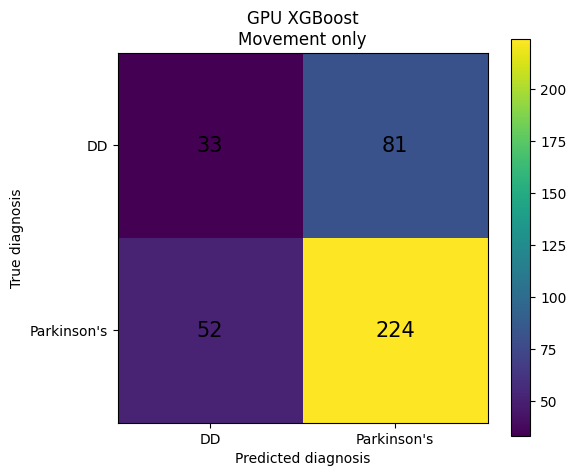


Overall results:
Balanced accuracy: 0.5505
Macro-F1: 0.5514
ROC-AUC: 0.5708
PR-AUC: 0.7473
PD sensitivity: 0.8116
DD specificity: 0.2895

EXPERIMENT 2/3: MOVEMENT + BILATERAL

Fold 1/5 | Features=1254 | BA=0.5178 | F1=0.5129 | AUC=0.5565 | DD specificity=0.2174

Fold 2/5 | Features=1254 | BA=0.4652 | F1=0.4508 | AUC=0.5557 | DD specificity=0.1304

Fold 3/5 | Features=1254 | BA=0.5466 | F1=0.5471 | AUC=0.5605 | DD specificity=0.3478

Fold 4/5 | Features=1254 | BA=0.5613 | F1=0.5629 | AUC=0.6704 | DD specificity=0.3043

Fold 5/5 | Features=1254 | BA=0.5195 | F1=0.5111 | AUC=0.6526 | DD specificity=0.1818


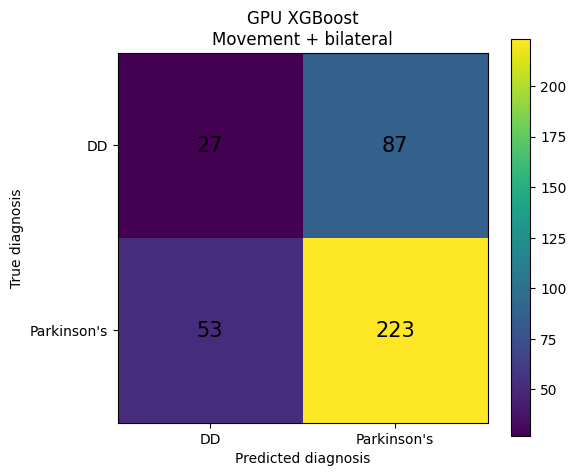


Overall results:
Balanced accuracy: 0.5224
Macro-F1: 0.5197
ROC-AUC: 0.5942
PR-AUC: 0.7812
PD sensitivity: 0.8080
DD specificity: 0.2368

EXPERIMENT 3/3: COMPLETE: MOVEMENT + BILATERAL + QUALITY

Fold 1/5 | Features=1474 | BA=0.4905 | F1=0.4872 | AUC=0.5067 | DD specificity=0.2174

Fold 2/5 | Features=1474 | BA=0.5593 | F1=0.5585 | AUC=0.6221 | DD specificity=0.3913

Fold 3/5 | Features=1474 | BA=0.5921 | F1=0.5966 | AUC=0.6111 | DD specificity=0.3478

Fold 4/5 | Features=1474 | BA=0.6229 | F1=0.6302 | AUC=0.7407 | DD specificity=0.3913

Fold 5/5 | Features=1474 | BA=0.5609 | F1=0.5629 | AUC=0.6015 | DD specificity=0.3182


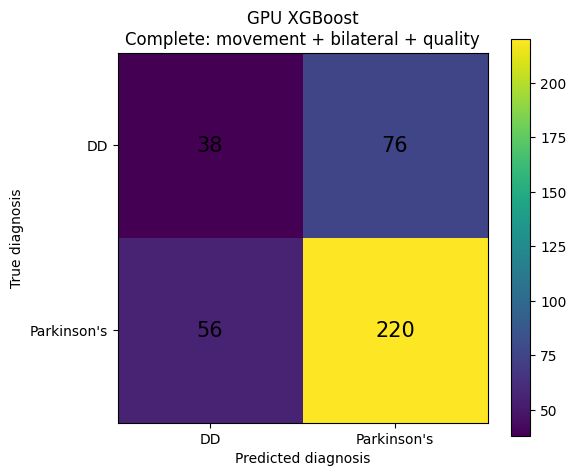


Overall results:
Balanced accuracy: 0.5652
Macro-F1: 0.5673
ROC-AUC: 0.6137
PR-AUC: 0.7934
PD sensitivity: 0.7971
DD specificity: 0.3333


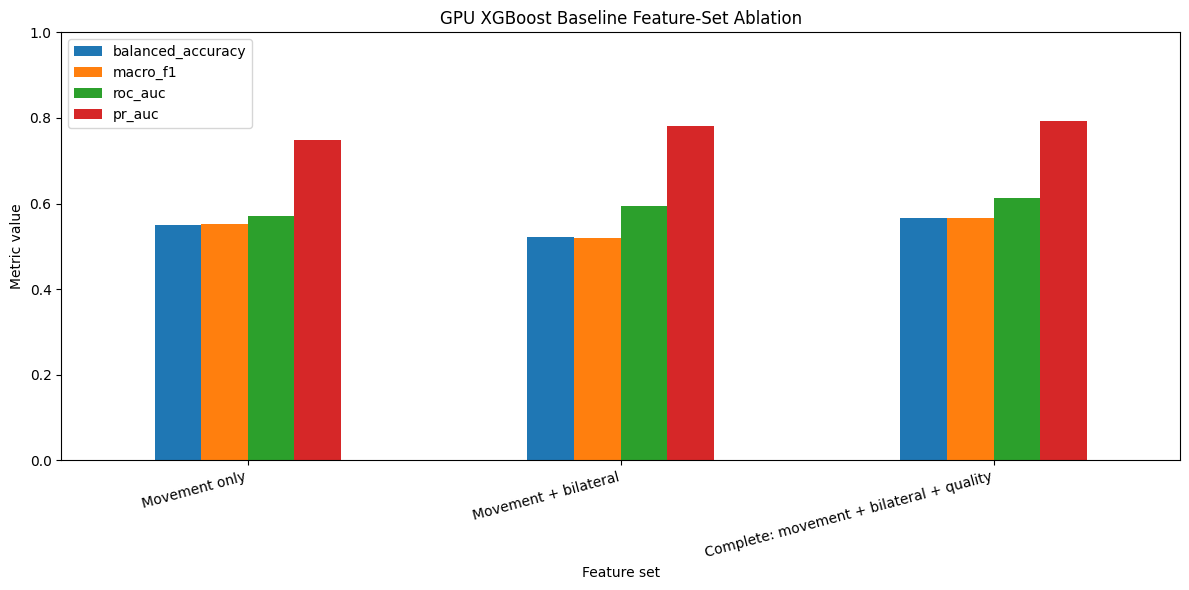

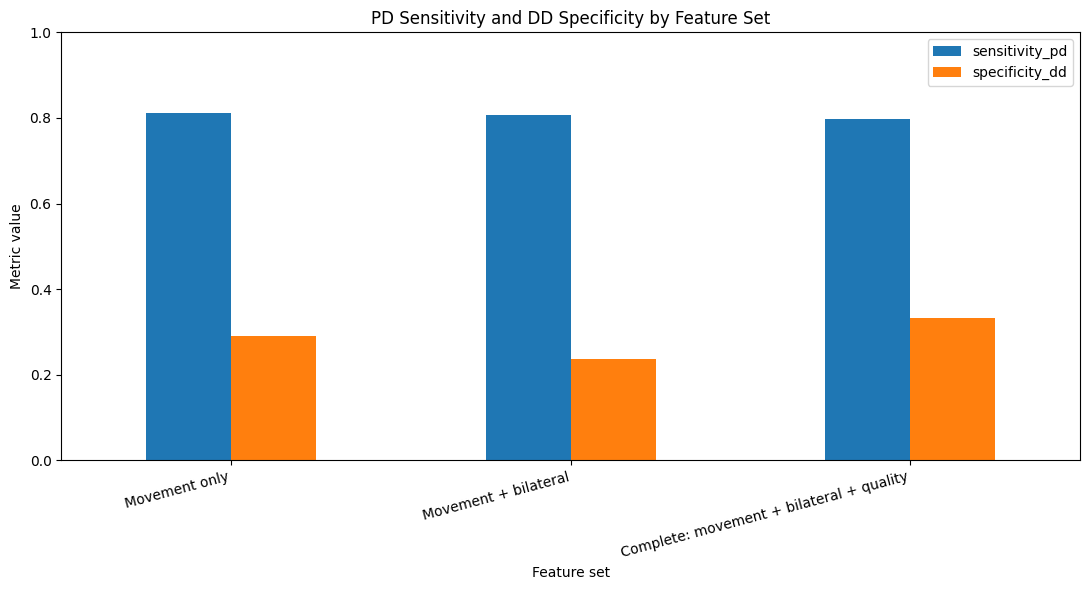


BASELINE FEATURE-SET ABLATION COMPLETE
      model                              feature_set  number_of_input_features  balanced_accuracy  macro_f1  sensitivity_pd  specificity_dd  roc_auc  pr_auc  brier_score  ece_10_bins
GPU XGBoost                            Movement only                      1056             0.5505    0.5514          0.8116          0.2895   0.5708  0.7473       0.2478       0.1724
GPU XGBoost                     Movement + bilateral                      1254             0.5224    0.5197          0.8080          0.2368   0.5942  0.7812       0.2359       0.1658
GPU XGBoost Complete: movement + bilateral + quality                      1474             0.5652    0.5673          0.7971          0.3333   0.6137  0.7934       0.2238       0.1241

Total runtime: 79.56 minutes

Scientific meaning:
- Movement only determines performance without explicit bilateral-asymmetry features.
- Movement + bilateral tests the independent value of engineered left-right asymmetry.
- Co

In [ ]:
# =====================================================================
# BASELINE FEATURE-SET ABLATION — GPU XGBOOST
# MOVEMENT ONLY vs MOVEMENT+BILATERAL vs COMPLETE
# SAME FIXED 5 OUTER FOLDS + INNER 3-FOLD TUNING
# =====================================================================

import os
import sys
import time
import shutil
import warnings
import subprocess
from pathlib import Path
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# =====================================================================
# 1. GPU AND XGBOOST CHECK
# =====================================================================

print("=" * 100)
print("GPU XGBOOST FEATURE-SET ABLATION")
print("=" * 100)

if shutil.which("nvidia-smi") is None:
    raise RuntimeError(
        "GPU detect nahi hui. Colab mein:\n"
        "Runtime → Change runtime type → T4 GPU"
    )

subprocess.run(["nvidia-smi"], check=False)

try:
    import xgboost as xgb
    from xgboost import XGBClassifier
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "xgboost"
    ])
    import xgboost as xgb
    from xgboost import XGBClassifier

print("XGBoost version:", xgb.__version__)

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest,
    mutual_info_classif,
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    roc_curve,
    precision_recall_curve,
)

# Quick CUDA test
test_model = XGBClassifier(
    n_estimators=2,
    max_depth=2,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    device="cuda",
    n_jobs=1,
    random_state=42,
    verbosity=0,
)

_test_x = np.random.default_rng(42).normal(size=(30, 5)).astype(np.float32)
_test_y = np.array([0, 1] * 15)

test_model.fit(_test_x, _test_y)
print("✅ XGBoost GPU test successful.")

# =====================================================================
# 2. PATHS
# =====================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

FEATURE_FILE = (
    BASE_DIR
    / "project_ready_data"
    / "feature_engineering"
    / "pads_engineered_features.csv"
)

BASELINE_ROOT = (
    BASE_DIR
    / "project_ready_data"
    / "baseline_results"
)

FIXED_SPLIT_FILE = (
    BASELINE_ROOT
    / "logistic_regression_5fold"
    / "fixed_outer_5fold_splits.csv"
)

OUTPUT_DIR = (
    BASELINE_ROOT
    / "xgboost_feature_set_ablation"
)

FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not FEATURE_FILE.exists():
    raise FileNotFoundError(
        f"Feature file nahi mili:\n{FEATURE_FILE}"
    )

# =====================================================================
# 3. LOAD DATA
# =====================================================================

df = pd.read_csv(
    FEATURE_FILE,
    dtype={"patient_id": str}
)

df["patient_id"] = (
    df["patient_id"]
    .astype(str)
    .str.zfill(3)
)

if "y" not in df.columns:
    raise ValueError("Target column 'y' missing hai.")

if df["patient_id"].duplicated().any():
    raise ValueError("Duplicate patient IDs detected.")

y = df["y"].astype(int).to_numpy()
patient_ids = df["patient_id"].to_numpy()

print("\nFeature table:", df.shape)
print("Patients:", len(patient_ids))
print("PD:", int(np.sum(y == 1)))
print("DD:", int(np.sum(y == 0)))

# =====================================================================
# 4. LOAD OR RECREATE SAME FIXED 5 FOLDS
# =====================================================================

if FIXED_SPLIT_FILE.exists():

    fixed_splits = pd.read_csv(
        FIXED_SPLIT_FILE,
        dtype={"patient_id": str}
    )

    fixed_splits["patient_id"] = (
        fixed_splits["patient_id"]
        .astype(str)
        .str.zfill(3)
    )

    fixed_splits["role"] = (
        fixed_splits["role"]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    print("\nExisting fixed folds loaded.")

else:

    print("\nFixed folds missing; same original folds recreate ki ja rahi hain.")

    FIXED_SPLIT_FILE.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    outer_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    split_rows = []
    dummy_x = np.zeros((len(y), 1))

    for fold, (train_idx, test_idx) in enumerate(
        outer_cv.split(dummy_x, y),
        start=1
    ):

        for index in train_idx:
            split_rows.append({
                "patient_id": patient_ids[index],
                "fold": fold,
                "role": "train",
                "true_label": int(y[index]),
            })

        for index in test_idx:
            split_rows.append({
                "patient_id": patient_ids[index],
                "fold": fold,
                "role": "test",
                "true_label": int(y[index]),
            })

    fixed_splits = pd.DataFrame(split_rows)

    fixed_splits.to_csv(
        FIXED_SPLIT_FILE,
        index=False
    )

available_folds = sorted(
    fixed_splits["fold"].unique()
)

if available_folds != [1, 2, 3, 4, 5]:
    raise ValueError(
        f"Expected folds 1–5, found {available_folds}"
    )

if set(fixed_splits["patient_id"]) != set(patient_ids):
    raise ValueError(
        "Fixed-fold patient IDs feature table se match nahi karte."
    )

test_frequency = (
    fixed_splits[
        fixed_splits["role"] == "test"
    ]
    .groupby("patient_id")
    .size()
)

if (
    len(test_frequency) != len(patient_ids)
    or not (test_frequency == 1).all()
):
    raise ValueError(
        "Har patient outer testing mein exactly once hona chahiye."
    )

patient_to_index = {
    patient_id: index
    for index, patient_id in enumerate(patient_ids)
}

print("✅ Same fixed five outer folds verified.")

# =====================================================================
# 5. DEFINE THREE FEATURE SETS
# =====================================================================

non_predictor_columns = {
    "patient_id",
    "y",
    "diagnosis_group",
    "original_condition",
    "condition",
    "disease_comment",
    "gender",
    "handedness",
}

demographic_columns = {
    "age",
    "age_at_diagnosis",
    "height",
    "weight",
    "bmi",
    "gender_encoded",
    "handedness_encoded",
    "appearance_in_kinship",
    "appearance_in_first_grade_kinship",
    "effect_of_alcohol_on_tremor",
}

quality_patterns = [
    "__missing_ratio",
    "__flat_difference_ratio",
    "__spike_ratio",
    "__repeated_value_ratio",
    "__technical_quality_score",
    "mean_technical_quality",
    "quality_score",
]

bilateral_patterns = [
    "__Bilateral__",
    "__bilateral__",
    "bilateral_",
    "_bilateral",
]

def contains_pattern(column_name, patterns):
    name_lower = column_name.lower()

    return any(
        pattern.lower() in name_lower
        for pattern in patterns
    )

base_numeric_columns = []

for column in df.columns:

    if column in non_predictor_columns:
        continue

    if column in demographic_columns:
        continue

    if not pd.api.types.is_numeric_dtype(df[column]):
        continue

    base_numeric_columns.append(column)

movement_only_columns = [
    column
    for column in base_numeric_columns
    if not contains_pattern(column, quality_patterns)
    and not contains_pattern(column, bilateral_patterns)
]

movement_bilateral_columns = [
    column
    for column in base_numeric_columns
    if not contains_pattern(column, quality_patterns)
]

complete_columns = list(
    base_numeric_columns
)

feature_sets = {
    "Movement only": movement_only_columns,
    "Movement + bilateral": movement_bilateral_columns,
    "Complete: movement + bilateral + quality": complete_columns,
}

print("\nFeature-set dimensions:")

for feature_set_name, columns in feature_sets.items():
    print(
        f"{feature_set_name:42s}: {len(columns)} features"
    )

if len(movement_only_columns) == len(movement_bilateral_columns):
    raise ValueError(
        "Bilateral features identify nahi huay. "
        "Feature names check karein."
    )

if len(movement_bilateral_columns) == len(complete_columns):
    raise ValueError(
        "Quality features identify nahi huay. "
        "Quality feature naming check karein."
    )

# Save exact feature lists
for feature_set_name, columns in feature_sets.items():

    safe_name = (
        feature_set_name
        .lower()
        .replace(":", "")
        .replace("+", "plus")
        .replace(" ", "_")
    )

    pd.DataFrame({
        "feature_name": columns
    }).to_csv(
        OUTPUT_DIR / f"{safe_name}_feature_list.csv",
        index=False
    )

# =====================================================================
# 6. SHARED METRIC FUNCTIONS
# =====================================================================

def expected_calibration_error(
    y_true,
    probability_pd,
    n_bins=10
):
    y_true = np.asarray(y_true)
    probability_pd = np.asarray(probability_pd)

    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for bin_index in range(n_bins):

        lower = edges[bin_index]
        upper = edges[bin_index + 1]

        if bin_index == n_bins - 1:
            mask = (
                (probability_pd >= lower)
                & (probability_pd <= upper)
            )
        else:
            mask = (
                (probability_pd >= lower)
                & (probability_pd < upper)
            )

        if not np.any(mask):
            continue

        predicted_rate = np.mean(
            probability_pd[mask]
        )

        observed_rate = np.mean(
            y_true[mask]
        )

        ece += np.mean(mask) * abs(
            observed_rate - predicted_rate
        )

    return float(ece)


def calculate_metrics(
    y_true,
    y_pred,
    probability_pd
):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    sensitivity_pd = (
        tp / (tp + fn)
        if (tp + fn) > 0 else np.nan
    )

    specificity_dd = (
        tn / (tn + fp)
        if (tn + fp) > 0 else np.nan
    )

    ppv_pd = (
        tp / (tp + fp)
        if (tp + fp) > 0 else np.nan
    )

    npv_dd = (
        tn / (tn + fn)
        if (tn + fn) > 0 else np.nan
    )

    return {
        "accuracy": accuracy_score(y_true, y_pred),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "pd_f1": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "dd_f1": f1_score(
            y_true,
            y_pred,
            pos_label=0,
            zero_division=0
        ),

        "precision_pd": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "sensitivity_pd": sensitivity_pd,
        "specificity_dd": specificity_dd,
        "ppv_pd": ppv_pd,
        "npv_dd": npv_dd,

        "roc_auc": roc_auc_score(
            y_true,
            probability_pd
        ),

        "pr_auc": average_precision_score(
            y_true,
            probability_pd
        ),

        "brier_score": brier_score_loss(
            y_true,
            probability_pd
        ),

        "ece_10_bins": expected_calibration_error(
            y_true,
            probability_pd,
            n_bins=10
        ),

        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
    }

# =====================================================================
# 7. SHARED GPU XGBOOST PIPELINE AND GRID
# =====================================================================

mutual_information_score = partial(
    mutual_info_classif,
    random_state=42
)

def create_pipeline():

    return Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),

        (
            "variance_filter",
            VarianceThreshold(threshold=0.0)
        ),

        (
            "feature_selector",
            SelectKBest(
                score_func=mutual_information_score,
                k=50
            )
        ),

        (
            "classifier",
            XGBClassifier(
                objective="binary:logistic",
                eval_metric="logloss",
                tree_method="hist",
                device="cuda",
                random_state=42,
                n_jobs=1,
                verbosity=0,
                min_child_weight=1,
                reg_lambda=1.0,
            )
        ),
    ])

parameter_grid = {
    "feature_selector__k": [
        25,
        50,
        100,
        200,
    ],

    "classifier__n_estimators": [
        200,
        400,
    ],

    "classifier__learning_rate": [
        0.03,
        0.10,
    ],

    "classifier__max_depth": [
        2,
        4,
    ],

    "classifier__subsample": [
        0.8,
    ],

    "classifier__colsample_bytree": [
        0.8,
    ],
}

inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=142
)

print(
    "\nEach feature set:",
    32,
    "parameter combinations × 3 inner folds × 5 outer folds"
)

# =====================================================================
# 8. RUN ALL THREE FEATURE-SET EXPERIMENTS
# =====================================================================

all_summary_rows = []
all_fold_rows = []
all_prediction_rows = []
all_parameter_rows = []
all_bootstrap_rows = []

overall_start_time = time.time()

for experiment_number, (
    feature_set_name,
    feature_columns
) in enumerate(
    feature_sets.items(),
    start=1
):

    print("\n" + "=" * 100)
    print(
        f"EXPERIMENT {experiment_number}/3: "
        f"{feature_set_name.upper()}"
    )
    print("=" * 100)

    X = (
        df[feature_columns]
        .copy()
        .replace([np.inf, -np.inf], np.nan)
    )

    valid_k_values = [
        k
        for k in parameter_grid[
            "feature_selector__k"
        ]
        if k < X.shape[1]
    ]

    if len(valid_k_values) == 0:
        valid_k_values = ["all"]

    current_grid = dict(parameter_grid)
    current_grid[
        "feature_selector__k"
    ] = valid_k_values

    oof_probability = np.full(
        len(y),
        np.nan,
        dtype=float
    )

    oof_prediction = np.full(
        len(y),
        -1,
        dtype=int
    )

    fold_assignment = np.full(
        len(y),
        -1,
        dtype=int
    )

    experiment_fold_rows = []

    experiment_start_time = time.time()

    for fold_number in available_folds:

        fold_start_time = time.time()

        fold_information = fixed_splits[
            fixed_splits["fold"] == fold_number
        ]

        train_ids = fold_information.loc[
            fold_information["role"] == "train",
            "patient_id"
        ].tolist()

        test_ids = fold_information.loc[
            fold_information["role"] == "test",
            "patient_id"
        ].tolist()

        if set(train_ids).intersection(test_ids):
            raise RuntimeError(
                f"Patient leakage in fold {fold_number}"
            )

        train_indices = np.array([
            patient_to_index[patient_id]
            for patient_id in train_ids
        ])

        test_indices = np.array([
            patient_to_index[patient_id]
            for patient_id in test_ids
        ])

        X_train = X.iloc[train_indices]
        X_test = X.iloc[test_indices]

        y_train = y[train_indices]
        y_test = y[test_indices]

        train_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_train
        )

        search = GridSearchCV(
            estimator=create_pipeline(),
            param_grid=current_grid,
            scoring="balanced_accuracy",
            cv=inner_cv,

            # Single GPU: no parallel GPU fitting
            n_jobs=1,

            refit=True,
            return_train_score=False,
            error_score="raise",
            verbose=0,
        )

        search.fit(
            X_train,
            y_train,
            classifier__sample_weight=train_weights
        )

        best_model = search.best_estimator_

        test_prediction = (
            best_model.predict(X_test)
            .astype(int)
        )

        probability_matrix = (
            best_model.predict_proba(X_test)
        )

        class_order = (
            best_model
            .named_steps["classifier"]
            .classes_
        )

        pd_column = int(
            np.where(class_order == 1)[0][0]
        )

        test_probability = (
            probability_matrix[:, pd_column]
        )

        oof_prediction[test_indices] = (
            test_prediction
        )

        oof_probability[test_indices] = (
            test_probability
        )

        fold_assignment[test_indices] = (
            int(fold_number)
        )

        metrics = calculate_metrics(
            y_test,
            test_prediction,
            test_probability
        )

        fold_runtime = (
            time.time() - fold_start_time
        )

        fold_row = {
            "feature_set": feature_set_name,
            "fold": int(fold_number),

            "number_of_features": int(
                X.shape[1]
            ),

            "train_patients": int(
                len(train_indices)
            ),

            "test_patients": int(
                len(test_indices)
            ),

            "train_pd": int(
                np.sum(y_train == 1)
            ),

            "train_dd": int(
                np.sum(y_train == 0)
            ),

            "test_pd": int(
                np.sum(y_test == 1)
            ),

            "test_dd": int(
                np.sum(y_test == 0)
            ),

            "best_inner_balanced_accuracy": float(
                search.best_score_
            ),

            "training_seconds": float(
                fold_runtime
            ),

            **metrics,
        }

        experiment_fold_rows.append(
            fold_row
        )

        all_fold_rows.append(
            fold_row
        )

        parameter_row = {
            "feature_set": feature_set_name,
            "fold": int(fold_number),
            "best_inner_balanced_accuracy": float(
                search.best_score_
            ),
            **search.best_params_,
        }

        all_parameter_rows.append(
            parameter_row
        )

        print(
            f"\nFold {fold_number}/5 | "
            f"Features={X.shape[1]} | "
            f"BA={metrics['balanced_accuracy']:.4f} | "
            f"F1={metrics['macro_f1']:.4f} | "
            f"AUC={metrics['roc_auc']:.4f} | "
            f"DD specificity={metrics['specificity_dd']:.4f}"
        )

    if np.isnan(oof_probability).any():
        raise RuntimeError(
            f"Missing probabilities in {feature_set_name}"
        )

    if np.any(oof_prediction < 0):
        raise RuntimeError(
            f"Missing predictions in {feature_set_name}"
        )

    overall_metrics = calculate_metrics(
        y,
        oof_prediction,
        oof_probability
    )

    # ---------------------------------------------------------------
    # Patient-level bootstrap confidence intervals
    # ---------------------------------------------------------------

    rng = np.random.default_rng(42)
    bootstrap_rows = []

    for bootstrap_index in range(2000):

        sampled_indices = rng.integers(
            0,
            len(y),
            size=len(y)
        )

        sampled_y = y[sampled_indices]

        if len(np.unique(sampled_y)) < 2:
            continue

        bootstrap_metrics = calculate_metrics(
            sampled_y,
            oof_prediction[sampled_indices],
            oof_probability[sampled_indices]
        )

        bootstrap_metrics.update({
            "feature_set": feature_set_name,
            "bootstrap_iteration": bootstrap_index,
        })

        bootstrap_rows.append(
            bootstrap_metrics
        )

    bootstrap_df = pd.DataFrame(
        bootstrap_rows
    )

    all_bootstrap_rows.extend(
        bootstrap_rows
    )

    experiment_minutes = (
        time.time() - experiment_start_time
    ) / 60

    summary_row = {
        "model": "GPU XGBoost",
        "feature_set": feature_set_name,

        "number_of_input_features": int(
            X.shape[1]
        ),

        "patients": int(len(y)),
        "pd_patients": int(np.sum(y == 1)),
        "dd_patients": int(np.sum(y == 0)),

        "outer_folds": 5,
        "inner_folds": 3,

        "class_balance_method": (
            "Balanced sample weights"
        ),

        "oversampling_used": False,

        "training_minutes": float(
            experiment_minutes
        ),

        **overall_metrics,
    }

    all_summary_rows.append(
        summary_row
    )

    for index in range(len(y)):

        all_prediction_rows.append({
            "feature_set": feature_set_name,
            "patient_id": patient_ids[index],
            "true_label": int(y[index]),
            "outer_fold": int(
                fold_assignment[index]
            ),
            "predicted_probability_pd": float(
                oof_probability[index]
            ),
            "predicted_label": int(
                oof_prediction[index]
            ),
            "correct_prediction": int(
                oof_prediction[index] == y[index]
            ),
        })

    # ---------------------------------------------------------------
    # Save confusion matrix for this feature set
    # ---------------------------------------------------------------

    cm = confusion_matrix(
        y,
        oof_prediction,
        labels=[0, 1]
    )

    plt.figure(figsize=(6, 5))
    plt.imshow(cm)
    plt.colorbar()

    plt.xticks(
        [0, 1],
        ["DD", "Parkinson's"]
    )

    plt.yticks(
        [0, 1],
        ["DD", "Parkinson's"]
    )

    plt.xlabel("Predicted diagnosis")
    plt.ylabel("True diagnosis")

    plt.title(
        f"GPU XGBoost\n{feature_set_name}"
    )

    for row in range(2):
        for column in range(2):
            plt.text(
                column,
                row,
                str(cm[row, column]),
                ha="center",
                va="center",
                fontsize=15
            )

    safe_name = (
        feature_set_name
        .lower()
        .replace(":", "")
        .replace("+", "plus")
        .replace(" ", "_")
    )

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR
        / f"{safe_name}_confusion_matrix.png",
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print("\nOverall results:")
    print(
        f"Balanced accuracy: "
        f"{overall_metrics['balanced_accuracy']:.4f}"
    )
    print(
        f"Macro-F1: "
        f"{overall_metrics['macro_f1']:.4f}"
    )
    print(
        f"ROC-AUC: "
        f"{overall_metrics['roc_auc']:.4f}"
    )
    print(
        f"PR-AUC: "
        f"{overall_metrics['pr_auc']:.4f}"
    )
    print(
        f"PD sensitivity: "
        f"{overall_metrics['sensitivity_pd']:.4f}"
    )
    print(
        f"DD specificity: "
        f"{overall_metrics['specificity_dd']:.4f}"
    )

# =====================================================================
# 9. SAVE FINAL TABLES
# =====================================================================

summary_df = pd.DataFrame(
    all_summary_rows
)

fold_results_df = pd.DataFrame(
    all_fold_rows
)

predictions_df = pd.DataFrame(
    all_prediction_rows
)

parameters_df = pd.DataFrame(
    all_parameter_rows
)

bootstrap_all_df = pd.DataFrame(
    all_bootstrap_rows
)

ci_rows = []

ci_metrics = [
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

for feature_set_name in feature_sets.keys():

    subset = bootstrap_all_df[
        bootstrap_all_df["feature_set"]
        == feature_set_name
    ]

    original_row = summary_df[
        summary_df["feature_set"]
        == feature_set_name
    ].iloc[0]

    for metric_name in ci_metrics:

        values = (
            subset[metric_name]
            .dropna()
            .to_numpy()
        )

        ci_rows.append({
            "feature_set": feature_set_name,
            "metric": metric_name,

            "value": float(
                original_row[metric_name]
            ),

            "ci_95_lower": float(
                np.percentile(values, 2.5)
            ),

            "ci_95_upper": float(
                np.percentile(values, 97.5)
            ),
        })

confidence_intervals_df = pd.DataFrame(
    ci_rows
)

summary_df.to_csv(
    OUTPUT_DIR
    / "feature_set_ablation_summary.csv",
    index=False
)

fold_results_df.to_csv(
    OUTPUT_DIR
    / "feature_set_ablation_fold_results.csv",
    index=False
)

predictions_df.to_csv(
    OUTPUT_DIR
    / "feature_set_ablation_patient_predictions.csv",
    index=False
)

parameters_df.to_csv(
    OUTPUT_DIR
    / "best_parameters_by_feature_set_and_fold.csv",
    index=False
)

confidence_intervals_df.to_csv(
    OUTPUT_DIR
    / "feature_set_ablation_confidence_intervals.csv",
    index=False
)

bootstrap_all_df.to_csv(
    OUTPUT_DIR
    / "feature_set_ablation_bootstrap_metrics.csv",
    index=False
)

# =====================================================================
# 10. FINAL COMPARISON PLOTS
# =====================================================================

plot_metrics = [
    "balanced_accuracy",
    "macro_f1",
    "roc_auc",
    "pr_auc",
]

plot_df = (
    summary_df[
        ["feature_set"] + plot_metrics
    ]
    .set_index("feature_set")
)

plt.figure(figsize=(12, 6))

plot_df.plot(
    kind="bar",
    ax=plt.gca()
)

plt.xlabel("Feature set")
plt.ylabel("Metric value")

plt.title(
    "GPU XGBoost Baseline Feature-Set Ablation"
)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.ylim(0, 1)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "feature_set_ablation_comparison.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Sensitivity vs specificity comparison
clinical_plot_df = (
    summary_df[
        [
            "feature_set",
            "sensitivity_pd",
            "specificity_dd",
        ]
    ]
    .set_index("feature_set")
)

plt.figure(figsize=(11, 6))

clinical_plot_df.plot(
    kind="bar",
    ax=plt.gca()
)

plt.xlabel("Feature set")
plt.ylabel("Metric value")

plt.title(
    "PD Sensitivity and DD Specificity by Feature Set"
)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.ylim(0, 1)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "feature_set_sensitivity_specificity.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =====================================================================
# 11. FINAL PRINT
# =====================================================================

total_minutes = (
    time.time() - overall_start_time
) / 60

display_columns = [
    "model",
    "feature_set",
    "number_of_input_features",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
]

print("\n" + "=" * 100)
print("BASELINE FEATURE-SET ABLATION COMPLETE")
print("=" * 100)

print(
    summary_df[
        display_columns
    ]
    .round(4)
    .to_string(index=False)
)

print(
    f"\nTotal runtime: {total_minutes:.2f} minutes"
)

print("\nScientific meaning:")

print(
    "- Movement only determines performance without explicit "
    "bilateral-asymmetry features."
)

print(
    "- Movement + bilateral tests the independent value of "
    "engineered left-right asymmetry."
)

print(
    "- Complete tests whether quality/irregularity features "
    "provide additional benefit or create a shortcut."
)

print("\nFair-comparison controls:")

print("- Same 390 patients.")
print("- Same fixed five outer folds.")
print("- Same inner three-fold tuning.")
print("- Same XGBoost architecture and hyperparameter grid.")
print("- Same balanced training weights.")
print("- Same fixed prediction rule.")
print("- Same evaluation metrics.")
print("- Same 2,000 bootstrap confidence intervals.")
print("- Demographics excluded from all three experiments.")
print("- No SMOTE or patient duplication.")

print("\nSaved files:")

for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(
            " -",
            path.relative_to(OUTPUT_DIR)
        )

print(
    "\n✅ Ab baseline table scientifically complete hogi. "
    "Iske baad proposed bilateral-asymmetry deep model start hoga."
)